# AI & Data Salaries: EDA + Robust Explainable Model

---

**Author:** Md. Samir Hossain | **GitHub:** [github.com/SamirHossain2001](https://github.com/SamirHossain2001) | **Email:** [2001samirhossain@gmail.com](mailto:2001samirhossain@gmail.com)

---

This notebook studies the `ai_jobs_salaries_clean.csv` table (salaries of AI, ML and data jobs, 2020 to 2025) and builds a
salary model that is checked for leakage, robustness and group bias. It predicts `salary_in_usd` from the job profile
(title, experience, country, currency, company size, remote ratio, contract type, year); it does not use the AI-exposure
scores mentioned in the dataset description.

**What it does**
1. Audits every column: types, consistency, duplicates, derived columns and target leakage.
2. Explores the target and every feature, alone and together, with statistics and effect sizes.
3. Measures how much of the salary the columns can explain at all (the noise ceiling).
4. Trains leakage-safe models (target encodings fitted inside folds) and blends them with cross-validation. The LightGBM
   settings come from an Optuna search on the same folds; the search can be rerun here with `N_TRIALS > 0`.
5. Scores the hold-out test once. This is a regression task, so the headline metrics are R2, MAE and RMSE (in dollars).
6. Checks robustness (repeated splits, time split, seeds) and bias (error per group), and adds calibrated prediction
   intervals. A supplementary section gives accuracy views (tolerance and salary bands) for readers who ask for one.
7. Explains the predictions with SHAP (global, beeswarm, dependence, individual waterfalls) and LIME, and checks that the
   explanation methods agree.

Dataset: https://www.kaggle.com/datasets/debayank2024/ai-impact-on-jobs-and-salaries-2020-2026

**Contents**

1. Setup
2. Configuration
3. Helpers
4. Data audit
5. Leakage audit
6. Target: salary_in_usd
7. Features one at a time
8. Salary against each feature
9. Statistics: effect sizes and associations
10. Change over time
11. Noise ceiling: how much can any model explain?
12. Representation audit
13. From EDA to modelling decisions
14. Train/test split and cross-validation folds
15. Features
16. Reference models
17. Gradient-boosted models with cross-validation
18. Blend
19. Hold-out test
20. Robustness
21. Bias audit
22. Prediction intervals
23. Supplementary: accuracy views
24. What drives the predictions: SHAP and LIME
25. Saved outputs and using the model
26. Conclusions

## 1. Setup

Libraries used below. All are preinstalled on Kaggle except possibly `lime`, which the first cell installs if it is missing (needs Internet on).

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("lime") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lime"], check=True)

In [2]:
import os
import re
import json
import math
import time
import warnings
from collections import Counter
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, median_absolute_error, roc_auc_score
from sklearn.feature_selection import mutual_info_regression
from sklearn.tree import DecisionTreeRegressor
import lightgbm as lgb
from catboost import CatBoostRegressor, Pool

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
START = time.time()
print("pandas", pd.__version__, "| lightgbm", lgb.__version__)

pandas 2.3.3 | lightgbm 4.6.0


## 2. Configuration

Every setting of the notebook is in this cell. `SMOKE = True` runs a small sample end to end as a quick check.

In [3]:
@dataclass
class CFG:
    INPUT_ROOTS: list = field(default_factory=lambda: os.environ.get("INPUT_ROOTS", "/kaggle/input").split(os.pathsep))
    DATA_FILE: str = "ai_jobs_salaries_clean.csv"
    OUT_DIR: str = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
    TARGET: str = "salary_in_usd"
    SEED: int = 42
    TEST_SIZE: float = 0.2  # hold-out share, scored once at the end
    N_FOLDS: int = 5  # cross-validation folds on the training rows
    TE_ALPHA: float = 5.0  # shrinkage of target encodings toward the overall mean (in rows)
    TE_INNER: int = 5  # inner folds for out-of-fold target encodings
    MODELS: list = field(default_factory=lambda: ['lgb_log', 'cat_raw'])  # family_target; log targets are back-transformed with smearing
    LGB_LR: float = 0.02
    LGB_PARAMS: dict = field(default_factory=lambda: {'log': {'num_leaves': 22, 'min_child_samples': 8, 'subsample': 0.897, 'colsample_bytree': 0.491, 'reg_lambda': 0.00216, 'cat_smooth': 4.59, 'cat_l2': 8.74, 'min_data_per_group': 101, 'max_cat_threshold': 8}, 'raw': {'num_leaves': 22, 'min_child_samples': 8, 'subsample': 0.897, 'colsample_bytree': 0.491, 'reg_lambda': 0.00216, 'cat_smooth': 4.59, 'cat_l2': 8.74, 'min_data_per_group': 101, 'max_cat_threshold': 8}})  # from an Optuna search on the same CV folds
    CAT_LR: float = 0.06
    CAT_PARAMS: dict = field(default_factory=lambda: {'log': {'depth': 6, 'l2_leaf_reg': 3.0}, 'raw': {'depth': 6, 'l2_leaf_reg': 3.0}})
    N_TRIALS: int = 0  # Optuna trials to retune LightGBM on the CV folds (0 = use LGB_PARAMS as stored)
    TUNE_MINUTES: float = 60.0
    MAX_ROUNDS: int = 8000
    EARLY_STOP: int = 200
    N_JOBS: int = os.cpu_count() or 4
    N_BOOT: int = 1000  # bootstrap resamples for test confidence intervals
    REPEAT_SEEDS: list = field(default_factory=lambda: [1, 2, 3, 4, 5])  # extra random train/test splits
    MODEL_SEEDS: list = field(default_factory=lambda: [7, 99, 2024])  # extra model seeds on the main split
    MIN_GROUP: int = 30  # smallest group scored in the bias audit
    BIAS_TOL: float = 5.0  # tolerated group bias, % of salary
    CORR_ALPHA: float = 200.0  # shrinkage of the optional group correction (in rows)
    PI_LEVEL: float = 0.9  # prediction interval level
    N_BANDS: int = 4  # salary bands (training-salary quantiles) for the accuracy view
    SHAP_ROWS: int = 3000
    PERM_REPEATS: int = 3
    LIME_SAMPLES: int = 1000  # perturbed rows per LIME explanation
    LIME_ROWS: int = 30  # test rows explained by LIME for the method comparison


cfg = CFG()
SMOKE = False
cfg

CFG(INPUT_ROOTS=['/kaggle/input'], DATA_FILE='ai_jobs_salaries_clean.csv', OUT_DIR='/kaggle/working', TARGET='salary_in_usd', SEED=42, TEST_SIZE=0.2, N_FOLDS=5, TE_ALPHA=5.0, TE_INNER=5, MODELS=['lgb_log', 'cat_raw'], LGB_LR=0.02, LGB_PARAMS={'log': {'num_leaves': 22, 'min_child_samples': 8, 'subsample': 0.897, 'colsample_bytree': 0.491, 'reg_lambda': 0.00216, 'cat_smooth': 4.59, 'cat_l2': 8.74, 'min_data_per_group': 101, 'max_cat_threshold': 8}, 'raw': {'num_leaves': 22, 'min_child_samples': 8, 'subsample': 0.897, 'colsample_bytree': 0.491, 'reg_lambda': 0.00216, 'cat_smooth': 4.59, 'cat_l2': 8.74, 'min_data_per_group': 101, 'max_cat_threshold': 8}}, CAT_LR=0.06, CAT_PARAMS={'log': {'depth': 6, 'l2_leaf_reg': 3.0}, 'raw': {'depth': 6, 'l2_leaf_reg': 3.0}}, N_TRIALS=0, TUNE_MINUTES=60.0, MAX_ROUNDS=8000, EARLY_STOP=200, N_JOBS=4, N_BOOT=1000, REPEAT_SEEDS=[1, 2, 3, 4, 5], MODEL_SEEDS=[7, 99, 2024], MIN_GROUP=30, BIAS_TOL=5.0, CORR_ALPHA=200.0, PI_LEVEL=0.9, N_BANDS=4, SHAP_ROWS=3000, P

In [4]:
if SMOKE:
    cfg.N_FOLDS, cfg.MAX_ROUNDS, cfg.EARLY_STOP, cfg.N_BOOT = 3, 60, 10, 50
    cfg.REPEAT_SEEDS, cfg.MODEL_SEEDS, cfg.SHAP_ROWS, cfg.PERM_REPEATS, cfg.MIN_GROUP = [1], [7], 200, 1, 10
    cfg.LIME_SAMPLES, cfg.LIME_ROWS = 200, 3
print("SMOKE run (small sample, tiny budgets)" if SMOKE else "full run")

full run


## 3. Helpers

Paths, colours, metrics and small statistics used across the notebook.

In [5]:
def find_file(name):
    for root in cfg.INPUT_ROOTS:
        for dirpath, _, files in os.walk(root):
            if name in files:
                return os.path.join(dirpath, name)
    raise FileNotFoundError(f"{name} not found under {cfg.INPUT_ROOTS}: attach the dataset as an input.")


PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
TRAIN_C, VAL_C, GREY = PAL[0], PAL[1], "#8a8984"
SEQ = mcolors.LinearSegmentedColormap.from_list("seq", ["#f2f6fc", "#9dc0ea", PAL[0], "#123a6b"])
DIV = mcolors.LinearSegmentedColormap.from_list("div", [PAL[0], "#e8e8e6", PAL[1]])
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#c9c8c2", "grid.color": "#ecebe7", "axes.titlesize": 11,
                                     "axes.titleweight": "bold", "axes.labelcolor": "#52514e", "figure.dpi": 100})
EXP_ORDER = ["EN", "MI", "SE", "EX"]
EXP_NAME = {"EN": "Entry", "MI": "Mid", "SE": "Senior", "EX": "Executive"}
REGION = {**{c: "North America" for c in ["US", "CA", "BM"]},
          **{c: "Latin America" for c in ["AR", "BO", "BR", "BS", "CL", "CO", "CR", "DO", "EC", "GT", "HN", "JM", "MX",
                                           "PA", "PE", "PR", "SV", "VE"]},
          **{c: "Europe and Central Asia" for c in ["AD", "AM", "AT", "BA", "BE", "BG", "CH", "CY", "CZ", "DE", "DK", "EE",
                                                     "ES", "FI", "FR", "GB", "GE", "GI", "GR", "HR", "HU", "IE", "IT",
                                                     "JE", "LT", "LU", "LV", "MD", "MK", "MT", "NL", "NO", "PL", "PT",
                                                     "RO", "RS", "RU", "SE", "SI", "SK", "TR", "UA", "UZ", "XK"]},
          **{c: "Middle East and North Africa" for c in ["AE", "DZ", "EG", "IL", "IQ", "IR", "JO", "KW", "LB", "OM",
                                                          "QA", "SA", "TN"]},
          **{c: "Sub-Saharan Africa" for c in ["CD", "CF", "GH", "KE", "LS", "ML", "MU", "NG", "RW", "UG", "ZA", "ZM"]},
          **{c: "South Asia" for c in ["IN", "PK"]},
          **{c: "East Asia and Pacific" for c in ["AS", "AU", "CN", "HK", "ID", "JP", "KR", "MY", "NZ", "PH", "SG",
                                                   "TH", "TW", "VN"]}}


def usd(x, pos=None):
    return f"${x / 1000:,.0f}k"


MAIN = ["R2", "MAE", "RMSE"]  # headline regression metrics, shown first everywhere


def reg_scores(y, p):
    ape = np.abs(p - y) / y
    return {"R2": r2_score(y, p), "MAE": mean_absolute_error(y, p), "RMSE": float(np.sqrt(mean_squared_error(y, p))),
            "MedAE": median_absolute_error(y, p), "MAPE": float(np.mean(ape)), "within_20pct": float(np.mean(ape <= 0.2)),
            "RMSLE": float(np.sqrt(np.mean((np.log(p) - np.log(y)) ** 2)))}


def median_ci(v, n_boot=300, seed=0):
    rng = np.random.default_rng(seed)
    v = np.asarray(v)
    if len(v) < 5:
        return np.nan, np.nan
    meds = np.median(rng.choice(v, (n_boot, len(v))), axis=1)
    return np.percentile(meds, 2.5), np.percentile(meds, 97.5)


def cramers_v(a, b):
    ct = pd.crosstab(a, b).values
    n = ct.sum()
    if min(ct.shape) < 2:
        return 0.0
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    phi2 = chi2 / n
    r, k = ct.shape
    phi2c = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2c / max(min(kc - 1, rc - 1), 1e-12)))


def hbar(ax, labels, values, color=PAL[0], fmt="{:,.0f}"):
    ax.barh(labels[::-1], values[::-1], color=color, height=0.7)
    for i, v in enumerate(values[::-1]):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=7, color="#52514e")
    ax.margins(x=0.15)

## 4. Data audit

What is in the table, and is it internally consistent?

### Load

In [6]:
raw = pd.read_csv(find_file(cfg.DATA_FILE))
if SMOKE:
    raw = raw.sample(4000, random_state=cfg.SEED).reset_index(drop=True)
df = raw.copy()
df["region"] = df["company_location"].map(REGION).fillna("Other")
df["log_salary"] = np.log(df[cfg.TARGET])
print(f"rows {len(df):,} | columns {raw.shape[1]} | memory {raw.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print("country codes without a region:", sorted(set(df.loc[df["region"] == "Other", "company_location"])) or "none")
raw.head()

rows 71,913 | columns 17 | memory 50.3 MB
country codes without a region: none


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M,Executive-level,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M,Executive-level,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
4,2025,MI,FT,Engineer,160000,USD,160000,US,100,US,M,Mid-level,Full-time,Remote,False,Other / Unclassified,NaN


### Columns

Type, cardinality, missing values and the dominant value of every column.

In [7]:
overview = pd.DataFrame({"dtype": raw.dtypes.astype(str), "unique": raw.nunique(), "missing": raw.isna().sum(),
                         "missing_pct": (100 * raw.isna().mean()).round(2),
                         "top value": [str(raw[c].value_counts().index[0])[:28] for c in raw.columns],
                         "top share %": [round(100 * raw[c].value_counts(normalize=True).iloc[0], 1) for c in raw.columns]})
overview

,dtype,unique,missing,missing_pct,top value,top share %
work_year,int64,6,0,0.00,2025,53.2
experience_level,object,4,0,0.00,SE,52.4
employment_type,object,4,0,0.00,FT,99.0
job_title,object,422,0,0.00,Data Scientist,10.0
salary,int64,12308,0,0.00,100000,1.0
salary_currency,object,26,0,0.00,USD,91.7
salary_in_usd,int64,13580,0,0.00,100000,0.9
employee_residence,object,104,0,0.00,US,83.6
remote_ratio,int64,3,0,0.00,0,75.2
company_location,object,97,0,0.00,US,83.6


### Missing values

Counts the gaps per column and tests whether they are random or tied to another column (structural).

In [8]:
miss_rf = df.groupby(df["isco_group_hint"].isna())["role_family"].value_counts().rename("rows").reset_index()
print("isco_group_hint is missing exactly when role_family is 'Other / Unclassified':",
      bool((df["isco_group_hint"].isna() == (df["role_family"] == "Other / Unclassified")).all()))
print(f"share of rows without a role family: {100 * (df['role_family'] == 'Other / Unclassified').mean():.1f}%")
miss_rf.head(12)

isco_group_hint is missing exactly when role_family is 'Other / Unclassified': True
share of rows without a role family: 56.4%


,isco_group_hint,role_family,rows
0,False,Data Analyst,8335
1,False,Data Engineer,7246
2,False,Data Scientist,7216
3,False,ML Engineer,3642
4,False,Research Scientist,2852
5,False,AI Engineer,1209
6,False,Analytics Manager,495
7,False,AI Architect,219
8,False,Computer Vision,140
9,False,NLP,19


### Consistency checks

Decoded labels should map one-to-one to their codes, and derived columns should be functions of their source.

In [9]:
checks = {
    "experience_level -> label is one-to-one": df.groupby("experience_level")["experience_level_label"].nunique().max() == 1
    and df.groupby("experience_level_label")["experience_level"].nunique().max() == 1,
    "employment_type -> label is one-to-one": df.groupby("employment_type")["employment_type_label"].nunique().max() == 1
    and df.groupby("employment_type_label")["employment_type"].nunique().max() == 1,
    "remote_ratio -> work_mode is one-to-one": df.groupby("remote_ratio")["work_mode"].nunique().max() == 1
    and df.groupby("work_mode")["remote_ratio"].nunique().max() == 1,
    "job_title -> role_family is a function": df.groupby("job_title")["role_family"].nunique().max() == 1,
    "role_family -> isco_group_hint is a function": df.dropna(subset=["isco_group_hint"]).groupby("role_family")["isco_group_hint"].nunique().max() == 1,
    "salary_in_usd > 0": bool((df[cfg.TARGET] > 0).all()),
}
for k, v in checks.items():
    print(f"{'OK ' if v else 'NO '} {k}")
print(f"\nemployee lives in another country than the company: {(df['employee_residence'] != df['company_location']).sum()} rows")
home_cur = df.groupby("company_location")["salary_currency"].agg(lambda s: s.value_counts().index[0])
foreign = df["salary_currency"] != df["company_location"].map(home_cur)
print(f"paid in a currency other than the usual one for the company country: {foreign.sum()} rows "
      f"({100 * foreign.mean():.2f}%)")
print(f"paid in USD outside the US: {((df['salary_currency'] == 'USD') & (df['company_location'] != 'US')).sum()} rows")

OK  experience_level -> label is one-to-one
OK  employment_type -> label is one-to-one
OK  remote_ratio -> work_mode is one-to-one
OK  job_title -> role_family is a function
OK  role_family -> isco_group_hint is a function
OK  salary_in_usd > 0

employee lives in another country than the company: 156 rows
paid in a currency other than the usual one for the company country: 1645 rows (2.29%)
paid in USD outside the US: 5898 rows


### Duplicates and repeated profiles

Counts exact duplicates and how often the same feature profile repeats.

In [10]:
PROFILE = ["work_year", "experience_level", "employment_type", "job_title", "salary_currency", "employee_residence",
           "remote_ratio", "company_location", "company_size"]
exact = raw.duplicated().sum()
prof = df.groupby(PROFILE, dropna=False)
n_prof = prof.ngroups
rows_per_prof = prof.size()
print(f"exact duplicate rows: {exact}")
print(f"distinct feature profiles: {n_prof:,} for {len(df):,} rows ({len(df) / n_prof:.1f} rows per profile on average)")
print(f"rows whose profile appears more than once: {100 * rows_per_prof[rows_per_prof > 1].sum() / len(df):.1f}%")
print(f"largest profile: {rows_per_prof.max():,} rows -> {dict(zip(PROFILE, rows_per_prof.idxmax()))}")
print("Many different salaries share one profile. This limits how well any model can predict (section 11).")

exact duplicate rows: 0
distinct feature profiles: 5,934 for 71,913 rows (12.1 rows per profile on average)
rows whose profile appears more than once: 98.4%
largest profile: 975 rows -> {'work_year': np.int64(2025), 'experience_level': 'SE', 'employment_type': 'FT', 'job_title': 'Software Engineer', 'salary_currency': 'USD', 'employee_residence': 'US', 'remote_ratio': np.int64(0), 'company_location': 'US', 'company_size': 'M'}
Many different salaries share one profile. This limits how well any model can predict (section 11).


## 5. Leakage audit

A column that is computed from the salary cannot be used to predict it.

### Direct leaks

Checks whether `salary` converts to the target at a fixed rate and whether the outlier flag is a threshold on the target.

In [11]:
usd_rows = df["salary_currency"] == "USD"
print(f"USD rows where salary == salary_in_usd: {100 * (df.loc[usd_rows, 'salary'] == df.loc[usd_rows, cfg.TARGET]).mean():.2f}%")
rate = (df[cfg.TARGET] / df["salary"]).rename("usd_per_unit")
fx = pd.concat([df[["salary_currency", "work_year"]], rate], axis=1).groupby(["salary_currency", "work_year"])["usd_per_unit"]
fx = fx.agg(["count", "median", "std"]).query("count >= 20")
fx["cv_pct"] = (100 * fx["std"] / fx["median"]).round(2)
print("Implied exchange rate per currency and year (a near-constant rate means salary_in_usd is salary x rate):")
display(fx.head(12).round(4))
thr_low = df.loc[df["salary_outlier_flag"], cfg.TARGET].min()
thr_high = df.loc[~df["salary_outlier_flag"], cfg.TARGET].max()
rule = df[cfg.TARGET] >= thr_low
print(f"salary_outlier_flag: flagged salaries start at ${thr_low:,.0f}, unflagged end at ${thr_high:,.0f}; "
      f"the rule 'salary_in_usd >= {thr_low:,.0f}' reproduces the flag on {100 * (rule == df['salary_outlier_flag']).mean():.2f}% of rows.")

USD rows where salary == salary_in_usd: 100.00%
Implied exchange rate per currency and year (a near-constant rate means salary_in_usd is salary x rate):


count  median  std  cv_pct
salary_currency work_year                            
CAD             2024         150  0.7692  0.0     0.0
                2025         381  0.7143  0.0     0.0
CHF             2024          23  1.1364  0.0     0.0
EUR             2020          25  1.1405  0.0     0.0
                2021          42  1.1820  0.0     0.0
                2022          92  1.0507  0.0     0.0
                2023         136  1.0797  0.0     0.0
                2024         653  1.1111  0.0     0.0
                2025        1320  1.0526  0.0     0.0
GBP             2022          72  1.2313  0.0     0.0
                2023         223  1.2304  0.0     0.0
                2024        1065  1.2500  0.0     0.0

salary_outlier_flag: flagged salaries start at $332,000, unflagged end at $331,640; the rule 'salary_in_usd >= 332,000' reproduces the flag on 100.00% of rows.


### Single-column predictive power

A column computed from the salary would let a model read the answer. Each column predicts log salary on its own
with a small tree; a column that scores close to 1 alone is either the target in disguise or a threshold on it. The
category means used for text columns are computed on all sampled rows, so the scores of high-cardinality columns are
slightly optimistic.

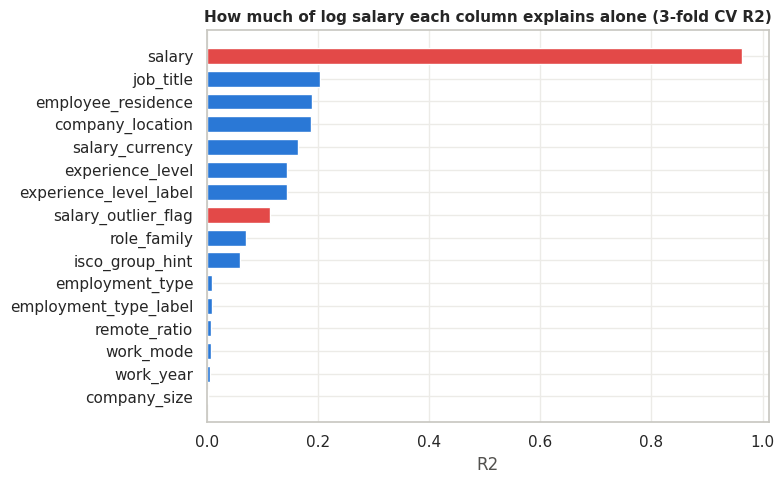

,column,single-column R2 (log salary)
4,salary,0.963
3,job_title,0.204
6,employee_residence,0.190
8,company_location,0.189
5,salary_currency,0.165
1,experience_level,0.145
10,experience_level_label,0.145
13,salary_outlier_flag,0.114
14,role_family,0.070
15,isco_group_hint,0.060


In [12]:
cand = [c for c in raw.columns if c != cfg.TARGET]
lt_rows = df.sample(min(len(df), 20000), random_state=cfg.SEED)
res = []
for c in cand:
    x = lt_rows[[c]].copy()
    if not pd.api.types.is_numeric_dtype(x[c]):
        order = lt_rows.groupby(c)["log_salary"].mean()
        x[c] = x[c].map(order)
    x = x.fillna(-1)
    r2 = cross_val_score(DecisionTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=cfg.SEED), x,
                         lt_rows["log_salary"], cv=3, scoring="r2").mean()
    res.append((c, r2))
single = pd.DataFrame(res, columns=["column", "single-column R2 (log salary)"]).sort_values("single-column R2 (log salary)", ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
colors = [PAL[7] if c in ("salary", "salary_outlier_flag") else PAL[0] for c in single["column"]]
ax.barh(single["column"][::-1], single["single-column R2 (log salary)"][::-1], color=colors[::-1], height=0.7)
ax.set(title="How much of log salary each column explains alone (3-fold CV R2)", xlabel="R2")
plt.tight_layout()
plt.show()
single.round(3)

In [13]:
leak_cols = ["salary", "salary_outlier_flag"]
legit = single[~single["column"].isin(leak_cols)].reset_index(drop=True)
s_idx = single.set_index("column").iloc[:, 0]
print("Findings:")
print(f"- salary alone: R2 {s_idx['salary']:.3f}; salary_outlier_flag alone: R2 {s_idx['salary_outlier_flag']:.3f} (both computed from the target)")
print(f"- best legitimate single column: {legit.loc[0, 'column']} (R2 {legit.iloc[0, 1]:.3f}); second: {legit.loc[1, 'column']} (R2 {legit.iloc[1, 1]:.3f})")

Findings:
- salary alone: R2 0.963; salary_outlier_flag alone: R2 0.114 (both computed from the target)
- best legitimate single column: job_title (R2 0.204); second: employee_residence (R2 0.190)


### Column decisions

Which columns are kept or dropped, and why.

In [14]:
plan = pd.DataFrame([
    ("salary", "drop", "target in local currency (leak)"),
    ("salary_outlier_flag", "drop", "threshold on the target (leak)"),
    ("experience_level_label", "drop", "one-to-one copy of experience_level"),
    ("employment_type_label", "drop", "one-to-one copy of employment_type"),
    ("work_mode", "drop", "one-to-one copy of remote_ratio"),
    ("isco_group_hint", "drop", "function of role_family (no new information)"),
    ("role_family", "keep", "manual grouping of job_title; helps rare titles"),
    ("job_title", "keep + text features", "main signal; seniority and domain words"),
    ("salary_currency", "keep", "known before the salary; marks foreign-currency contracts"),
    ("employee_residence / company_location", "keep + region", "country pay levels"),
    ("work_year, experience_level, employment_type, remote_ratio, company_size", "keep", "core profile"),
], columns=["column", "decision", "reason"])
plan

,column,decision,reason
0,salary,drop,target in local currency (leak)
1,salary_outlier_flag,drop,threshold on the target (leak)
2,experience_level_label,drop,one-to-one copy of experience_level
3,employment_type_label,drop,one-to-one copy of employment_type
4,work_mode,drop,one-to-one copy of remote_ratio
5,isco_group_hint,drop,function of role_family (no new information)
6,role_family,keep,manual grouping of job_title; helps rare titles
7,job_title,keep + text features,main signal; seniority and domain words
8,salary_currency,keep,known before the salary; marks foreign-currenc...
9,employee_residence / company_location,keep + region,country pay levels


## 6. Target: salary_in_usd

The dollar and log distributions are compared to choose the training scale, and the extremes are listed so they
can be judged. Rows are kept either way: the data is self-reported and there is no reliable rule to tell a typo from a
real outlier, training on log salary limits their pull, and section 20 measures what happens when the highest
salaries are left out of training.

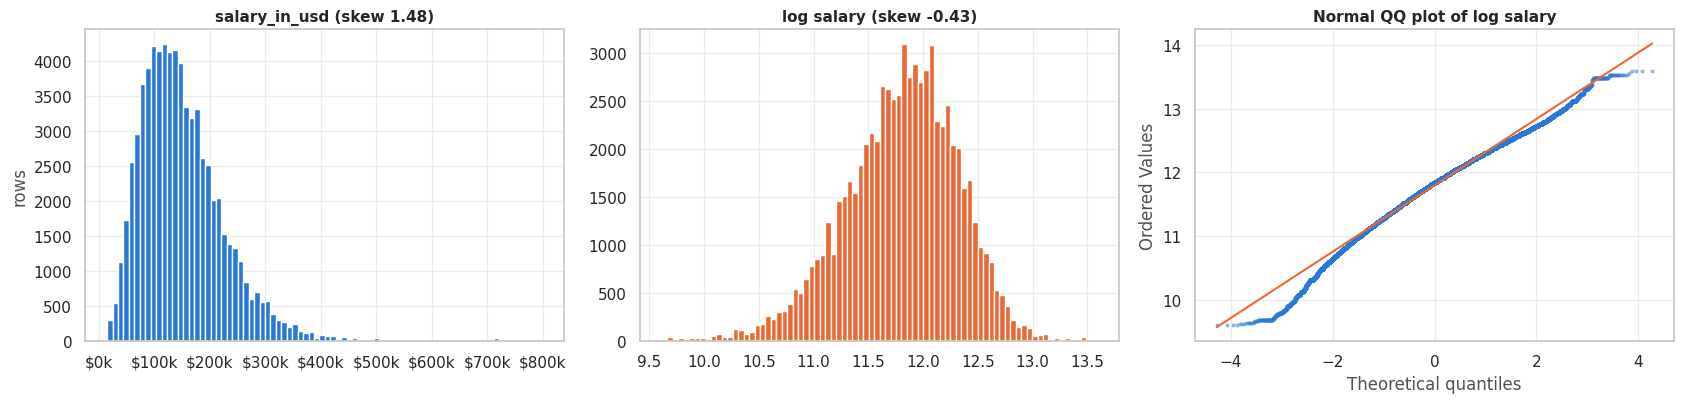

quantiles: {'0.00': '$15,000', '0.01': '$31,989', '0.05': '$53,719', '0.25': '$96,000', '0.50': '$138,750', '0.75': '$190,315', '0.95': '$290,000', '0.99': '$391,000', '1.00': '$800,000'}
mean $151,161 | median $138,750 | kurtosis 5.12
outliers: 1.5 IQR rule on dollars 2.44% | robust z > 3.5 on log salary 0.35%


In [15]:
y_all = df[cfg.TARGET]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].hist(y_all, bins=80, color=PAL[0])
ax[0].xaxis.set_major_formatter(usd)
ax[0].set(title=f"salary_in_usd (skew {y_all.skew():.2f})", ylabel="rows")
ax[1].hist(np.log(y_all), bins=80, color=PAL[1])
ax[1].set(title=f"log salary (skew {np.log(y_all).skew():.2f})")
stats.probplot(np.log(y_all), dist="norm", plot=ax[2])
ax[2].get_lines()[0].set(markersize=2, color=PAL[0], alpha=0.4)
ax[2].get_lines()[1].set(color=PAL[1])
ax[2].set(title="Normal QQ plot of log salary")
plt.tight_layout()
plt.show()
q = y_all.quantile([0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1])
print("quantiles:", {f"{k:.2f}": f"${v:,.0f}" for k, v in q.items()})
print(f"mean ${y_all.mean():,.0f} | median ${y_all.median():,.0f} | kurtosis {y_all.kurt():.2f}")
q1, q3 = y_all.quantile([0.25, 0.75])
iqr_out = ((y_all < q1 - 1.5 * (q3 - q1)) | (y_all > q3 + 1.5 * (q3 - q1))).mean()
ly = np.log(y_all)
mad = stats.median_abs_deviation(ly, scale="normal")
mad_out = (np.abs(ly - ly.median()) > 3.5 * mad).mean()
print(f"outliers: 1.5 IQR rule on dollars {100 * iqr_out:.2f}% | robust z > 3.5 on log salary {100 * mad_out:.2f}%")

In [16]:
show = ["work_year", "experience_level", "employment_type", "job_title", "company_location", "company_size", "remote_ratio", cfg.TARGET]
print("highest salaries:")
display(df.nlargest(8, cfg.TARGET)[show])
print("lowest salaries:")
display(df.nsmallest(8, cfg.TARGET)[show])
by_exp = df.groupby("experience_level")[cfg.TARGET].agg(["count", "median", "min", "max"]).loc[EXP_ORDER]
by_exp

highest salaries:


,work_year,experience_level,employment_type,job_title,company_location,company_size,remote_ratio,salary_in_usd
18840,2025,SE,FT,Architect,US,M,0,800000
29167,2025,SE,FT,Software Engineer,US,M,0,800000
64828,2024,MI,FT,AI Architect,CA,M,100,800000
35589,2025,EN,FT,Data Engineer,AT,M,0,793136
65151,2024,EN,FT,Data Analyst,MX,M,0,774000
1898,2025,SE,FT,Machine Learning Scientist,US,M,100,750000
7771,2025,SE,FT,Data Scientist,US,M,100,750000
10111,2025,MI,FT,Software Engineer,US,M,0,750000


lowest salaries:


,work_year,experience_level,employment_type,job_title,company_location,company_size,remote_ratio,salary_in_usd
68966,2022,MI,FT,Business Intelligence Developer,GH,M,100,15000
69934,2020,EX,FT,Staff Data Analyst,CA,M,0,15000
71213,2021,EN,FT,Machine Learning Developer,TH,L,100,15000
71417,2022,EN,FT,Data Analyst,ID,L,0,15000
50079,2024,EN,FT,BI Analyst,PH,M,100,15107
60142,2022,EN,FT,Software Development Engineer,RO,L,50,15129
32664,2025,EN,FT,Data Analyst,FR,M,0,15157
19181,2025,EN,FT,Algorithm Developer,TW,M,0,15281


,count,median,min,max
experience_level,,,,
EN,7975,85469.0,15000,793136
MI,23395,122000.0,15000,800000
SE,37702,156160.0,15645,800000
EX,2841,190000.0,15000,625000


In [17]:
yv = df[cfg.TARGET]
doubt = df[((df["experience_level"] == "EN") & (yv >= 500_000)) | ((df["experience_level"] == "EX") & (yv <= 30_000))]
print("Findings:")
print(f"- skew: dollars {yv.skew():.2f}, log salary {np.log(yv).skew():.2f}")
print(f"- doubtful extremes (entry level at $500k or more, or executive at $30k or less): {len(doubt)} rows "
      f"({100 * len(doubt) / len(df):.2f}%), kept")
doubt[["work_year", "experience_level", "job_title", "company_location", cfg.TARGET]].head(6)

Findings:
- skew: dollars 1.48, log salary -0.43
- doubtful extremes (entry level at $500k or more, or executive at $30k or less): 13 rows (0.02%), kept


,work_year,experience_level,job_title,company_location,salary_in_usd
9597,2025,EX,Data Governance,US,30000
14807,2025,EX,Data Scientist,ES,27368
15501,2025,EX,Engineer,US,20538
17310,2025,EN,Engineering Manager,US,560000
31890,2025,EX,Head of Data,US,25000
33279,2025,EN,Data Analyst,US,634000


## 7. Features one at a time

Category counts show how much data each group has. Groups with few rows are where a model has to borrow strength
from related groups (shrinkage, role families, regions, title words); section 12 turns them into a list for the bias
audit.

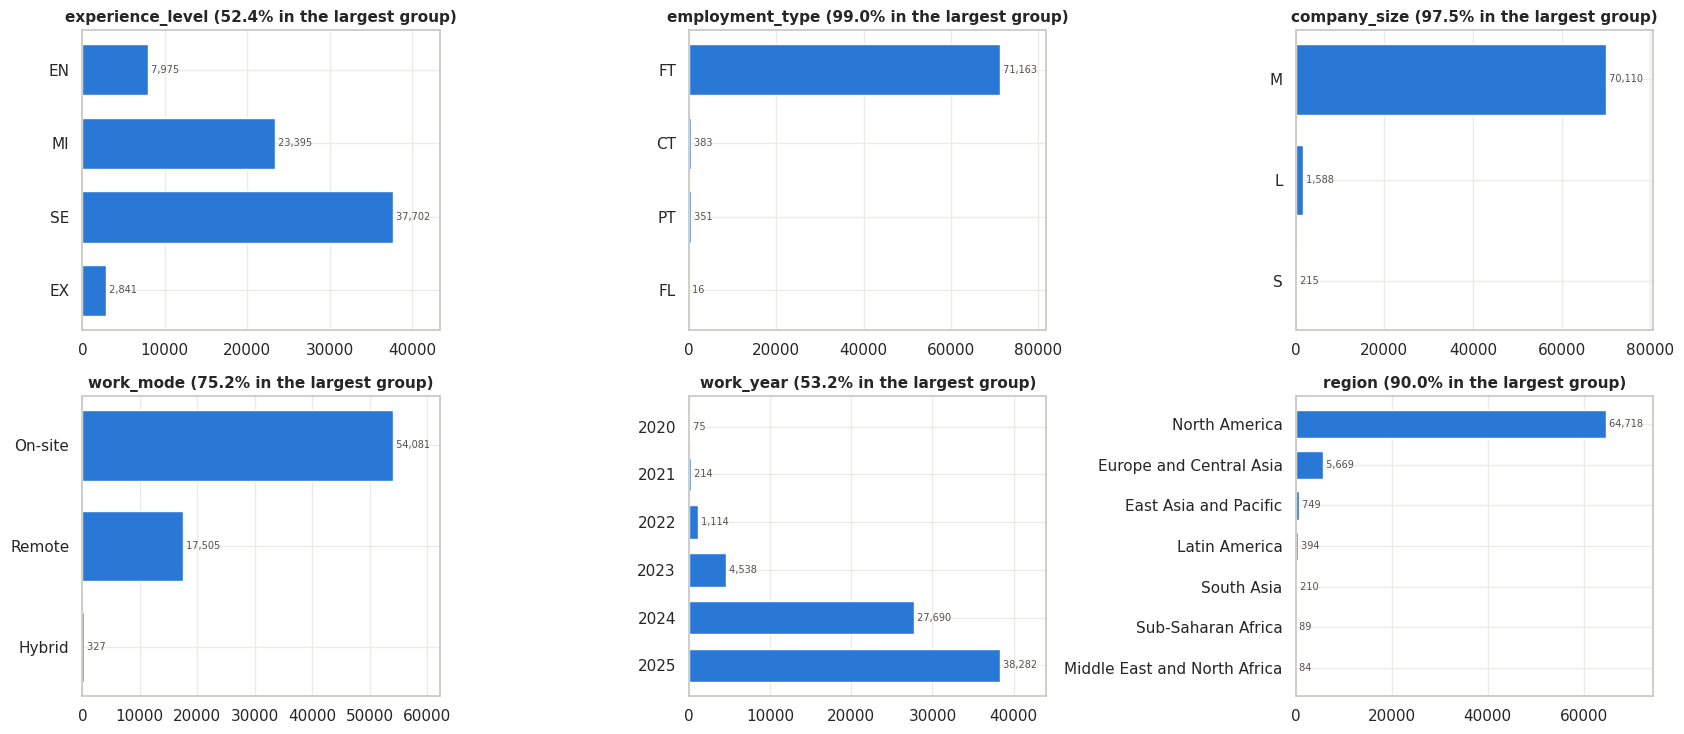

In [18]:
low_card = ["experience_level", "employment_type", "company_size", "work_mode", "work_year", "region"]
fig, axes = plt.subplots(2, 3, figsize=(17, 7.5))
for ax, c in zip(axes.ravel(), low_card):
    vc = df[c].value_counts()
    if c == "experience_level":
        vc = vc.reindex(EXP_ORDER)
    elif c == "work_year":
        vc = vc.sort_index()
    hbar(ax, vc.index.astype(str).tolist(), vc.values)
    ax.set_title(f"{c} ({100 * vc.max() / vc.sum():.1f}% in the largest group)")
plt.tight_layout()
plt.show()

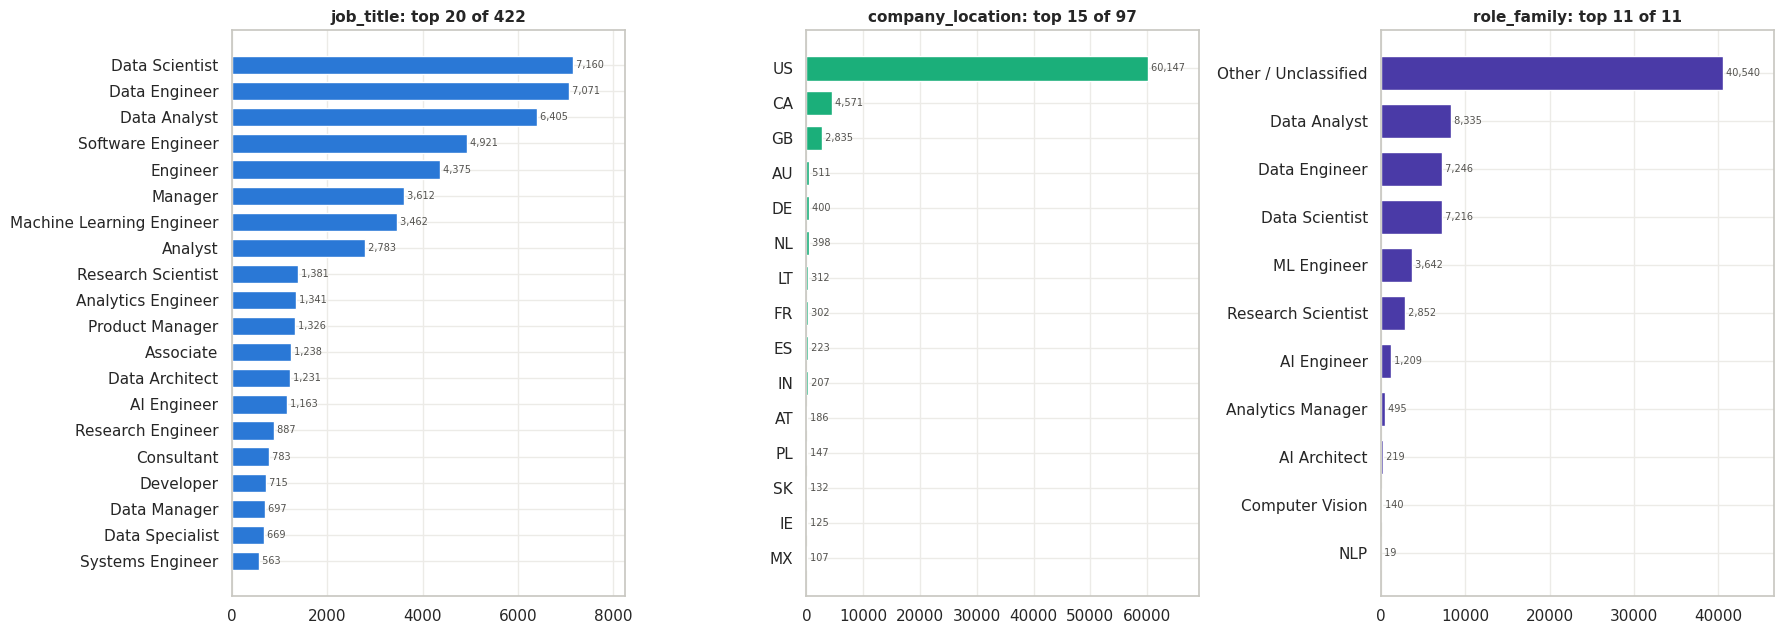

,column,categories,categories with < 30 rows,rows in those categories %,top-10 share %
0,job_title,422,271,2.69,59.1
1,employee_residence,104,74,0.68,97.1
2,company_location,97,67,0.63,97.2
3,salary_currency,26,18,0.20,99.9


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, c, n in zip(axes, ["job_title", "company_location", "role_family"], [20, 15, 11]):
    vc = df[c].value_counts().head(n)
    hbar(ax, vc.index.tolist(), vc.values, color=PAL[[0, 2, 6][["job_title", "company_location", "role_family"].index(c)]])
    ax.set_title(f"{c}: top {n} of {df[c].nunique()}")
plt.tight_layout()
plt.show()
tail = []
for c in ["job_title", "employee_residence", "company_location", "salary_currency"]:
    vc = df[c].value_counts()
    tail.append({"column": c, "categories": len(vc), "categories with < 30 rows": int((vc < 30).sum()),
                 "rows in those categories %": round(100 * vc[vc < 30].sum() / len(df), 2),
                 "top-10 share %": round(100 * vc.head(10).sum() / len(df), 1)})
pd.DataFrame(tail)

In [20]:
print("Findings: share of the largest group per column")
for c in low_card + ["company_location", "job_title"]:
    vc = df[c].value_counts(normalize=True)
    print(f"- {c}: {vc.index[0]} {100 * vc.iloc[0]:.1f}% | {df[c].nunique()} categories")

Findings: share of the largest group per column
- experience_level: SE 52.4% | 4 categories
- employment_type: FT 99.0% | 4 categories
- company_size: M 97.5% | 3 categories
- work_mode: On-site 75.2% | 3 categories
- work_year: 2025 53.2% | 6 categories
- region: North America 90.0% | 7 categories
- company_location: US 83.6% | 97 categories
- job_title: Data Scientist 10.0% | 422 categories


## 8. Salary against each feature

Medians with bootstrap 95% intervals, so small groups show their uncertainty.

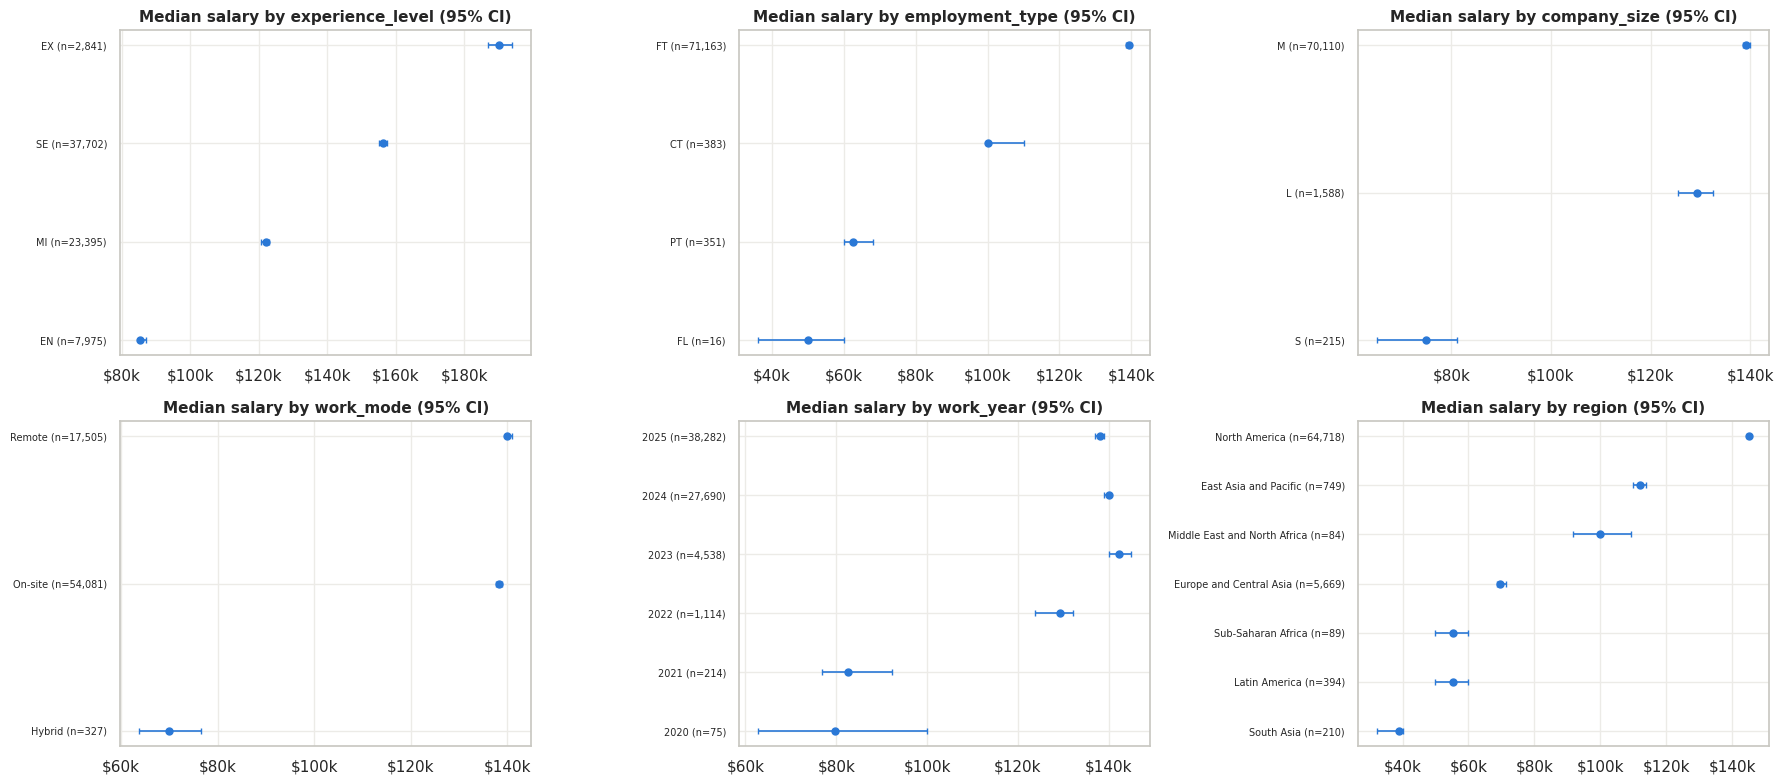

In [21]:
def median_panel(ax, col, order=None, top=None, color=PAL[0]):
    g = df.groupby(col)[cfg.TARGET]
    med = g.median()
    cnt = g.size()
    keys = order if order is not None else (cnt.sort_values(ascending=False).head(top).index if top else med.index)
    keys = [k for k in keys if k in med.index]
    keys = sorted(keys, key=lambda k: med[k]) if order is None else keys
    lo, hi = zip(*[median_ci(df.loc[df[col] == k, cfg.TARGET].values) for k in keys])
    yv = np.arange(len(keys))
    ax.errorbar([med[k] for k in keys], yv, xerr=[np.array([med[k] for k in keys]) - np.array(lo),
                np.array(hi) - np.array([med[k] for k in keys])], fmt="o", color=color, ms=5, capsize=2, lw=1.2)
    ax.set_yticks(yv)
    ax.set_yticklabels([f"{k} (n={cnt[k]:,})" for k in keys], fontsize=7)
    ax.xaxis.set_major_formatter(usd)
    ax.set_title(f"Median salary by {col} (95% CI)")


fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, c in zip(axes.ravel(), ["experience_level", "employment_type", "company_size", "work_mode", "work_year", "region"]):
    median_panel(ax, c, order=EXP_ORDER if c == "experience_level" else (sorted(df[c].unique()) if c == "work_year" else None))
plt.tight_layout()
plt.show()

### Confounding check

A median per group can mix in other columns: a group that is rarely based in the US will look low-paid even if the
column itself has no effect. The table below checks this confounding by comparing each group's US share and its median
inside the US only.

In [22]:
us_share = 100 * (df["company_location"] == "US").mean()
conf = []
for col in ["company_size", "work_mode", "employment_type"]:
    for g, sub in df.groupby(col):
        in_us = sub["company_location"] == "US"
        conf.append({"column": col, "group": g, "rows": len(sub), "US share %": round(100 * in_us.mean(), 1),
                     "median (all)": sub[cfg.TARGET].median(), "median (US only)": sub.loc[in_us, cfg.TARGET].median()})
conf = pd.DataFrame(conf)
mixed = conf[(conf["US share %"] - us_share).abs() > 20]
print(f"Findings: overall US share {us_share:.1f}%. Groups whose US share differs by more than 20 points, so their overall "
      "median mixes in a country effect:", list(zip(mixed["column"], mixed["group"])) or "none")
conf

Findings: overall US share 83.6%. Groups whose US share differs by more than 20 points, so their overall median mixes in a country effect: [('company_size', 'S'), ('work_mode', 'Hybrid'), ('employment_type', 'FL')]


,column,group,rows,US share %,median (all),median (US only)
0,company_size,L,1588,78.0,129300.0,144000.0
1,company_size,M,70110,83.9,139200.0,147400.0
2,company_size,S,215,34.9,75000.0,110000.0
3,work_mode,Hybrid,327,17.1,69999.0,115000.0
4,work_mode,On-site,54081,83.6,138300.0,148000.0
5,work_mode,Remote,17505,85.0,140000.0,145590.0
6,employment_type,CT,383,67.4,100000.0,120000.0
7,employment_type,FL,16,25.0,50000.0,55000.0
8,employment_type,FT,71163,83.8,139300.0,148000.0
9,employment_type,PT,351,76.9,62400.0,68000.0


### Job titles, countries and role families

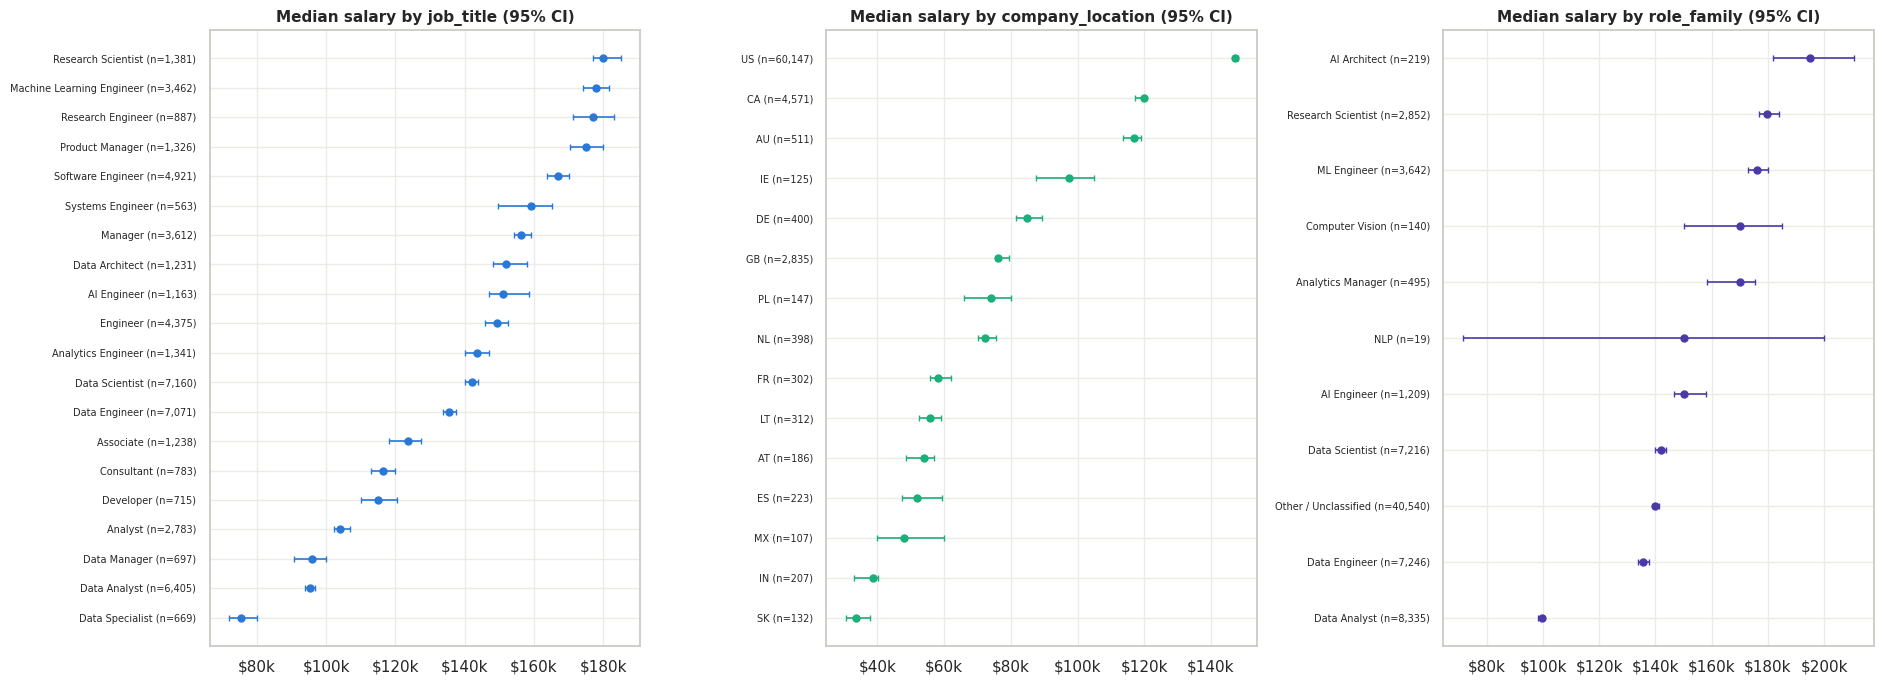

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(19, 7))
median_panel(axes[0], "job_title", top=20, color=PAL[0])
median_panel(axes[1], "company_location", top=15, color=PAL[2])
median_panel(axes[2], "role_family", color=PAL[6])
plt.tight_layout()
plt.show()

### Two-way medians

Two-way medians show whether the effect of one column holds inside the levels of another.

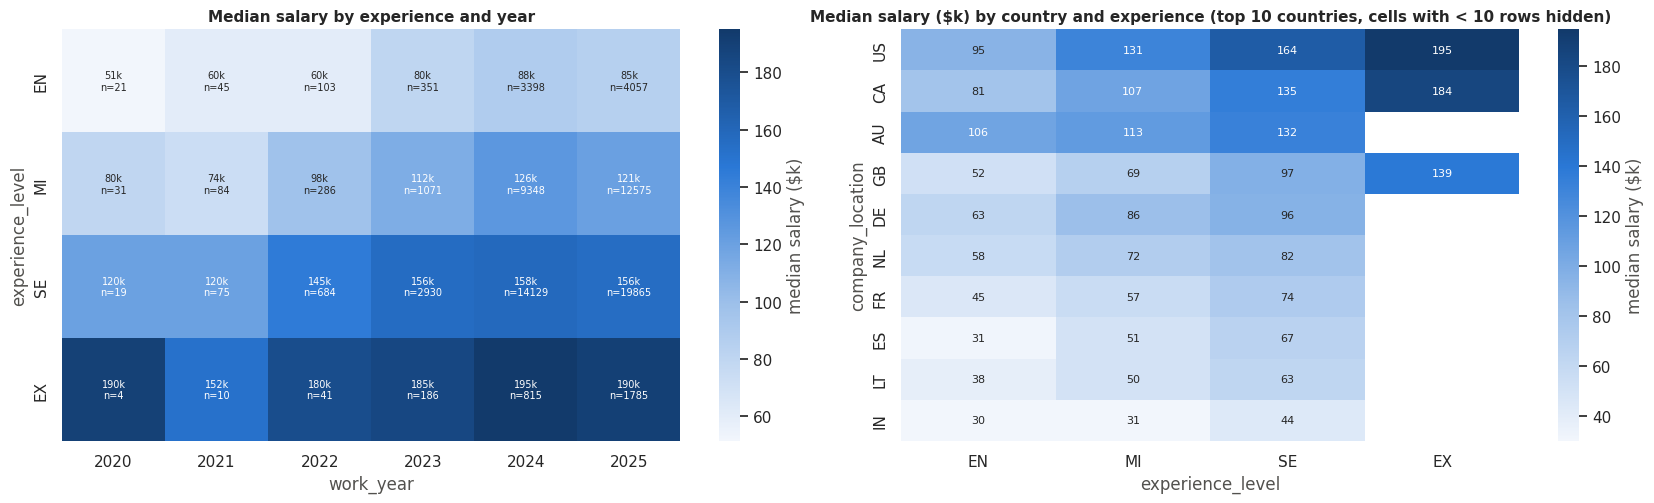

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5.2))
h1 = df.pivot_table(index="experience_level", columns="work_year", values=cfg.TARGET, aggfunc="median").loc[EXP_ORDER]
n1 = df.pivot_table(index="experience_level", columns="work_year", values=cfg.TARGET, aggfunc="size").loc[EXP_ORDER]
sns.heatmap(h1 / 1000, annot=(h1 / 1000).round(0).astype("Int64").astype(str) + "k\nn=" + n1.fillna(0).astype(int).astype(str),
            fmt="", cmap=SEQ, ax=ax[0], cbar_kws={"label": "median salary ($k)"}, annot_kws={"fontsize": 7})
ax[0].set_title("Median salary by experience and year")
top_loc = df["company_location"].value_counts().head(10).index
sub_loc = df[df["company_location"].isin(top_loc)]
h2 = sub_loc.pivot_table(index="company_location", columns="experience_level", values=cfg.TARGET, aggfunc="median")[EXP_ORDER]
n2 = sub_loc.pivot_table(index="company_location", columns="experience_level", values=cfg.TARGET, aggfunc="size")[EXP_ORDER]
h2 = h2.where(n2 >= 10)
h2 = h2.loc[h2["SE"].sort_values(ascending=False).index]
sns.heatmap(h2 / 1000, annot=True, fmt=".0f", cmap=SEQ, ax=ax[1], cbar_kws={"label": "median salary ($k)"}, annot_kws={"fontsize": 8})
ax[1].set_title("Median salary ($k) by country and experience (top 10 countries, cells with < 10 rows hidden)")
for a in ax:
    a.grid(False)
plt.tight_layout()
plt.show()

In [25]:
print("Findings:")
print("- year with the highest median, per experience level:", h1.idxmax(axis=1).to_dict())
top_by_level = h2.dropna(axis=1, how="all").idxmax(axis=0).to_dict()
print("- country with the highest median per experience level (top 10 countries, cells with 10+ rows):", top_by_level)

Findings:
- year with the highest median, per experience level: {'EN': 2024, 'MI': 2024, 'SE': 2024, 'EX': 2024}
- country with the highest median per experience level (top 10 countries, cells with 10+ rows): {'EN': 'AU', 'MI': 'US', 'SE': 'US', 'EX': 'US'}


### Words in the job title

Words such as "senior" or "research" are shared across hundreds of rare titles. Measuring their pay effect here shows
whether they are worth turning into features, so that rare titles can borrow information from common ones.

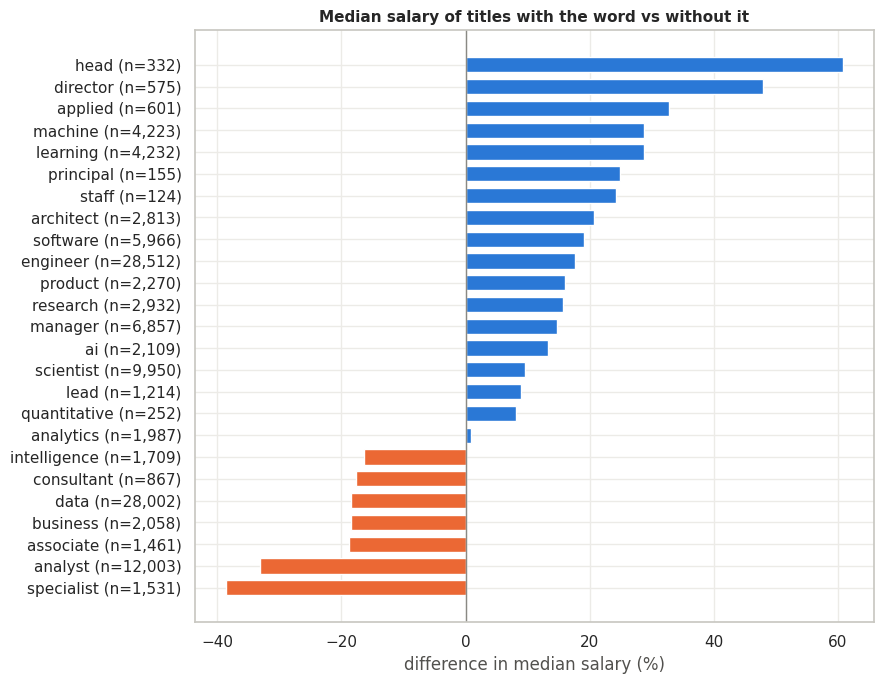

In [26]:
WORDS = ["intern", "junior", "associate", "senior", "lead", "staff", "principal", "head", "director", "manager", "vp",
         "machine", "learning", "ai", "research", "scientist", "engineer", "analyst", "analytics", "architect",
         "software", "business", "intelligence", "data", "applied", "quantitative", "product", "consultant", "specialist"]
title_words = df["job_title"].str.lower().str.findall(r"[a-z]+")
rows_kw = []
for w in WORDS:
    has = title_words.map(lambda t: w in t)
    if has.sum() >= 30:
        rows_kw.append((w, int(has.sum()), df.loc[has, "log_salary"].median() - df.loc[~has, "log_salary"].median()))
kw = pd.DataFrame(rows_kw, columns=["word", "rows", "log_gap"]).sort_values("log_gap")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh([f"{w} (n={n:,})" for w, n in zip(kw["word"], kw["rows"])], 100 * (np.exp(kw["log_gap"]) - 1),
        color=[PAL[1] if v < 0 else PAL[0] for v in kw["log_gap"]], height=0.7)
ax.axvline(0, color=GREY, lw=1)
ax.set(title="Median salary of titles with the word vs without it", xlabel="difference in median salary (%)")
plt.tight_layout()
plt.show()

In [27]:
up = kw.sort_values("log_gap", ascending=False).head(4)
down = kw.sort_values("log_gap").head(4)
print("Findings:")
print("- largest premiums:", {w: f"{100 * (np.exp(g) - 1):+.0f}%" for w, g in zip(up["word"], up["log_gap"])})
print("- largest discounts:", {w: f"{100 * (np.exp(g) - 1):+.0f}%" for w, g in zip(down["word"], down["log_gap"])})

Findings:
- largest premiums: {'head': '+61%', 'director': '+48%', 'applied': '+33%', 'learning': '+29%'}
- largest discounts: {'specialist': '-39%', 'analyst': '-33%', 'associate': '-19%', 'business': '-18%'}


## 9. Statistics: effect sizes and associations

Kruskal-Wallis tests whether log salary differs across the levels of a feature; epsilon squared is its effect size
(the share of rank variance explained). With tens of thousands of rows almost every p-value is tiny, so the effect size is
what matters.

In [28]:
feat_cols = ["experience_level", "employment_type", "job_title", "salary_currency", "employee_residence", "remote_ratio",
             "company_location", "company_size", "work_year", "role_family", "region"]
rows_kw = []
for c in feat_cols:
    groups = [g.values for _, g in df.groupby(c)["log_salary"] if len(g) >= 5]
    h, p = stats.kruskal(*groups)
    k, n = len(groups), sum(len(g) for g in groups)
    rows_kw.append((c, df[c].nunique(), h, p, max(0.0, (h - k + 1) / (n - k))))
kw_tab = pd.DataFrame(rows_kw, columns=["feature", "levels", "H", "p_value", "epsilon_sq"]).sort_values("epsilon_sq", ascending=False)
kw_tab["effect"] = pd.cut(kw_tab["epsilon_sq"], [-1, 0.01, 0.06, 0.14, 2], labels=["negligible", "small", "medium", "large"])
kw_tab.round({"H": 0, "epsilon_sq": 4})

,feature,levels,H,p_value,epsilon_sq,effect
2,job_title,422,14381.0,0.000000e+00,0.1977,large
0,experience_level,4,10011.0,0.000000e+00,0.1392,medium
4,employee_residence,104,9192.0,0.000000e+00,0.1271,medium
6,company_location,97,9046.0,0.000000e+00,0.1251,medium
3,salary_currency,26,8333.0,0.000000e+00,0.1157,medium
10,region,7,7905.0,0.000000e+00,0.1098,medium
9,role_family,11,5234.0,0.000000e+00,0.0727,medium
1,employment_type,4,600.0,1.231682e-129,0.0083,negligible
5,remote_ratio,3,365.0,4.786820e-80,0.0051,negligible
8,work_year,6,240.0,8.487711e-50,0.0033,negligible


In [29]:
print("Findings: largest effect sizes (epsilon squared):",
      [(f, round(e, 3)) for f, e in zip(kw_tab["feature"].head(4), kw_tab["epsilon_sq"].head(4))])

Findings: largest effect sizes (epsilon squared): [('job_title', 0.198), ('experience_level', 0.139), ('employee_residence', 0.127), ('company_location', 0.125)]


### Associations between columns

Cramer's V measures how tied two categorical columns are (1 = one is a copy of the other). Strong ties do not hurt
tree models, but they matter for reading feature importance, which gets split between related columns.

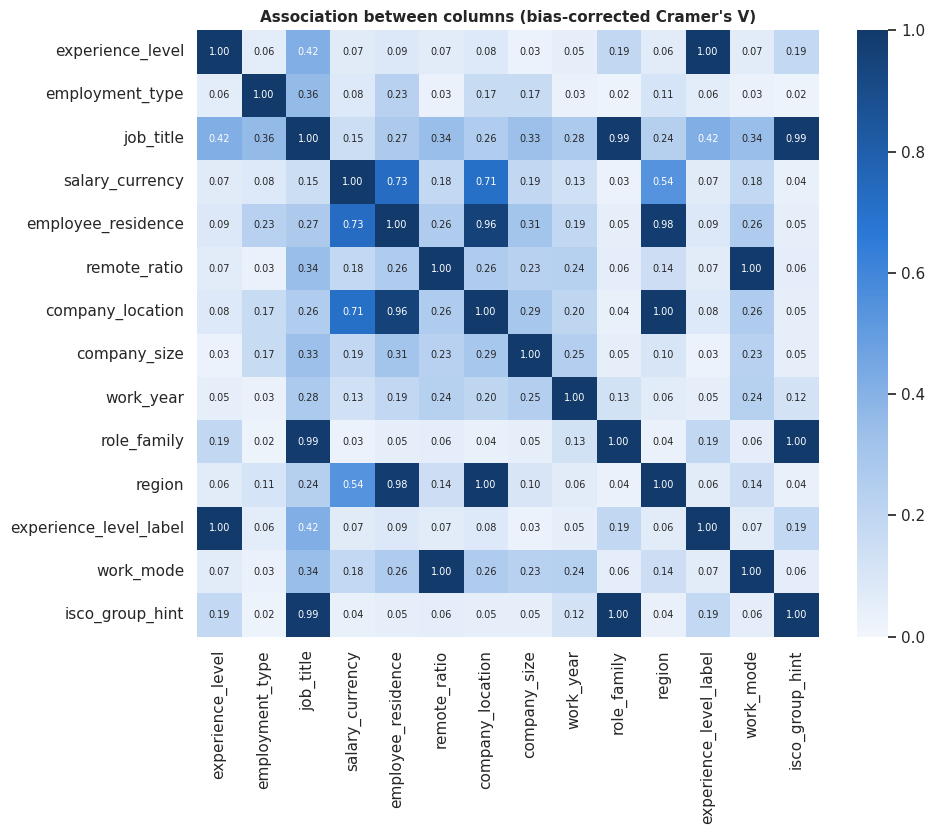

mutual information with log salary (nats): {'employee_residence': 0.239, 'company_location': 0.237, 'salary_currency': 0.209, 'job_title': 0.205, 'region': 0.173, 'experience_level': 0.129, 'work_year': 0.09, 'role_family': 0.084, 'remote_ratio': 0.052, 'company_size': 0.025, 'employment_type': 0.013}


In [30]:
cv_cols = feat_cols + ["experience_level_label", "work_mode", "isco_group_hint"]
sample_cv = df.sample(min(len(df), 20000), random_state=cfg.SEED).fillna({"isco_group_hint": "none"})
cvm = pd.DataFrame(np.eye(len(cv_cols)), index=cv_cols, columns=cv_cols)
for i, a in enumerate(cv_cols):
    for b in cv_cols[i + 1:]:
        cvm.loc[a, b] = cvm.loc[b, a] = cramers_v(sample_cv[a], sample_cv[b])
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(cvm, annot=True, fmt=".2f", cmap=SEQ, vmin=0, vmax=1, ax=ax, annot_kws={"fontsize": 7})
ax.set_title("Association between columns (bias-corrected Cramer's V)")
plt.tight_layout()
plt.show()
X_mi = df[feat_cols].apply(lambda s: s.astype("category").cat.codes)
mi = pd.Series(mutual_info_regression(X_mi, df["log_salary"], discrete_features=True, random_state=cfg.SEED),
               index=feat_cols).sort_values(ascending=False)
print("mutual information with log salary (nats):", mi.round(3).to_dict())

In [31]:
pairs = sorted(((a, b, round(float(cvm.loc[a, b]), 2)) for i, a in enumerate(cvm.index) for b in cvm.index[i + 1:]
                if cvm.loc[a, b] >= 0.7), key=lambda t: -t[2])
print("Findings: column pairs with Cramer's V of 0.7 or more:")
for p in pairs:
    print("-", p)
print("- highest mutual information with log salary:", mi.head(4).round(3).to_dict())

Findings: column pairs with Cramer's V of 0.7 or more:
- ('experience_level', 'experience_level_label', 1.0)
- ('remote_ratio', 'work_mode', 1.0)
- ('company_location', 'region', 1.0)
- ('role_family', 'isco_group_hint', 1.0)
- ('job_title', 'role_family', 0.99)
- ('job_title', 'isco_group_hint', 0.99)
- ('employee_residence', 'region', 0.98)
- ('employee_residence', 'company_location', 0.96)
- ('salary_currency', 'employee_residence', 0.73)
- ('salary_currency', 'company_location', 0.71)
- highest mutual information with log salary: {'employee_residence': 0.239, 'company_location': 0.237, 'salary_currency': 0.209, 'job_title': 0.205}


## 10. Change over time

The overall median can move differently from the medians inside each experience level when the mix of levels or
countries changes between years (a Simpson's paradox pattern), so both are compared. The adversarial check trains a
classifier to tell the latest year from earlier years using the profile columns alone: an AUC near 0.5 means the years
look alike. Section 20 tests the model on a strict time split for this reason.

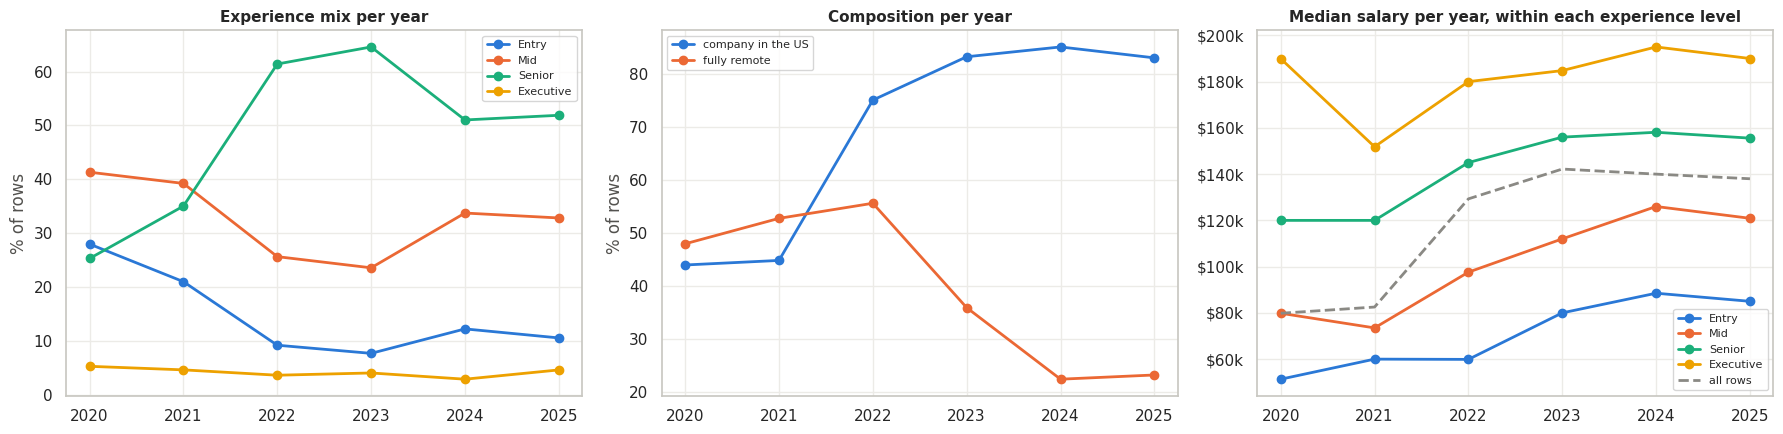

rows per year: {2020: 75, 2021: 214, 2022: 1114, 2023: 4538, 2024: 27690, 2025: 38282}


In [32]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
mix = pd.crosstab(df["work_year"], df["experience_level"], normalize="index")[EXP_ORDER]
for i, e in enumerate(EXP_ORDER):
    ax[0].plot(mix.index, 100 * mix[e], marker="o", color=PAL[i], lw=2, label=EXP_NAME[e])
ax[0].set(title="Experience mix per year", ylabel="% of rows")
ax[0].legend(fontsize=8)
share = df.groupby("work_year").agg(us=("company_location", lambda s: 100 * (s == "US").mean()),
                                    remote=("remote_ratio", lambda s: 100 * (s == 100).mean()))
ax[1].plot(share.index, share["us"], marker="o", color=PAL[0], lw=2, label="company in the US")
ax[1].plot(share.index, share["remote"], marker="o", color=PAL[1], lw=2, label="fully remote")
ax[1].set(title="Composition per year", ylabel="% of rows")
ax[1].legend(fontsize=8)
med = df.groupby(["work_year", "experience_level"])[cfg.TARGET].median().unstack()[EXP_ORDER]
for i, e in enumerate(EXP_ORDER):
    ax[2].plot(med.index, med[e], marker="o", color=PAL[i], lw=2, label=EXP_NAME[e])
ax[2].plot(med.index, df.groupby("work_year")[cfg.TARGET].median(), color=GREY, lw=2, ls="--", label="all rows")
ax[2].yaxis.set_major_formatter(usd)
ax[2].set(title="Median salary per year, within each experience level")
ax[2].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("rows per year:", df["work_year"].value_counts().sort_index().to_dict())

In [33]:
adv_cols = ["experience_level", "employment_type", "job_title", "salary_currency", "employee_residence", "remote_ratio",
            "company_location", "company_size"]
Xa = df[adv_cols].astype("category")
ya = (df["work_year"] == df["work_year"].max()).astype(int)
aucs, imps = [], []
for a, b in StratifiedKFold(3, shuffle=True, random_state=cfg.SEED).split(Xa, ya):
    clf = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=31, verbose=-1, random_state=cfg.SEED)
    clf.fit(Xa.iloc[a], ya.iloc[a])
    aucs.append(roc_auc_score(ya.iloc[b], clf.predict_proba(Xa.iloc[b])[:, 1]))
    imps.append(pd.Series(clf.booster_.feature_importance("gain"), index=adv_cols))
print(f"adversarial validation, latest year vs earlier years: AUC {np.mean(aucs):.3f} (0.5 = same distribution)")
print("columns that separate the years most:", (pd.concat(imps, axis=1).mean(axis=1) / pd.concat(imps, axis=1).mean(axis=1).sum()).sort_values(ascending=False).head(4).round(3).to_dict())

adversarial validation, latest year vs earlier years: AUC 0.672 (0.5 = same distribution)
columns that separate the years most: {'job_title': 0.743, 'remote_ratio': 0.058, 'employee_residence': 0.055, 'company_size': 0.055}


In [34]:
counts = df["work_year"].value_counts().sort_index()
big_years = sorted(counts[counts >= min(1000, counts.nlargest(2).min())].index)
y0, y1 = big_years[0], big_years[-1]
overall = df.groupby("work_year")[cfg.TARGET].median()
print("Findings:")
print(f"- years with fewer than 1,000 rows (noisy medians): {sorted(counts[counts < 1000].index.tolist())}")
print(f"- {y0} to {y1}: overall median {overall[y0]:,.0f} -> {overall[y1]:,.0f} ({100 * (overall[y1] / overall[y0] - 1):+.1f}%); "
      "inside each level:", {e: f"{100 * (med.loc[y1, e] / med.loc[y0, e] - 1):+.1f}%" for e in EXP_ORDER})
print(f"- adversarial AUC, latest year vs earlier years: {np.mean(aucs):.3f}")

Findings:
- years with fewer than 1,000 rows (noisy medians): [2020, 2021]
- 2022 to 2025: overall median 129,300 -> 138,000 (+6.7%); inside each level: {'EN': '+41.9%', 'MI': '+23.9%', 'SE': '+7.3%', 'EX': '+5.6%'}
- adversarial AUC, latest year vs earlier years: 0.672


## 11. Noise ceiling: how much can any model explain?

Rows with exactly the same profile (year, title, experience, country, currency, company size, remote ratio,
contract) can still earn different salaries, and no column can separate them. The oracle R2 predicts each row with the
mean of its own profile using the true salaries of the rows it scores, so no honest model can reach it. The leave-one-out
profile mean is what memorising profiles gives on new rows. A model that shares information between similar profiles
should land between the two; a claim of near-perfect accuracy on this table would point to leakage.

sd of log salary: all rows 0.523 | within identical profiles 0.370
oracle R2 (each row predicted by the mean of its own profile, target included): log 0.499 | dollars 0.357
leave-one-out profile mean on rows whose profile repeats (98.4% of rows): R2 dollars 0.270


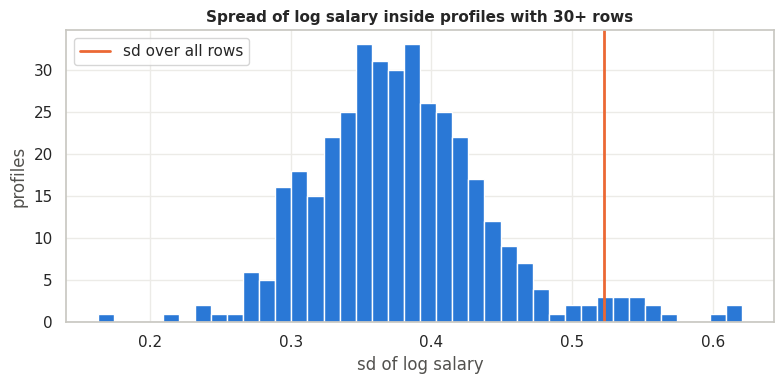

In [35]:
g = df.groupby(PROFILE)["log_salary"]
within_sd = np.sqrt(np.average(g.var(ddof=0).values, weights=g.size().values))
oracle_log = g.transform("mean")
oracle_usd = df.groupby(PROFILE)[cfg.TARGET].transform("mean")
size = g.transform("size")
multi = size > 1
loo_usd = (df.groupby(PROFILE)[cfg.TARGET].transform("sum") - df[cfg.TARGET]) / (size - 1)
print(f"sd of log salary: all rows {df['log_salary'].std():.3f} | within identical profiles {within_sd:.3f}")
print(f"oracle R2 (each row predicted by the mean of its own profile, target included): "
      f"log {r2_score(df['log_salary'], oracle_log):.3f} | dollars {r2_score(df[cfg.TARGET], oracle_usd):.3f}")
print(f"leave-one-out profile mean on rows whose profile repeats ({100 * multi.mean():.1f}% of rows): "
      f"R2 dollars {r2_score(df.loc[multi, cfg.TARGET], loo_usd[multi]):.3f}")
fig, ax = plt.subplots(figsize=(8, 4))
big = g.size() >= 30
ax.hist(g.std()[big], bins=40, color=PAL[0])
ax.axvline(df["log_salary"].std(), color=PAL[1], lw=2, label="sd over all rows")
ax.set(title="Spread of log salary inside profiles with 30+ rows", xlabel="sd of log salary", ylabel="profiles")
ax.legend()
plt.tight_layout()
plt.show()
CEILING_R2 = r2_score(df[cfg.TARGET], oracle_usd)

In [36]:
loo_r2 = r2_score(df.loc[multi, cfg.TARGET], loo_usd[multi])
print(f"Findings: sd of log salary inside identical profiles is {within_sd:.3f} vs {df['log_salary'].std():.3f} overall; "
      f"an honest model should land between the leave-one-out profile mean (R2 {loo_r2:.3f}) and the oracle (R2 {CEILING_R2:.3f}).")

Findings: sd of log salary inside identical profiles is 0.370 vs 0.523 overall; an honest model should land between the leave-one-out profile mean (R2 0.270) and the oracle (R2 0.357).


## 12. Representation audit

The data has no protected attributes (gender, age, ethnicity), so bias here means that the model is systematically
less accurate, or systematically too high or too low, for some groups of jobs or places. Thin groups are where this is
most likely; section 21 measures it on the test set.

In [37]:
audit_cols = ["experience_level", "employment_type", "company_size", "work_mode", "region", "work_year"]
rep = []
for c in audit_cols:
    vc = df[c].value_counts()
    for k, n in vc.items():
        rep.append({"attribute": c, "group": k, "rows": n, "share %": round(100 * n / len(df), 2),
                    "median salary": df.loc[df[c] == k, cfg.TARGET].median()})
rep = pd.DataFrame(rep)
rep["thin (< 1%)"] = rep["share %"] < 1
print(f"{rep['thin (< 1%)'].sum()} of {len(rep)} groups hold less than 1% of the rows each.")
rep.sort_values(["attribute", "rows"], ascending=[True, False]).reset_index(drop=True)

11 of 27 groups hold less than 1% of the rows each.


,attribute,group,rows,share %,median salary,thin (< 1%)
0,company_size,M,70110,97.49,139200.0,False
1,company_size,L,1588,2.21,129300.0,False
2,company_size,S,215,0.30,75000.0,True
3,employment_type,FT,71163,98.96,139300.0,False
4,employment_type,CT,383,0.53,100000.0,True
5,employment_type,PT,351,0.49,62400.0,True
6,employment_type,FL,16,0.02,50000.0,True
7,experience_level,SE,37702,52.43,156160.0,False
8,experience_level,MI,23395,32.53,122000.0,False
9,experience_level,EN,7975,11.09,85469.0,False


In [38]:
thin = rep[rep["thin (< 1%)"]]
print("Findings: groups holding less than 1% of the rows:")
for attr, groups in thin.groupby("attribute")["group"]:
    print(f"- {attr}: {list(groups)}")

Findings: groups holding less than 1% of the rows:
- company_size: ['S']
- employment_type: ['CT', 'PT', 'FL']
- region: ['Latin America', 'South Asia', 'Sub-Saharan Africa', 'Middle East and North Africa']
- work_mode: ['Hybrid']
- work_year: [2021, 2020]


## 13. From EDA to modelling decisions

Each modelling choice below cites the evidence found above.

In [39]:
decisions = pd.DataFrame([
    ("Drop salary and salary_outlier_flag", "both are functions of the target (section 5)"),
    ("Drop the label copies, work_mode and isco_group_hint", f"one-to-one or functional copies (section 4, Cramer's V = 1)"),
    ("Train on log salary, report dollars", f"target skew {df[cfg.TARGET].skew():.2f} vs log skew {df['log_salary'].skew():.2f} (section 6)"),
    ("Correct the log back-transform bias", "exp(mean log) is below the mean; a smearing factor restores the dollar mean"),
    ("Shrunk target encodings fitted inside folds", f"{df['job_title'].nunique()} titles and {df['company_location'].nunique()} countries, many with < 30 rows (section 7)"),
    ("Title words, role family and region as features", "shared signal across rare titles and countries (sections 7 and 8)"),
    ("Keep all rows, no outlier removal", "extremes cannot be verified; log target limits their pull (sections 6 and 20)"),
    ("Headline metrics R2, MAE, RMSE in dollars", f"interpretable; the ceiling is about R2 {CEILING_R2:.2f} (section 11)"),
    ("Time split and repeated splits as robustness checks", f"adversarial AUC between years {np.mean(aucs):.2f} (section 10)"),
    ("Bias audit on thin groups", f"{rep['thin (< 1%)'].sum()} groups under 1% of rows (section 12)"),
], columns=["decision", "evidence"])
decisions

,decision,evidence
0,Drop salary and salary_outlier_flag,both are functions of the target (section 5)
1,"Drop the label copies, work_mode and isco_grou...","one-to-one or functional copies (section 4, Cr..."
2,"Train on log salary, report dollars",target skew 1.48 vs log skew -0.43 (section 6)
3,Correct the log back-transform bias,exp(mean log) is below the mean; a smearing fa...
4,Shrunk target encodings fitted inside folds,"422 titles and 97 countries, many with < 30 ro..."
5,"Title words, role family and region as features",shared signal across rare titles and countries...
6,"Keep all rows, no outlier removal",extremes cannot be verified; log target limits...
7,"Headline metrics R2, MAE, RMSE in dollars",interpretable; the ceiling is about R2 0.36 (s...
8,Time split and repeated splits as robustness c...,adversarial AUC between years 0.67 (section 10)
9,Bias audit on thin groups,11 groups under 1% of rows (section 12)


## 14. Train/test split and cross-validation folds

20% of rows are held out and scored once at the end. Every model choice (features, parameters, blend weights, bias fixes) uses 5-fold cross-validation on the other 80%.

In [40]:
y = df[cfg.TARGET].values.astype(float)
ly = np.log(y)
rows = np.arange(len(df))
train_idx, test_idx = train_test_split(rows, test_size=cfg.TEST_SIZE, random_state=cfg.SEED)
deciles = pd.qcut(pd.Series(y[train_idx]).rank(method="first"), 10, labels=False).values
FOLDS = list(StratifiedKFold(cfg.N_FOLDS, shuffle=True, random_state=cfg.SEED).split(train_idx, deciles))
ks = stats.ks_2samp(ly[train_idx], ly[test_idx])
print(f"train {len(train_idx):,} rows in {cfg.N_FOLDS} folds | test {len(test_idx):,} rows (scored once, at the end)")
print(f"log salary train vs test: KS statistic {ks.statistic:.4f}, p = {ks.pvalue:.3f}")
shares = pd.DataFrame({s: df.iloc[idx]["experience_level"].value_counts(normalize=True) for s, idx in
                       [("train", train_idx), ("test", test_idx)]}).loc[EXP_ORDER].round(3)
shares.T

train 57,530 rows in 5 folds | test 14,383 rows (scored once, at the end)
log salary train vs test: KS statistic 0.0044, p = 0.977


experience_level,EN,MI,SE,EX
train,0.111,0.324,0.526,0.040
test,0.110,0.332,0.518,0.039


## 15. Features

Everything is built from the raw profile columns by one function, so the same code prepares training rows, test rows and new data.

In [41]:
SENIORITY = {"senior": "senior", "sr": "senior", "lead": "lead", "staff": "staff", "principal": "principal",
             "head": "head", "director": "director", "vp": "vp", "vice": "vp", "chief": "chief", "manager": "manager",
             "junior": "junior", "jr": "junior", "intern": "junior", "associate": "associate"}
DOMAIN = ["machine", "learning", "ml", "ai", "research", "data", "analyst", "analytics", "engineer", "scientist", "architect",
          "software", "developer", "business", "intelligence", "bi", "cloud", "platform", "infrastructure", "product",
          "vision", "nlp", "deep", "applied", "quantitative", "security", "devops", "mlops", "consultant", "specialist",
          "administrator", "database", "insight", "statistic", "modeler", "robotics", "prompt", "llm"]
CAT_FEATURES = ["experience_level", "employment_type", "job_title", "salary_currency", "employee_residence",
                "company_location", "company_size", "role_family", "region", "res_region"]
CAT_TYPES = {c: pd.CategoricalDtype(sorted(set(df[c].astype(str)) | {"__unseen__"})) for c in CAT_FEATURES if c in df}
CAT_TYPES["res_region"] = pd.CategoricalDtype(sorted(set(df["employee_residence"].map(REGION).fillna("Other")) | {"__unseen__"}))
TE_GROUPS = {
    "title": ["job_title"], "loc": ["company_location"], "res": ["employee_residence"],
    "exp_title": ["experience_level", "job_title"], "exp_loc": ["experience_level", "company_location"],
    "title_loc": ["job_title", "company_location"], "exp_title_loc": ["experience_level", "job_title", "company_location"],
    "exp_title_loc_remote": ["experience_level", "job_title", "company_location", "remote_ratio"],
    "profile": [c for c in PROFILE if c != "work_year"],
}


def base_features(d):
    X = pd.DataFrame(index=d.index)
    X["work_year"] = d["work_year"].astype(float)
    X["remote_ratio"] = d["remote_ratio"].astype(float)
    X["exp_ord"] = d["experience_level"].map({"EN": 0, "MI": 1, "SE": 2, "EX": 3}).astype(float)
    X["size_ord"] = d["company_size"].map({"S": 0, "M": 1, "L": 2}).astype(float)
    X["res_eq_loc"] = (d["employee_residence"] == d["company_location"]).astype(float)
    X["is_us"] = (d["company_location"] == "US").astype(float)
    X["usd"] = (d["salary_currency"] == "USD").astype(float)
    src = d.assign(region=d["company_location"].map(REGION).fillna("Other"),
                   res_region=d["employee_residence"].map(REGION).fillna("Other"))
    for c in CAT_FEATURES:
        v = src[c].astype(str)
        X[c] = v.where(v.isin(CAT_TYPES[c].categories), "__unseen__").astype(CAT_TYPES[c])
    words = d["job_title"].str.lower().str.findall(r"[a-z]+")
    for k in sorted(set(SENIORITY.values())):
        X["t_" + k] = words.map(lambda t: float(any(SENIORITY.get(w) == k for w in t)))
    for w in DOMAIN:
        X["w_" + w] = words.map(lambda t: float(w in t))
    X["title_words"] = words.map(len).astype(float)
    return X


def group_keys(d):
    K = {}
    for name, cols in TE_GROUPS.items():
        k = d[cols[0]].astype(str)
        for c in cols[1:]:
            k = k + "|" + d[c].astype(str)
        K[name] = k.values
    return K


def fit_te(d, t):
    K = group_keys(d)
    enc = {"prior": float(np.mean(t))}
    for name in TE_GROUPS:
        enc[name] = pd.DataFrame({"k": K[name], "t": t}).groupby("k")["t"].agg(["sum", "count"])
    return enc


def apply_te(d, enc, scale=1.0):
    K = group_keys(d)
    out = {}
    for name in TE_GROUPS:
        s = pd.Series(K[name]).map(enc[name]["sum"]).fillna(0).values
        n = pd.Series(K[name]).map(enc[name]["count"]).fillna(0).values
        out["te_" + name] = (s + cfg.TE_ALPHA * enc["prior"]) / (n + cfg.TE_ALPHA)
        out["n_" + name] = n * scale
    return pd.DataFrame(out, index=d.index)


def oof_te(d, t, seed=0):
    part = np.random.default_rng(seed).integers(0, cfg.TE_INNER, len(d))
    pieces = [apply_te(d[part == k], fit_te(d[part != k], t[part != k]), scale=cfg.TE_INNER / (cfg.TE_INNER - 1))
              for k in range(cfg.TE_INNER)]
    return pd.concat(pieces).loc[d.index]


def fit_transform(fit_rows):
    """Features for the rows the models learn from (encodings out-of-fold) and the encoders for new rows."""
    d_fit = df.iloc[fit_rows]
    X_fit = pd.concat([base_features(d_fit), oof_te(d_fit, ly[fit_rows], seed=cfg.SEED)], axis=1)
    return X_fit, fit_te(d_fit, ly[fit_rows])


def transform(app_df, enc):
    return pd.concat([base_features(app_df), apply_te(app_df, enc)], axis=1)


def make_xy(fit_rows, app_df):
    X_fit, enc = fit_transform(fit_rows)
    return X_fit, transform(app_df, enc)


X_demo, _ = make_xy(train_idx[:2000], df.iloc[test_idx[:5]])
print(f"{X_demo.shape[1]} features: {sum(X_demo.dtypes == 'category')} categorical, "
      f"{sum(c.startswith(('t_', 'w_')) for c in X_demo)} title words, {sum(c.startswith('te_') for c in X_demo)} target "
      f"encodings + {sum(c.startswith('n_') for c in X_demo)} group counts, rest numeric")
X_demo.head(3)

85 features: 10 categorical, 49 title words, 9 target encodings + 9 group counts, rest numeric


,work_year,remote_ratio,exp_ord,size_ord,res_eq_loc,is_us,usd,experience_level,employment_type,job_title,salary_currency,employee_residence,company_location,company_size,role_family,region,res_region,t_associate,t_chief,t_director,t_head,t_junior,t_lead,t_manager,t_principal,...,w_insight,w_statistic,w_modeler,w_robotics,w_prompt,w_llm,title_words,te_title,n_title,te_loc,n_loc,te_res,n_res,te_exp_title,n_exp_title,te_exp_loc,n_exp_loc,te_title_loc,n_title_loc,te_exp_title_loc,n_exp_title_loc,te_exp_title_loc_remote,n_exp_title_loc_remote,te_profile,n_profile
46892,2024.0,0.0,2.0,1.0,1.0,1.0,1.0,SE,FT,Applied Scientist,USD,US,US,M,Research Scientist,North America,North America,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,11.989078,16.25,11.881089,1660.00,11.881089,1660.00,11.998999,15.00,11.998000,905.0,11.991307,15.0,12.001988,13.75,12.034798,11.25,12.051290,10.00
14430,2025.0,0.0,2.0,1.0,1.0,0.0,0.0,SE,FT,Engineer,INR,IN,IN,M,Other / Unclassified,South Asia,South Asia,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,11.802522,123.75,11.576361,3.75,11.576361,3.75,11.967987,57.50,11.757419,2.5,11.798585,0.0,11.798585,0.00,11.798585,0.00,11.798585,0.00
59458,2024.0,0.0,2.0,1.0,1.0,1.0,1.0,SE,FT,Site Reliability Engineer,USD,US,US,M,Other / Unclassified,North America,North America,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,3.0,11.987452,7.50,11.870894,1703.75,11.870894,1703.75,12.004894,6.25,11.988425,950.0,11.987452,7.5,12.004894,6.25,11.858011,3.75,11.858011,3.75


Target encodings replace a group (for example experience x title x country) by its mean log salary, shrunk
towards the overall mean when the group is small: `(sum + alpha * prior) / (count + alpha)`. For the rows a model learns
from, each encoding is computed out-of-fold (the row's own salary is never used), so the model sees encodings as noisy
as the ones it will get at prediction time. Rows to predict use encodings fitted on all learning rows.

No encoding is keyed on the year. For a year the model has never seen, a year-keyed group would always be empty, and
every new row would look like a rare profile. That breaks predictions for the future, which is how a salary model is
used. The year still enters as a plain number.

## 16. Reference models

Simple models give the floor any real model must beat. The hierarchical means model uses the group structure of the data. Any boosted model has to beat these references, in particular the hierarchical means, to justify its complexity.

In [42]:
def join_keys(d, cols):
    k = d[cols[0]].astype(str)
    for c in cols[1:]:
        k = k + "|" + d[c].astype(str)
    return k


def hier_means(fit_rows, app_df, alpha=20.0):
    """Shrunk means of log salary from coarse to fine groups; a transparent reference model."""
    d_fit, t = df.iloc[fit_rows], ly[fit_rows]
    levels = [["experience_level"], ["experience_level", "company_location"], ["experience_level", "job_title"],
              ["experience_level", "job_title", "company_location"], ["experience_level", "job_title", "company_location", "work_year"], PROFILE]
    est = np.full(len(app_df), t.mean())
    for cols in levels:
        g = pd.DataFrame({"k": join_keys(d_fit, cols).values, "t": t}).groupby("k")["t"].agg(["mean", "count"])
        k = join_keys(app_df, cols)
        m, n = k.map(g["mean"]).values, k.map(g["count"]).fillna(0).values
        est = np.where(n > 0, (n * np.nan_to_num(m) + alpha * est) / (n + alpha), est)
    return est


def baseline_preds(fit_rows, app_rows):
    d_app = df.iloc[app_rows]
    exp_mean = pd.Series(y[fit_rows]).groupby(df["experience_level"].values[fit_rows]).mean()
    h_app = hier_means(fit_rows, d_app)
    h_fit = hier_means(fit_rows, df.iloc[fit_rows])
    return {"global mean": np.full(len(app_rows), y[fit_rows].mean()),
            "experience mean": d_app["experience_level"].map(exp_mean).values,
            "hierarchical means": np.exp(h_app) * np.mean(np.exp(ly[fit_rows] - h_fit))}


base_oof = {k: np.zeros(len(train_idx)) for k in ["global mean", "experience mean", "hierarchical means"]}
for a, b in FOLDS:
    for k, v in baseline_preds(train_idx[a], train_idx[b]).items():
        base_oof[k][b] = v
pd.DataFrame({k: reg_scores(y[train_idx], v) for k, v in base_oof.items()}).T[MAIN].round(4)

,R2,MAE,RMSE
global mean,-0.0000,58513.8385,77211.9850
experience mean,0.1057,54389.0954,73017.5348
hierarchical means,0.2766,47690.4825,65668.8802


## 17. Gradient-boosted models with cross-validation

LightGBM and CatBoost, each with early stopping on the validation fold. Model names are `family_target`: `lgb_log` is LightGBM trained on log salary (turned back into dollars with a smearing factor), `cat_raw` is CatBoost trained on salary in dollars. Two targets are used because they tend to make different errors; the blend below weighs them.

In [43]:
def lgb_model(target, n_estimators=None, seed=None):
    return lgb.LGBMRegressor(n_estimators=n_estimators or cfg.MAX_ROUNDS, learning_rate=cfg.LGB_LR, subsample_freq=1,
                             random_state=cfg.SEED if seed is None else seed, verbose=-1, n_jobs=cfg.N_JOBS,
                             **cfg.LGB_PARAMS[target])


def to_pool(X, t=None):
    cats = [c for c in X.columns if isinstance(X[c].dtype, pd.CategoricalDtype)]
    return Pool(X.assign(**{c: X[c].astype(str) for c in cats}), t, cat_features=cats)


def cat_model(target, n_estimators=None, seed=None):
    return CatBoostRegressor(iterations=n_estimators or cfg.MAX_ROUNDS, learning_rate=cfg.CAT_LR, loss_function="RMSE",
                             random_seed=cfg.SEED if seed is None else seed, verbose=0, thread_count=cfg.N_JOBS,
                             allow_writing_files=False, **cfg.CAT_PARAMS[target])


def fit_one(name, X_fit, t_fit, X_val=None, t_val=None, n_estimators=None, seed=None):
    """Returns (predict function on the model scale, best iteration, curve with train and validation RMSE)."""
    family, target = name.split("_")
    if family == "lgb":
        m = lgb_model(target, n_estimators, seed)
        if X_val is not None:
            m.fit(X_fit, t_fit, eval_set=[(X_fit, t_fit), (X_val, t_val)], eval_names=["train", "valid"], eval_metric="rmse",
                  callbacks=[lgb.early_stopping(cfg.EARLY_STOP, first_metric_only=True, verbose=False)])
            r = m.evals_result_
            return m, m.predict, m.best_iteration_, {"train": r["train"]["rmse"], "valid": r["valid"]["rmse"]}
        m.fit(X_fit, t_fit)
        return m, m.predict, n_estimators, None
    m = cat_model(target, n_estimators, seed)
    if X_val is not None:
        m.fit(to_pool(X_fit, t_fit), eval_set=to_pool(X_val, t_val), use_best_model=True, early_stopping_rounds=cfg.EARLY_STOP)
        r = m.get_evals_result()
        return m, (lambda Z: m.predict(to_pool(Z))), m.get_best_iteration() + 1, {"train": r["learn"]["RMSE"], "valid": r["validation"]["RMSE"]}
    m.fit(to_pool(X_fit, t_fit))
    return m, (lambda Z: m.predict(to_pool(Z))), n_estimators, None


def to_dollars(name, pred_fn, X_fit, fit_rows, X_app):
    """Log models predict a median-like value; the smearing factor (mean of exp(residual) on the learning rows) turns
    it into a mean in dollars. Dollar models are used as they are."""
    if name.endswith("_log"):
        smear = float(np.mean(np.exp(ly[fit_rows] - pred_fn(X_fit))))
        return np.exp(pred_fn(X_app)) * smear, smear
    return pred_fn(X_app), 1.0


def target_of(name, rows):
    return ly[rows] if name.endswith("_log") else y[rows]

In [44]:
fold_data = []
for k, (a, b) in enumerate(FOLDS):
    fit_rows, val_rows = train_idx[a], train_idx[b]
    X_fit, X_val = make_xy(fit_rows, df.iloc[val_rows])
    fold_data.append((fit_rows, val_rows, X_fit, X_val))
print(f"built features for {len(fold_data)} folds")

built features for 5 folds


In [45]:
if cfg.N_TRIALS > 0 and not SMOKE:
    import optuna

    optuna.logging.set_verbosity(optuna.logging.WARNING)

    def objective(trial):
        params = {"num_leaves": trial.suggest_int("num_leaves", 7, 255, log=True),
                  "min_child_samples": trial.suggest_int("min_child_samples", 5, 300, log=True),
                  "subsample": trial.suggest_float("subsample", 0.5, 1.0),
                  "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
                  "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 100, log=True),
                  "cat_smooth": trial.suggest_float("cat_smooth", 1, 100, log=True),
                  "cat_l2": trial.suggest_float("cat_l2", 1, 100, log=True),
                  "min_data_per_group": trial.suggest_int("min_data_per_group", 5, 200, log=True),
                  "max_cat_threshold": trial.suggest_int("max_cat_threshold", 8, 128, log=True)}
        pred = np.zeros(len(train_idx))
        for k, (fit_rows, val_rows, X_fit, X_val) in enumerate(fold_data):
            m = lgb.LGBMRegressor(n_estimators=cfg.MAX_ROUNDS, learning_rate=cfg.LGB_LR, subsample_freq=1, random_state=cfg.SEED,
                                  verbose=-1, n_jobs=cfg.N_JOBS, **params)
            m.fit(X_fit, ly[fit_rows], eval_set=[(X_val, ly[val_rows])], callbacks=[lgb.early_stopping(cfg.EARLY_STOP, verbose=False)])
            pred[FOLDS[k][1]] = np.exp(m.predict(X_val)) * np.mean(np.exp(ly[fit_rows] - m.predict(X_fit)))
        return r2_score(y[train_idx], pred)

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=cfg.SEED))
    study.optimize(objective, n_trials=cfg.N_TRIALS, timeout=cfg.TUNE_MINUTES * 60)
    cfg.LGB_PARAMS["log"] = {**cfg.LGB_PARAMS["log"], **study.best_params}
    print(f"Optuna: {len(study.trials)} trials, best CV R2 {study.best_value:.4f} with {study.best_params}")
else:
    print("tuning skipped (N_TRIALS = 0): using the LightGBM settings stored in CFG.LGB_PARAMS")

tuning skipped (N_TRIALS = 0): using the LightGBM settings stored in CFG.LGB_PARAMS


In [46]:
oof, best_iters, curves, cv_time = {}, {}, {}, {}
for name in cfg.MODELS:
    t0 = time.time()
    oof[name] = np.zeros(len(train_idx))
    best_iters[name], curves[name] = [], []
    for k, (fit_rows, val_rows, X_fit, X_val) in enumerate(fold_data):
        m, pred_fn, it, curve = fit_one(name, X_fit, target_of(name, fit_rows), X_val, target_of(name, val_rows))
        oof[name][FOLDS[k][1]] = to_dollars(name, pred_fn, X_fit, fit_rows, X_val)[0]
        best_iters[name].append(it)
        curves[name].append(curve)
    cv_time[name] = time.time() - t0
    s = reg_scores(y[train_idx], oof[name])
    fold_r2 = [r2_score(y[train_idx][b], oof[name][b]) for _, b in FOLDS]
    print(f"{name:8s} CV R2 {s['R2']:.4f} (folds {np.mean(fold_r2):.4f} +- {np.std(fold_r2):.4f}) | MAE ${s['MAE']:,.0f} | "
          f"RMSE ${s['RMSE']:,.0f} | best iterations {best_iters[name]} | {cv_time[name]:.0f}s")

lgb_log  CV R2 0.3084 (folds 0.3084 +- 0.0086) | MAE $46,042 | RMSE $64,211 | best iterations [864, 996, 1000, 923, 1004] | 29s
cat_raw  CV R2 0.3079 (folds 0.3079 +- 0.0075) | MAE $46,252 | RMSE $64,234 | best iterations [444, 685, 390, 510, 371] | 143s


### Training and validation curves

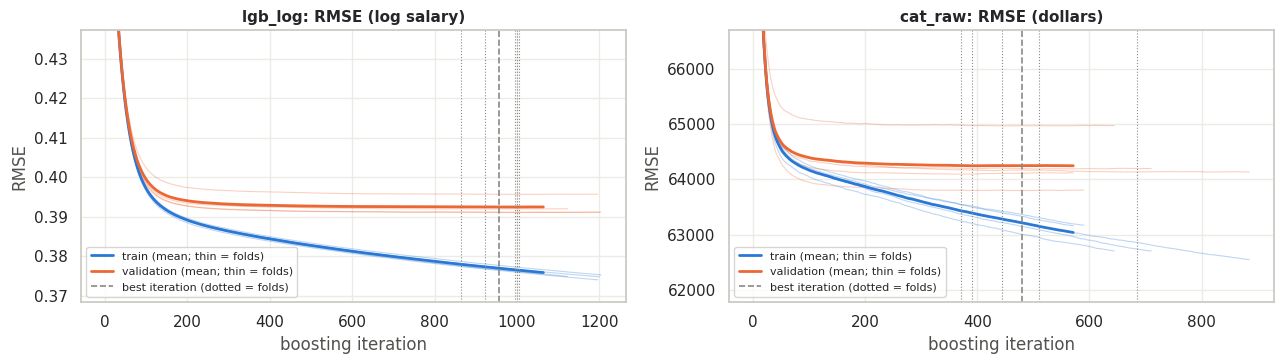

In [47]:
fig, axes = plt.subplots(1, len(cfg.MODELS), figsize=(6.5 * len(cfg.MODELS), 3.8), squeeze=False)
for ax, name in zip(axes[0], cfg.MODELS):
    for c in curves[name]:
        ax.plot(range(1, len(c["train"]) + 1), c["train"], color=TRAIN_C, lw=0.8, alpha=0.3)
        ax.plot(range(1, len(c["valid"]) + 1), c["valid"], color=VAL_C, lw=0.8, alpha=0.3)
    L = min(len(c["valid"]) for c in curves[name])
    tr_c = np.mean([c["train"][:L] for c in curves[name]], axis=0)
    va_c = np.mean([c["valid"][:L] for c in curves[name]], axis=0)
    unit = "log salary" if name.endswith("_log") else "dollars"
    ax.plot(range(1, L + 1), tr_c, color=TRAIN_C, lw=2, label="train (mean; thin = folds)")
    ax.plot(range(1, L + 1), va_c, color=VAL_C, lw=2, label="validation (mean; thin = folds)")
    for it in best_iters[name]:
        ax.axvline(it, color=GREY, ls=":", lw=0.8)
    ax.axvline(np.mean(best_iters[name]), color=GREY, ls="--", lw=1.2, label="best iteration (dotted = folds)")
    ax.set(title=f"{name}: RMSE ({unit})", xlabel="boosting iteration", ylabel="RMSE")
    lo, hi = np.percentile(np.r_[tr_c, va_c], [0, 97])
    ax.set_ylim(lo * 0.98, hi)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Each panel shows the training and validation loss per boosting round: thin lines are the single folds, thick
lines their mean over the rounds that every fold reached, and dotted lines each fold's best round. Training stops when
the validation loss has not improved for `EARLY_STOP` rounds. The final model, trained on all training rows, uses 10%
more rounds than the mean best round because it sees 25% more rows. The gap between the lines is the overfitting that
early stopping controls.

## 18. Blend

In [48]:
from scipy.optimize import nnls

P_oof = np.column_stack([oof[n] for n in cfg.MODELS])
weights, _ = nnls(P_oof, y[train_idx])
blend_oof = np.zeros(len(train_idx))
for a, b in FOLDS:
    w_k, _ = nnls(P_oof[a], y[train_idx][a])
    blend_oof[b] = P_oof[b] @ w_k
oof_all = {**base_oof, **oof, "blend": blend_oof}
cv_table = pd.DataFrame({k: reg_scores(y[train_idx], v) for k, v in oof_all.items()}).T
print("blend weights:", dict(zip(cfg.MODELS, np.round(weights, 3))), f"| sum {weights.sum():.3f}")
print("correlation of out-of-fold predictions:")
display(pd.DataFrame(P_oof, columns=cfg.MODELS).corr().round(3))
cv_table[MAIN].round(4)

blend weights: {'lgb_log': np.float64(0.556), 'cat_raw': np.float64(0.445)} | sum 1.001
correlation of out-of-fold predictions:


,lgb_log,cat_raw
lgb_log,1.000,0.993
cat_raw,0.993,1.000


,R2,MAE,RMSE
global mean,-0.0000,58513.8385,77211.9850
experience mean,0.1057,54389.0954,73017.5348
hierarchical means,0.2766,47690.4825,65668.8802
lgb_log,0.3084,46041.6691,64211.1627
cat_raw,0.3079,46252.4387,64233.5752
blend,0.3093,46110.0277,64171.8159


The blend weights are non-negative least squares on the out-of-fold predictions. The blend's own CV score is
nested: weights fitted on four folds score the fifth, so the blend is not judged on the rows that chose its weights.

## 19. Hold-out test

The final models are refitted on all training rows with the CV iteration counts, then the test rows are scored once. Headline metrics: R2, MAE and RMSE in dollars, with bootstrap 95% intervals.

In [49]:
N_FINAL = {n: max(20, int(np.mean(best_iters[n]) * 1.1)) for n in cfg.MODELS}


def fit_pipeline(fit_rows, seed=None, models=None):
    """Encoders + every model on `fit_rows` with the iteration counts chosen by CV."""
    X_fit, enc = fit_transform(fit_rows)
    fitted = {}
    for n in models or cfg.MODELS:
        m, pred_fn, _, _ = fit_one(n, X_fit, target_of(n, fit_rows), n_estimators=N_FINAL[n], seed=seed)
        smear = float(np.mean(np.exp(ly[fit_rows] - pred_fn(X_fit)))) if n.endswith("_log") else 1.0
        fitted[n] = {"model": m, "smear": smear}
    return {"enc": enc, "models": fitted}


def raw_predict(n, m, X):
    return m.predict(to_pool(X)) if n.startswith("cat") else m.predict(X)


def predict_pipeline(pipe, app_df, w=None):
    X = transform(app_df, pipe["enc"])
    preds = {}
    for n, f in pipe["models"].items():
        p = raw_predict(n, f["model"], X)
        preds[n] = np.exp(p) * f["smear"] if n.endswith("_log") else p
    names = list(pipe["models"])
    ww = np.asarray(weights if w is None else w)
    preds["blend"] = np.column_stack([preds[n] for n in names]) @ ww if len(ww) == len(names) else np.mean([preds[n] for n in names], axis=0)
    return preds


t0 = time.time()
pipe = fit_pipeline(train_idx)
test_pred = predict_pipeline(pipe, df.iloc[test_idx])
test_pred.update(baseline_preds(train_idx, test_idx))
print(f"final models fitted on all {len(train_idx):,} training rows in {time.time() - t0:.0f}s | iterations {N_FINAL}")

final models fitted on all 57,530 training rows in 34s | iterations {'lgb_log': 1053, 'cat_raw': 528}


In [50]:
y_test = y[test_idx]
order = ["global mean", "experience mean", "hierarchical means"] + cfg.MODELS + ["blend"]
test_table = pd.DataFrame({k: reg_scores(y_test, test_pred[k]) for k in order}).T
rng = np.random.default_rng(cfg.SEED)
boot = []
p_best = test_pred["blend"]
for _ in range(cfg.N_BOOT):
    i = rng.integers(0, len(y_test), len(y_test))
    boot.append([r2_score(y_test[i], p_best[i]), mean_absolute_error(y_test[i], p_best[i]),
                 np.sqrt(mean_squared_error(y_test[i], p_best[i]))])
ci = np.percentile(np.array(boot), [2.5, 97.5], axis=0)
FINAL = test_table.loc["blend"].to_dict()
print(f"TEST blend: R2 {FINAL['R2']:.4f} [95% CI {ci[0, 0]:.4f}, {ci[1, 0]:.4f}] | MAE ${FINAL['MAE']:,.0f} "
      f"[{ci[0, 1]:,.0f}, {ci[1, 1]:,.0f}] | RMSE ${FINAL['RMSE']:,.0f} [{ci[0, 2]:,.0f}, {ci[1, 2]:,.0f}]")
print(f"share of the noise ceiling reached: {FINAL['R2'] / CEILING_R2:.1%} (oracle R2 {CEILING_R2:.3f}, section 11)")
print(f"secondary metrics (blend): MedAE ${FINAL['MedAE']:,.0f} | MAPE {FINAL['MAPE']:.1%} | "
      f"within 20% {FINAL['within_20pct']:.1%} | RMSLE {FINAL['RMSLE']:.4f}")
test_table[MAIN].round(4)

TEST blend: R2 0.3071 [95% CI 0.2923, 0.3226] | MAE $46,368 [45,594, 47,145] | RMSE $64,757 [62,821, 66,520]
share of the noise ceiling reached: 86.0% (oracle R2 0.357, section 11)
secondary metrics (blend): MedAE $36,505 | MAPE 35.9% | within 20% 39.0% | RMSLE 0.3992


,R2,MAE,RMSE
global mean,-0.0000,58608.4024,77795.8298
experience mean,0.1061,54414.6558,73551.1726
hierarchical means,0.2811,47593.4586,65961.8349
lgb_log,0.3066,46328.0285,64782.2989
cat_raw,0.3059,46443.7977,64814.7688
blend,0.3071,46368.1063,64757.1860


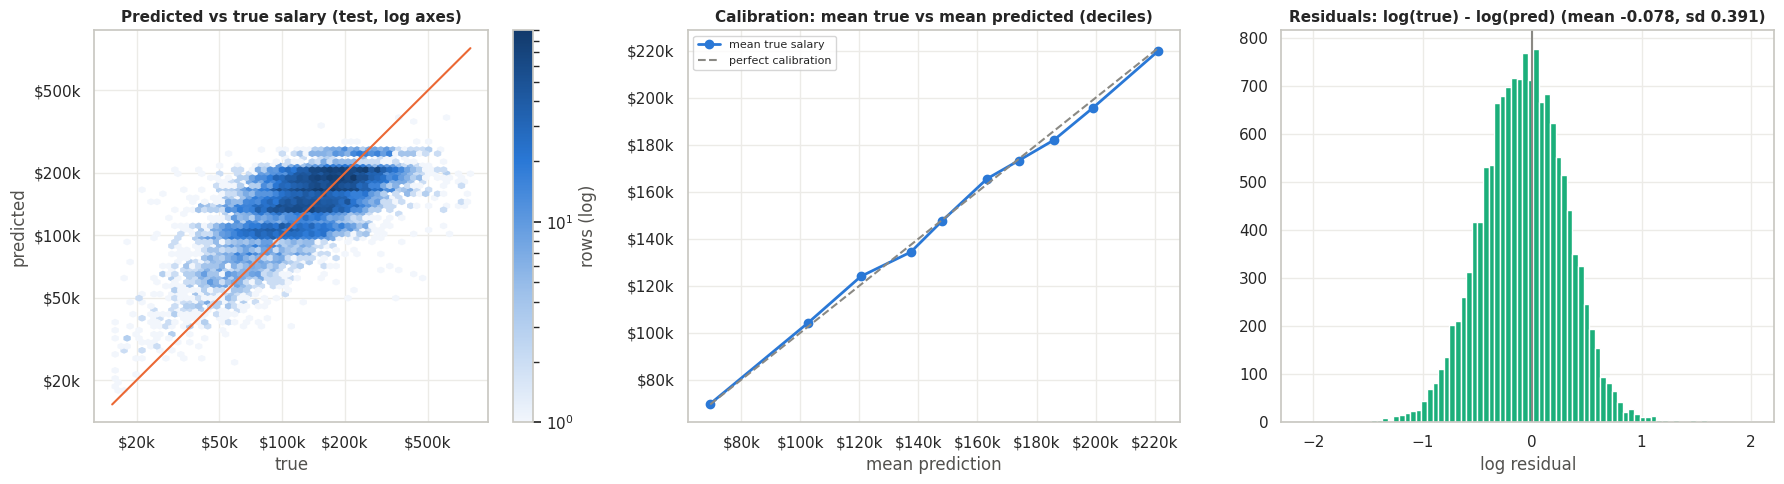

,salary_range,MAE,MAPE
true salary decile,,,
1,$15k-$67k,39273.856,0.799
2,$67k-$87k,45931.261,0.595
3,$87k-$105k,44690.822,0.465
4,$105k-$121k,40019.081,0.354
5,$121k-$139k,34808.795,0.269
6,$139k-$157k,30053.556,0.205
7,$157k-$178k,27677.395,0.166
8,$178k-$206k,28822.120,0.150
9,$206k-$250k,49585.752,0.218


In [51]:
res_log = np.log(y_test) - np.log(p_best)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
hb = ax[0].hexbin(y_test, p_best, gridsize=60, xscale="log", yscale="log", cmap=SEQ, mincnt=1, bins="log")
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, color=VAL_C, lw=1.5)
for axis in (ax[0].xaxis, ax[0].yaxis):
    axis.set_major_formatter(usd)
    axis.set_minor_formatter(plt.NullFormatter())
ax[0].set_xticks([2e4, 5e4, 1e5, 2e5, 5e5])
ax[0].set_yticks([2e4, 5e4, 1e5, 2e5, 5e5])
ax[0].set(title="Predicted vs true salary (test, log axes)", xlabel="true", ylabel="predicted")
fig.colorbar(hb, ax=ax[0], label="rows (log)")
dec = pd.qcut(p_best, 10, labels=False)
cal = pd.DataFrame({"pred": p_best, "true": y_test, "dec": dec}).groupby("dec").mean()
ax[1].plot(cal["pred"], cal["true"], marker="o", color=TRAIN_C, lw=2, label="mean true salary")
ax[1].plot(cal["pred"], cal["pred"], color=GREY, ls="--", label="perfect calibration")
ax[1].xaxis.set_major_formatter(usd)
ax[1].yaxis.set_major_formatter(usd)
ax[1].set(title="Calibration: mean true vs mean predicted (deciles)", xlabel="mean prediction")
ax[1].legend(fontsize=8)
ax[2].hist(res_log, bins=80, color=PAL[2])
ax[2].axvline(0, color=GREY)
ax[2].set(title=f"Residuals: log(true) - log(pred) (mean {res_log.mean():+.3f}, sd {res_log.std():.3f})", xlabel="log residual")
plt.tight_layout()
plt.show()
err_dec = pd.DataFrame({"true": y_test, "abs_err": np.abs(y_test - p_best), "ape": np.abs(y_test - p_best) / y_test})
err_dec["true salary decile"] = pd.qcut(err_dec["true"], 10, labels=False) + 1
err_dec.groupby("true salary decile").agg(salary_range=("true", lambda s: f"${s.min() / 1000:,.0f}k-${s.max() / 1000:,.0f}k"),
                                          MAE=("abs_err", "mean"), MAPE=("ape", "mean")).round(3)

How to read the plots: in the calibration panel, points on the diagonal mean the average prediction matches the
average true salary in that decile. The table splits the error by true-salary decile, which shows where the errors
concentrate instead of hiding them in one number. A mean predictor on data where identical profiles earn different
amounts tends to over-predict the lowest salaries and under-predict the highest; the findings below measure how much.

In [52]:
dev = (cal["true"] / cal["pred"] - 1).abs()
dec = pd.qcut(y_test, 10, labels=False)
signed = pd.Series((p_best - y_test) / y_test).groupby(dec).mean()
ape_dec = pd.Series(np.abs(p_best - y_test) / y_test).groupby(dec).mean()
print("Findings:")
print(f"- calibration: decile means of true and predicted salary differ by {100 * dev.mean():.1f}% on average (at most {100 * dev.max():.1f}%)")
print(f"- mean signed error: lowest true-salary decile {100 * signed.iloc[0]:+.0f}%, highest decile {100 * signed.iloc[-1]:+.0f}%")
print(f"- MAPE: lowest decile {ape_dec.iloc[0]:.0%}, deciles 5 to 8 {ape_dec.iloc[4:8].mean():.0%}, highest decile {ape_dec.iloc[-1]:.0%}")

Findings:
- calibration: decile means of true and predicted salary differ by 1.3% on average (at most 2.9%)
- mean signed error: lowest true-salary decile +78%, highest decile -37%
- MAPE: lowest decile 80%, deciles 5 to 8 20%, highest decile 37%


## 20. Robustness

Is the score a property of the method or of one lucky split?

### Repeated random splits

The whole pipeline (features, models, blend) is rerun on new train/test splits. If the hold-out score came from a lucky split, the other splits would score clearly lower. The spread across splits
is the honest uncertainty of the score.

In [53]:
rep_rows = []
for s in cfg.REPEAT_SEEDS:
    tr_s, te_s = train_test_split(rows, test_size=cfg.TEST_SIZE, random_state=s)
    p = predict_pipeline(fit_pipeline(tr_s), df.iloc[te_s])
    h = baseline_preds(tr_s, te_s)["hierarchical means"]
    rep_rows.append({"split seed": s, **{f"blend {k}": v for k, v in reg_scores(y[te_s], p["blend"]).items() if k in ("R2", "MAE", "RMSE")},
                     "hierarchical R2": r2_score(y[te_s], h)})
    print(f"split seed {s}: blend R2 {rep_rows[-1]['blend R2']:.4f} | hierarchical means R2 {rep_rows[-1]['hierarchical R2']:.4f}")
rep = pd.DataFrame(rep_rows)
print(f"\nblend over {len(rep)} random splits: R2 {rep['blend R2'].mean():.4f} +- {rep['blend R2'].std():.4f} | "
      f"MAE ${rep['blend MAE'].mean():,.0f} +- {rep['blend MAE'].std():,.0f} | RMSE ${rep['blend RMSE'].mean():,.0f} +- {rep['blend RMSE'].std():,.0f}")
rep.round(4)

split seed 1: blend R2 0.3076 | hierarchical means R2 0.2795
split seed 2: blend R2 0.3171 | hierarchical means R2 0.2879
split seed 3: blend R2 0.3103 | hierarchical means R2 0.2825
split seed 4: blend R2 0.3038 | hierarchical means R2 0.2743
split seed 5: blend R2 0.3053 | hierarchical means R2 0.2774

blend over 5 random splits: R2 0.3088 +- 0.0052 | MAE $46,063 +- 84 | RMSE $64,041 +- 524


,split seed,blend R2,blend MAE,blend RMSE,hierarchical R2
0,1,0.3076,46181.5951,64833.1793,0.2795
1,2,0.3171,45963.7926,63641.9971,0.2879
2,3,0.3103,46109.8211,64286.2970,0.2825
3,4,0.3038,46021.9729,63871.2986,0.2743
4,5,0.3053,46038.2375,63570.6651,0.2774


In [54]:
wins = int((rep["blend R2"] > rep["hierarchical R2"]).sum())
print(f"Findings: blend R2 ranges from {rep['blend R2'].min():.4f} to {rep['blend R2'].max():.4f} across {len(rep)} splits "
      f"(main split {FINAL['R2']:.4f}); it beats the hierarchical reference on {wins} of {len(rep)} splits.")

Findings: blend R2 ranges from 0.3038 to 0.3171 across 5 splits (main split 0.3071); it beats the hierarchical reference on 5 of 5 splits.


### Time split

The time split is the strict test: the model only sees earlier years and predicts the latest one, which has a
different mix of jobs and countries (section 10). A small drop compared with the random split is expected; a large
drop would mean the model relies on patterns that do not carry forward in time.

In [55]:
last = df["work_year"].max()
tr_t, te_t = rows[df["work_year"] < last], rows[df["work_year"] == last]
p_t = predict_pipeline(fit_pipeline(tr_t), df.iloc[te_t])
b_t = baseline_preds(tr_t, te_t)
time_table = pd.DataFrame({k: reg_scores(y[te_t], v) for k, v in {**b_t, **p_t}.items()}).T
print(f"train: years before {last} ({len(tr_t):,} rows) | test: {last} ({len(te_t):,} rows)")
time_table[MAIN].round(4)

train: years before 2025 (33,631 rows) | test: 2025 (38,282 rows)


,R2,MAE,RMSE
global mean,-0.0001,59141.4102,78505.4442
experience mean,0.1070,55108.7694,74185.0980
hierarchical means,0.2523,49188.7727,67883.2585
lgb_log,0.2872,47076.7785,66277.8049
cat_raw,0.2926,47252.3795,66026.6477
blend,0.2922,47080.2215,66045.1288


In [56]:
print(f"Findings: time-split R2 {time_table.loc['blend', 'R2']:.4f} vs random-split test R2 {FINAL['R2']:.4f} "
      f"(change {time_table.loc['blend', 'R2'] - FINAL['R2']:+.4f}); hierarchical reference on the time split "
      f"{time_table.loc['hierarchical means', 'R2']:.4f}.")

Findings: time-split R2 0.2922 vs random-split test R2 0.3071 (change -0.0149); hierarchical reference on the time split 0.2523.


### Seeds, extreme salaries, unseen titles, adversarial check

Four more checks: model seeds (does the score depend on luck?), training without the highest salaries (are a few
extreme rows driving the model?), unseen job titles (how much does the model lose when a title is new, keeping only title
words, role family and the other columns?) and adversarial validation (is the test set a fair sample of the same
distribution?).

In [57]:
seed_rows = []
for s in cfg.MODEL_SEEDS:
    p = predict_pipeline(fit_pipeline(train_idx, seed=s), df.iloc[test_idx])
    seed_rows.append({"model seed": s, **{k: v for k, v in reg_scores(y_test, p["blend"]).items() if k in ("R2", "MAE", "RMSE")}})
seeds_tab = pd.DataFrame(seed_rows)
print(f"blend R2 across {len(seeds_tab)} model seeds: {seeds_tab['R2'].mean():.5f} +- {seeds_tab['R2'].std():.5f} "
      f"(per seed: {', '.join(f'{s}: {r:.5f}' for s, r in zip(seeds_tab['model seed'], seeds_tab['R2']))}; main run {FINAL['R2']:.5f})")

thr = df.loc[df["salary_outlier_flag"], cfg.TARGET].min()
keep = train_idx[y[train_idx] < thr]
p_trim = predict_pipeline(fit_pipeline(keep), df.iloc[test_idx])["blend"]
normal = y_test < thr
trim_tab = pd.DataFrame({
    "trained on all rows": {"R2 all test": FINAL["R2"], "MAE all test": FINAL["MAE"],
                            "MAE test rows below threshold": mean_absolute_error(y_test[normal], p_best[normal])},
    f"trained without salaries >= ${thr:,.0f}": {"R2 all test": r2_score(y_test, p_trim), "MAE all test": mean_absolute_error(y_test, p_trim),
                                                 "MAE test rows below threshold": mean_absolute_error(y_test[normal], p_trim[normal])}}).T
print(f"\nremoving the {len(train_idx) - len(keep):,} highest salaries from training:")
display(trim_tab.round(4))

unseen = df.iloc[test_idx].copy()
unseen["job_title"] = unseen["job_title"] + " (new variant)"
p_unseen = predict_pipeline(pipe, unseen)["blend"]
print(f"every test title replaced by an unseen variant (title words and role family kept): R2 {r2_score(y_test, p_unseen):.4f} "
      f"vs {FINAL['R2']:.4f} with the real titles")

Xadv = pd.concat([base_features(df.iloc[train_idx]), base_features(df.iloc[test_idx])])
yadv = np.r_[np.zeros(len(train_idx)), np.ones(len(test_idx))]
adv_auc = np.mean([roc_auc_score(yadv[b], lgb.LGBMClassifier(n_estimators=200, verbose=-1, random_state=cfg.SEED)
                                 .fit(Xadv.iloc[a], yadv[a]).predict_proba(Xadv.iloc[b])[:, 1])
                   for a, b in StratifiedKFold(3, shuffle=True, random_state=cfg.SEED).split(Xadv, yadv)])
print(f"adversarial validation train vs test: AUC {adv_auc:.3f} (0.5 = the test rows look like the training rows)")

blend R2 across 3 model seeds: 0.30679 +- 0.00005 (per seed: 7: 0.30684, 99: 0.30675, 2024: 0.30677; main run 0.30711)

removing the 1,394 highest salaries from training:


,R2 all test,MAE all test,MAE test rows below threshold
trained on all rows,0.3071,46368.1063,41939.0542
"trained without salaries >= $332,000",0.2940,45859.6021,41034.8281


every test title replaced by an unseen variant (title words and role family kept): R2 0.1940 vs 0.3071 with the real titles
adversarial validation train vs test: AUC 0.492 (0.5 = the test rows look like the training rows)


In [58]:
print("Findings:")
print(f"- R2 spread across model seeds (sd): {seeds_tab['R2'].std():.5f}")
print(f"- R2 change when the highest salaries are left out of training: {r2_score(y_test, p_trim) - FINAL['R2']:+.4f}")
print(f"- R2 change when every test title is unseen: {r2_score(y_test, p_unseen) - FINAL['R2']:+.4f}")
print(f"- adversarial AUC train vs test: {adv_auc:.3f}")

Findings:
- R2 spread across model seeds (sd): 0.00005
- R2 change when the highest salaries are left out of training: -0.0131
- R2 change when every test title is unseen: -0.1131
- adversarial AUC train vs test: 0.492


## 21. Bias audit

In [59]:
test_df = df.iloc[test_idx].assign(pred=p_best, true=y_test, log_err=np.log(p_best) - np.log(y_test),
                                   is_us=np.where(df.iloc[test_idx]["company_location"] == "US", "US", "not US"))
AUDIT = ["experience_level", "employment_type", "company_size", "work_mode", "region", "is_us", "work_year", "role_family"]


def group_report(frame, pred_col="pred", err_col="log_err"):
    out = []
    rng = np.random.default_rng(cfg.SEED)
    level = 100 * (np.exp(frame[err_col].mean()) - 1)
    for attr in AUDIT:
        for g, sub in frame.groupby(attr):
            if len(sub) < cfg.MIN_GROUP:
                continue
            e = sub[err_col].values
            bs = np.array([rng.choice(e, len(e)).mean() for _ in range(200)])
            out.append({"attribute": attr, "group": g, "n": len(sub),
                        "MAE": mean_absolute_error(sub["true"], sub[pred_col]),
                        "MAPE": np.mean(np.abs(sub[pred_col] - sub["true"]) / sub["true"]),
                        "bias %": 100 * (np.exp(e.mean()) - 1) - level,
                        "bias lo %": 100 * (np.exp(np.percentile(bs, 2.5)) - 1) - level,
                        "bias hi %": 100 * (np.exp(np.percentile(bs, 97.5)) - 1) - level})
    r = pd.DataFrame(out)
    r["flag"] = (r["bias lo %"] > cfg.BIAS_TOL) | (r["bias hi %"] < -cfg.BIAS_TOL)
    return r


overall_level = 100 * (np.exp(test_df["log_err"].mean()) - 1)
audit = group_report(test_df)
print(f"overall level: exp(mean log error) - 1 = {overall_level:+.1f}% (a mean-in-dollars model sits a little above the "
      "typical salary; each group is compared with this level)")
print(f"groups with at least {cfg.MIN_GROUP} test rows: {len(audit)} | flagged: {int(audit['flag'].sum())}")
audit.round(3).sort_values(["attribute", "n"], ascending=[True, False]).reset_index(drop=True)

overall level: exp(mean log error) - 1 = +8.1% (a mean-in-dollars model sits a little above the typical salary; each group is compared with this level)
groups with at least 30 test rows: 35 | flagged: 0


,attribute,group,n,MAE,MAPE,bias %,bias lo %,bias hi %,flag
0,company_size,M,14038,46491.000,0.358,0.001,-0.737,0.682,False
1,company_size,L,306,43132.054,0.383,-0.271,-4.729,5.047,False
2,company_size,S,39,27523.350,0.448,1.770,-11.232,18.048,False
3,employment_type,FT,14248,46493.991,0.359,0.053,-0.667,0.683,False
4,employment_type,CT,79,34378.622,0.295,-7.918,-18.735,-0.108,False
5,employment_type,PT,53,32413.054,0.475,-1.774,-14.479,17.066,False
6,experience_level,SE,7454,49421.724,0.343,-0.026,-1.030,1.087,False
7,experience_level,MI,4774,44656.290,0.375,-0.384,-1.522,0.747,False
8,experience_level,EN,1589,32777.030,0.393,1.700,-0.572,3.726,False
9,experience_level,EX,566,58747.550,0.343,-1.143,-4.237,1.862,False


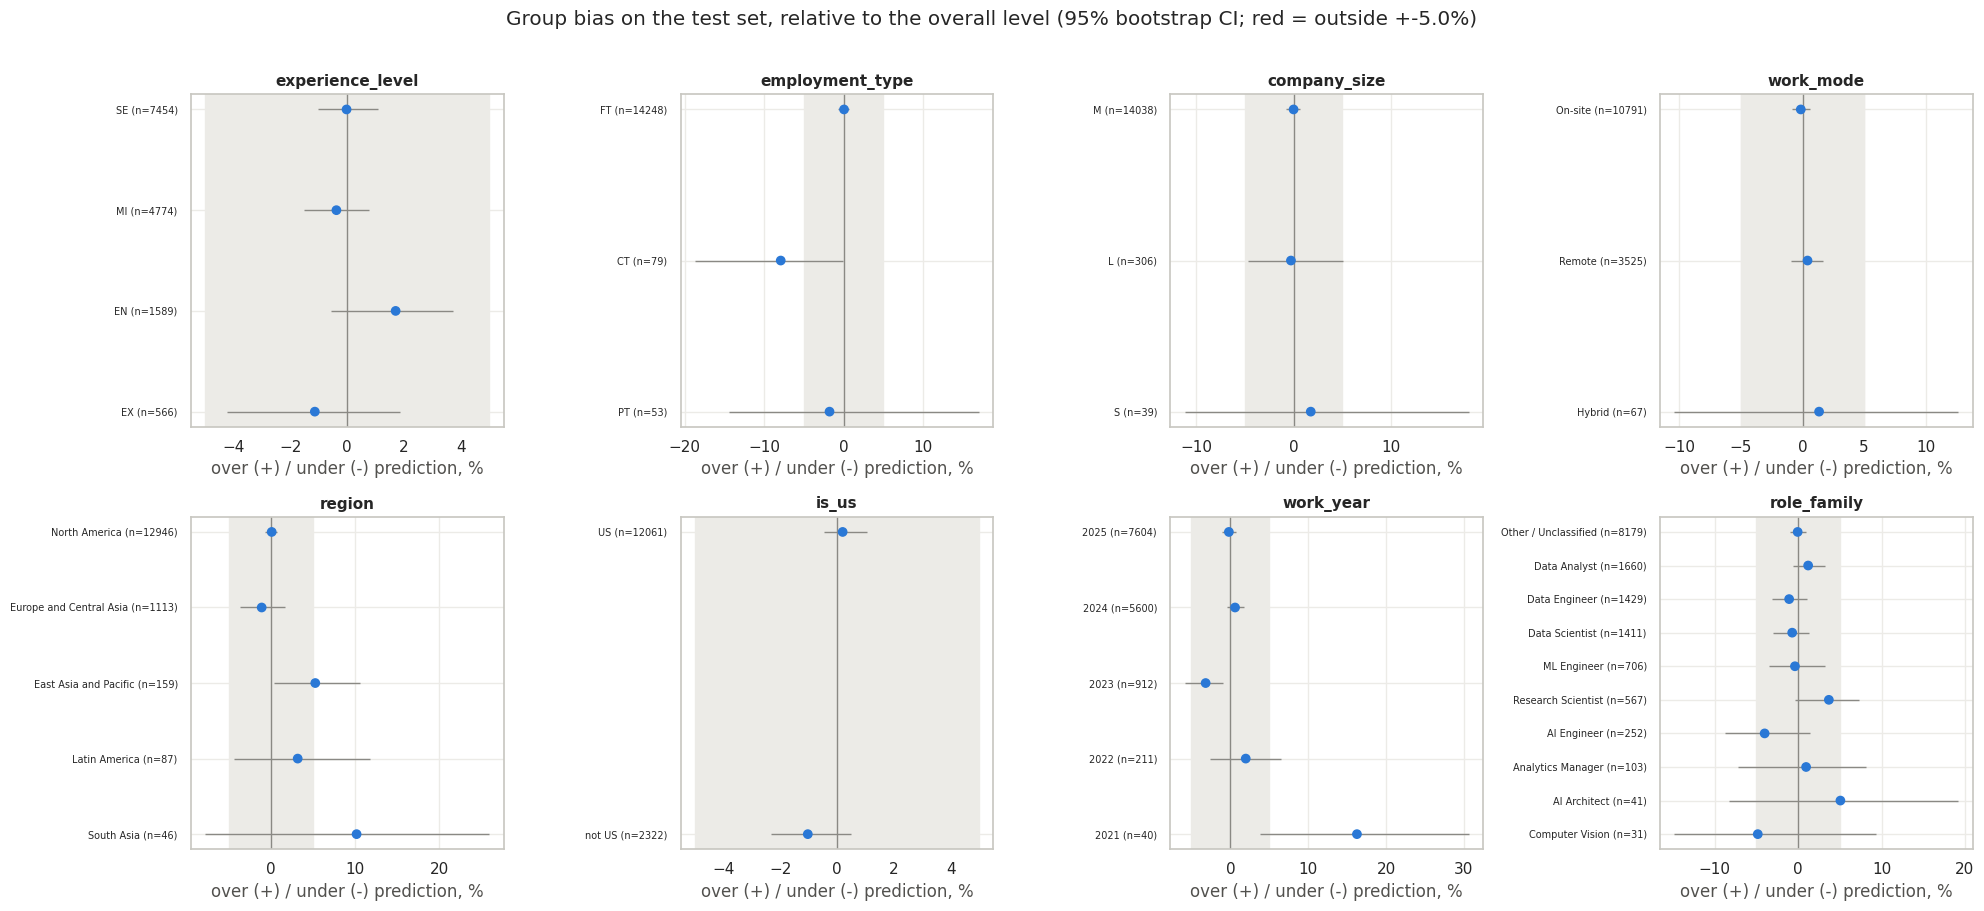

flagged groups: none


In [60]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, attr in zip(axes.ravel(), AUDIT):
    a = audit[audit["attribute"] == attr].sort_values("n")
    yv = np.arange(len(a))
    ax.axvspan(-cfg.BIAS_TOL, cfg.BIAS_TOL, color="#ecebe7", zorder=0)
    ax.errorbar(a["bias %"], yv, xerr=[a["bias %"] - a["bias lo %"], a["bias hi %"] - a["bias %"]], fmt="none", ecolor=GREY, lw=1)
    ax.scatter(a["bias %"], yv, color=[PAL[7] if f else PAL[0] for f in a["flag"]], s=36, zorder=3)
    ax.axvline(0, color=GREY, lw=1)
    ax.set_yticks(yv)
    ax.set_yticklabels([f"{g} (n={n})" for g, n in zip(a["group"], a["n"])], fontsize=7)
    ax.set_title(attr)
    ax.set_xlabel("over (+) / under (-) prediction, %")
plt.suptitle(f"Group bias on the test set, relative to the overall level (95% bootstrap CI; red = outside +-{cfg.BIAS_TOL}%)", y=1.01)
plt.tight_layout()
plt.show()
flagged = audit[audit["flag"]]
print("flagged groups:", "none" if flagged.empty else flagged[["attribute", "group", "n", "bias %"]].round(1).to_dict("records"))

Errors are compared in percent (log scale), not in dollars, because a $10k miss matters more on a $50k salary
than on a $300k one. A group is flagged when the whole 95% interval of its bias lies outside the tolerance band. Groups
with fewer than `MIN_GROUP` test rows are not scored, because their estimates would be noise.

"Not flagged" is not the same as "no bias". Some small groups have a point estimate outside the band (the dots outside
the grey area above) but are not flagged because their intervals are wide. The cell below lists them in two kinds:
- the interval excludes zero: the group is probably over- or under-predicted, but the data cannot show that the bias is
  larger than the tolerance;
- the interval includes zero: the data cannot tell a bias from chance at all.

Predictions for both kinds should be used with extra care; more rows for these groups would settle the question.

In [61]:
unsure = audit[(audit["bias %"].abs() > cfg.BIAS_TOL) & ~audit["flag"]].copy()
unsure["reading"] = np.where((unsure["bias lo %"] > 0) | (unsure["bias hi %"] < 0),
                             "probably biased, size uncertain", "cannot tell from chance")
n_probable = int((unsure["reading"] == "probably biased, size uncertain").sum())
print(f"groups with a point estimate beyond +-{cfg.BIAS_TOL}% that are not flagged: {len(unsure)} "
      f"({n_probable} probably biased with an uncertain size, {len(unsure) - n_probable} cannot be told from chance)")
unsure[["attribute", "group", "n", "bias %", "bias lo %", "bias hi %", "reading"]].round(1).reset_index(drop=True)

groups with a point estimate beyond +-5.0% that are not flagged: 5 (3 probably biased with an uncertain size, 2 cannot be told from chance)


,attribute,group,n,bias %,bias lo %,bias hi %,reading
0,employment_type,CT,79,-7.9,-18.7,-0.1,"probably biased, size uncertain"
1,region,East Asia and Pacific,159,5.2,0.4,10.6,"probably biased, size uncertain"
2,region,South Asia,46,10.2,-7.9,26.0,cannot tell from chance
3,work_year,2021,40,16.3,3.8,30.6,"probably biased, size uncertain"
4,role_family,AI Architect,41,5.1,-8.3,19.2,cannot tell from chance


### Correction, chosen by cross-validation

In [62]:
oof_frame = df.iloc[train_idx].assign(r=np.log(y[train_idx]) - np.log(blend_oof),
                                      is_us=np.where(df.iloc[train_idx]["company_location"] == "US", "US", "not US"))


def fit_correction(frame, attrs):
    """Shrunk mean log residual per group, summed over attributes, fitted on out-of-fold residuals only."""
    return frame["r"].mean(), {a: frame.groupby(a)["r"].agg(["sum", "count"]) for a in attrs}


def apply_correction(frame, base, tables):
    c = np.zeros(len(frame))
    for a, t in tables.items():
        s = frame[a].map(t["sum"]).fillna(0).values
        n = frame[a].map(t["count"]).fillna(0).values
        c += (s - n * base) / (n + cfg.CORR_ALPHA)
    return c


cand = {"none": []} | {a: [a] for a in AUDIT} | {"all audit attributes": AUDIT}
nested = {}
for label, attrs in cand.items():
    pred = blend_oof.copy()
    if attrs:
        for a, b in FOLDS:
            base, tables = fit_correction(oof_frame.iloc[a], attrs)
            pred[b] = blend_oof[b] * np.exp(apply_correction(oof_frame.iloc[b], base, tables))
    frame = oof_frame.assign(pred=pred, true=y[train_idx], log_err=np.log(pred) - np.log(y[train_idx]))
    rb = group_report(frame)
    nested[label] = {"CV R2": r2_score(y[train_idx], pred), "CV MAE": mean_absolute_error(y[train_idx], pred),
                     "max |group bias| %": rb["bias %"].abs().max(), "flagged groups": int(rb["flag"].sum())}
nested = pd.DataFrame(nested).T
needed = nested.loc["none", "flagged groups"] > 0
best_fix = nested.drop(index="none")["flagged groups"].idxmin() if needed else "none"
use_fix = bool(needed and nested.loc[best_fix, "flagged groups"] < nested.loc["none", "flagged groups"]
               and nested.loc[best_fix, "CV R2"] >= nested.loc["none", "CV R2"] - 0.001)
print(f"groups flagged in CV without a correction: {int(nested.loc['none', 'flagged groups'])} | correction applied: {use_fix}"
      + (f" ({best_fix})" if use_fix else ""))
print("rule: correct only when CV flags a group, the correction removes flags, and it costs at most 0.001 CV R2")
nested.round(4)

groups flagged in CV without a correction: 0 | correction applied: False
rule: correct only when CV flags a group, the correction removes flags, and it costs at most 0.001 CV R2


,CV R2,CV MAE,max |group bias| %,flagged groups
none,0.3093,46110.0277,10.8789,0.0
experience_level,0.3089,46126.0939,10.7767,0.0
employment_type,0.3092,46114.8866,10.8902,0.0
company_size,0.3092,46112.5289,10.8705,0.0
work_mode,0.3092,46112.9209,10.7354,0.0
region,0.3092,46123.1344,6.4199,0.0
is_us,0.3092,46111.8534,10.6081,0.0
work_year,0.3092,46114.3538,10.6984,0.0
role_family,0.3090,46117.2601,10.9413,0.0
all audit attributes,0.3084,46164.0817,5.8115,0.0


In [63]:
if use_fix:
    base, tables = fit_correction(oof_frame, cand[best_fix])
    test_df["pred_fixed"] = test_df["pred"] * np.exp(apply_correction(test_df, base, tables))
    test_df["log_err_fixed"] = np.log(test_df["pred_fixed"]) - np.log(test_df["true"])
    after = group_report(test_df, "pred_fixed", "log_err_fixed")
    print(f"test after the correction: R2 {r2_score(y_test, test_df['pred_fixed']):.4f} (before {FINAL['R2']:.4f}) | "
          f"max |group bias| {after['bias %'].abs().max():.1f}% (before {audit['bias %'].abs().max():.1f}%) | "
          f"flagged groups {int(after['flag'].sum())} (before {int(audit['flag'].sum())})")
    p_final = test_df["pred_fixed"].values
else:
    print("no correction applied: the blend is kept as it is")
    p_final = p_best
FINAL_USED = reg_scores(y_test, p_final)

no correction applied: the blend is kept as it is


Any fix for group bias is chosen on the training folds only, never on the test set. A shrunk per-group
correction of the log residual is fitted on out-of-fold predictions and scored on the fold it did not see. It is applied
only if cross-validation flags at least one group, the correction removes flags, and it costs at most 0.001 CV R2.
Otherwise the model is left unchanged, because a correction nobody needs only adds noise.

## 22. Prediction intervals

The intervals are split-conformal: quantiles of the out-of-fold log residuals give a band that should contain the
true salary for `PI_LEVEL` of new rows. One band for everyone can over-cover some groups and under-cover others, so a
second version uses separate quantiles per experience level (Mondrian conformal). A group covered well below the target
has intervals that are too narrow for it; the findings list such groups.

90% intervals on the test set: coverage 0.896 (one quantile) and 0.898 (per experience level) | median width $190,972


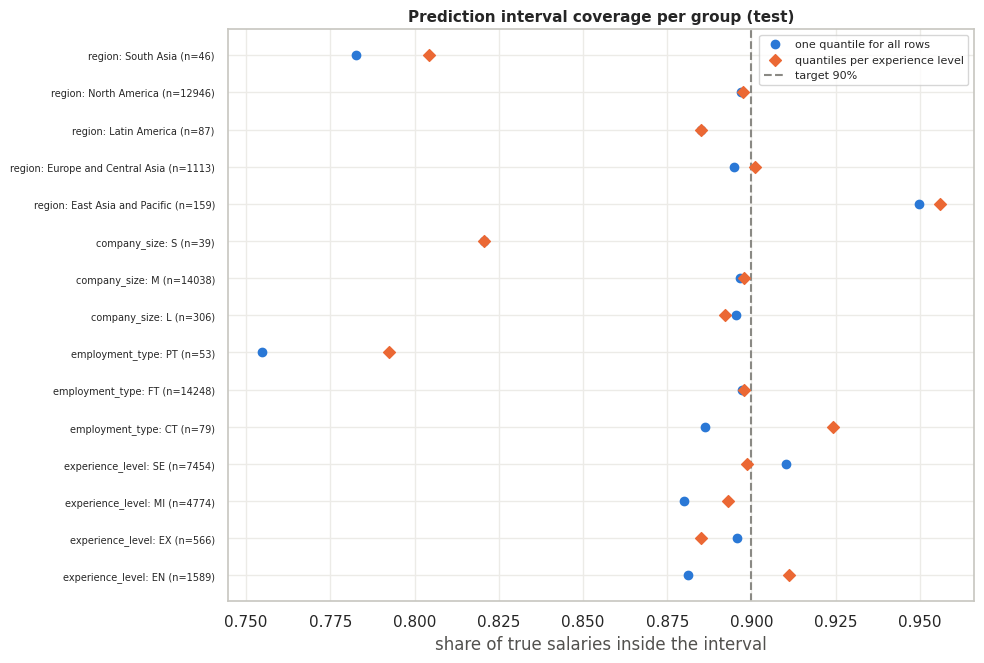

,attribute,group,n,coverage (one quantile),coverage (per experience level),median width $
0,experience_level,EN,1589,0.881,0.911,135909.622
1,experience_level,EX,566,0.896,0.885,236575.483
2,experience_level,MI,4774,0.880,0.893,180712.575
3,experience_level,SE,7454,0.910,0.899,204384.417
4,employment_type,CT,79,0.886,0.924,131026.210
5,employment_type,FT,14248,0.897,0.898,191235.980
6,employment_type,PT,53,0.755,0.792,105176.421
7,company_size,L,306,0.895,0.892,184405.815
8,company_size,M,14038,0.897,0.898,191235.980
9,company_size,S,39,0.821,0.821,86011.627


In [64]:
alpha_pi = 1 - cfg.PI_LEVEL
r_oof = np.log(y[train_idx]) - np.log(blend_oof)
q_lo, q_hi = np.quantile(r_oof, [alpha_pi / 2, 1 - alpha_pi / 2], method="higher")
test_df["lo"], test_df["hi"] = p_final * np.exp(q_lo), p_final * np.exp(q_hi)
res_by_exp = pd.DataFrame({"r": r_oof, "g": df.iloc[train_idx]["experience_level"].values}).groupby("g")["r"]
mq_lo, mq_hi = res_by_exp.quantile(alpha_pi / 2), res_by_exp.quantile(1 - alpha_pi / 2)
test_df["lo_m"] = p_final * np.exp(test_df["experience_level"].map(mq_lo).values)
test_df["hi_m"] = p_final * np.exp(test_df["experience_level"].map(mq_hi).values)


def coverage(lo, hi, t):
    return float(np.mean((t >= lo) & (t <= hi)))


print(f"{cfg.PI_LEVEL:.0%} intervals on the test set: coverage {coverage(test_df['lo'], test_df['hi'], test_df['true']):.3f} "
      f"(one quantile) and {coverage(test_df['lo_m'], test_df['hi_m'], test_df['true']):.3f} (per experience level) | "
      f"median width ${np.median(test_df['hi_m'] - test_df['lo_m']):,.0f}")
rows_pi = []
for attr in ["experience_level", "employment_type", "company_size", "region"]:
    for g, sub in test_df.groupby(attr):
        if len(sub) >= cfg.MIN_GROUP:
            rows_pi.append({"attribute": attr, "group": g, "n": len(sub),
                            "coverage (one quantile)": coverage(sub["lo"], sub["hi"], sub["true"]),
                            "coverage (per experience level)": coverage(sub["lo_m"], sub["hi_m"], sub["true"]),
                            "median width $": np.median(sub["hi_m"] - sub["lo_m"])})
pi_tab = pd.DataFrame(rows_pi)
fig, ax = plt.subplots(figsize=(10, 0.32 * len(pi_tab) + 2))
yv = np.arange(len(pi_tab))
ax.scatter(pi_tab["coverage (one quantile)"], yv, color=PAL[0], s=36, label="one quantile for all rows", zorder=3)
ax.scatter(pi_tab["coverage (per experience level)"], yv, color=PAL[1], s=36, marker="D",
           label="quantiles per experience level", zorder=3)
ax.axvline(cfg.PI_LEVEL, color=GREY, ls="--", label=f"target {cfg.PI_LEVEL:.0%}")
ax.set_yticks(yv)
ax.set_yticklabels([f"{a}: {g} (n={n})" for a, g, n in zip(pi_tab["attribute"], pi_tab["group"], pi_tab["n"])], fontsize=7)
ax.set(title="Prediction interval coverage per group (test)", xlabel="share of true salaries inside the interval")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
pi_tab.round(3)

In [65]:
low = pi_tab[pi_tab["coverage (per experience level)"] < cfg.PI_LEVEL - 0.05]
print(f"Findings: overall coverage {coverage(test_df['lo_m'], test_df['hi_m'], test_df['true']):.3f} (target {cfg.PI_LEVEL:.2f}); "
      f"groups covered below {cfg.PI_LEVEL - 0.05:.2f}:",
      [(a, g, n, round(c, 3)) for a, g, n, c in low[["attribute", "group", "n", "coverage (per experience level)"]].values] or "none")

Findings: overall coverage 0.898 (target 0.90); groups covered below 0.85: [('employment_type', 'PT', 53, 0.792), ('company_size', 'S', 39, 0.821), ('region', 'South Asia', 46, 0.804)]


## 23. Supplementary: accuracy views

This is a regression task, and its headline metrics are R2, MAE and RMSE (hold-out test section and conclusions).
"Accuracy" (share of exactly right answers) does not apply to a dollar amount, because a prediction is almost never the
exact salary. This supplementary section gives two accuracy views for readers who ask for one: tolerance accuracy (is
the prediction within x% of the truth?) and salary-band accuracy (is the salary band right?). They do not replace
R2, MAE and RMSE.

### Tolerance accuracy

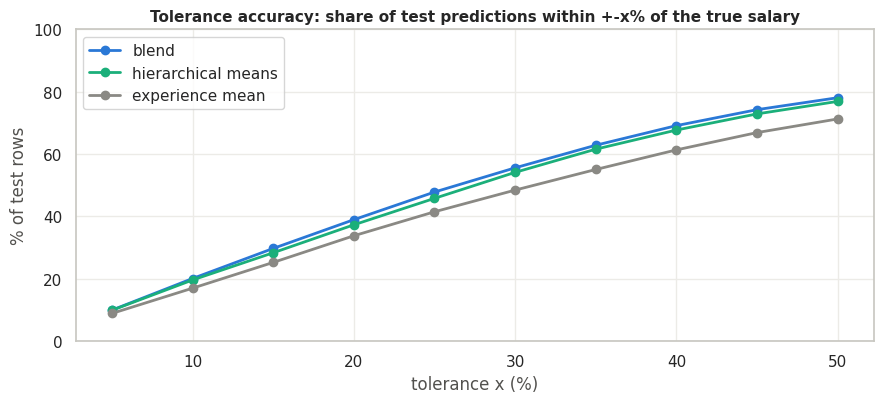

,blend,hierarchical means,experience mean
within +-10%,20.1,19.6,17.0
within +-20%,39.0,37.3,33.8
within +-30%,55.6,54.1,48.5
within +-50%,78.1,76.9,71.3


In [66]:
tol = np.arange(5, 55, 5)
refs = {"blend": p_best, "hierarchical means": test_pred["hierarchical means"], "experience mean": test_pred["experience mean"]}
tol_tab = pd.DataFrame({k: [100 * np.mean(np.abs(v - y_test) / y_test <= t / 100) for t in tol] for k, v in refs.items()},
                       index=[f"within +-{t}%" for t in tol])
fig, ax = plt.subplots(figsize=(9, 4.2))
for (k, _), c in zip(refs.items(), [PAL[0], PAL[2], GREY]):
    ax.plot(tol, tol_tab[k].values, marker="o", color=c, lw=2, label=k)
ax.set(title="Tolerance accuracy: share of test predictions within +-x% of the true salary", xlabel="tolerance x (%)",
       ylabel="% of test rows", ylim=(0, 100))
ax.legend()
plt.tight_layout()
plt.show()
tol_tab.loc[["within +-10%", "within +-20%", "within +-30%", "within +-50%"]].round(1)

In [67]:
gap_h = tol_tab["blend"] - tol_tab["hierarchical means"]
gap_e = tol_tab["blend"] - tol_tab["experience mean"]
print(f"Findings: across tolerances the blend is within x% more often than the hierarchical means by {gap_h.min():.1f} to "
      f"{gap_h.max():.1f} points, and than the experience mean by {gap_e.min():.1f} to {gap_e.max():.1f} points.")

Findings: across tolerances the blend is within x% more often than the hierarchical means by 0.1 to 2.0 points, and than the experience mean by 1.1 to 7.8 points.


### Salary-band accuracy

Salaries are cut into bands at the quantiles of the training salaries. Two ways to predict the band are compared on the same folds: cutting the regression prediction, and a LightGBM classifier trained on the band directly with the same features. The two approaches optimise different things: a classifier maximises the number of exact-band hits, while a mean
prediction cut into bands rarely lands in an extreme band. Chance level is one in `N_BANDS`.

In [68]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix

edges = np.quantile(y[train_idx], np.linspace(0, 1, cfg.N_BANDS + 1)[1:-1])
band = np.digitize(y, edges)
BAND_NAMES = ([f"< ${edges[0] / 1000:.0f}k"] + [f"${a / 1000:.0f}k-{b / 1000:.0f}k" for a, b in zip(edges[:-1], edges[1:])]
              + [f">= ${edges[-1] / 1000:.0f}k"])


def band_scores(t, p):
    return {"accuracy": accuracy_score(t, p), "balanced accuracy": balanced_accuracy_score(t, p),
            "macro F1": f1_score(t, p, average="macro"), "within one band": float(np.mean(np.abs(t - p) <= 1))}


cls_oof = np.zeros((len(train_idx), cfg.N_BANDS))
cls_iters, cls_curves = [], []
for k, (fit_rows, val_rows, X_fit, X_val) in enumerate(fold_data):
    clf = lgb.LGBMClassifier(n_estimators=cfg.MAX_ROUNDS, learning_rate=cfg.LGB_LR, subsample_freq=1, random_state=cfg.SEED,
                             verbose=-1, n_jobs=cfg.N_JOBS, **cfg.LGB_PARAMS["log"])
    clf.fit(X_fit, band[fit_rows], eval_set=[(X_fit, band[fit_rows]), (X_val, band[val_rows])], eval_names=["train", "valid"],
            callbacks=[lgb.early_stopping(cfg.EARLY_STOP, first_metric_only=True, verbose=False)])
    cls_oof[FOLDS[k][1]] = clf.predict_proba(X_val)
    cls_iters.append(clf.best_iteration_)
    r = clf.evals_result_
    key = list(r["valid"].keys())[0]
    cls_curves.append({"train": r["train"][key], "valid": r["valid"][key]})
exp_band = pd.Series(band[train_idx]).groupby(df["experience_level"].values[train_idx]).agg(lambda s: s.value_counts().index[0])
band_cv = pd.DataFrame({
    "most common band": band_scores(band[train_idx], np.full(len(train_idx), np.bincount(band[train_idx]).argmax())),
    "most common band per experience level": band_scores(band[train_idx], df["experience_level"].iloc[train_idx].map(exp_band).values),
    "regression blend cut into bands": band_scores(band[train_idx], np.digitize(blend_oof, edges)),
    "band classifier": band_scores(band[train_idx], cls_oof.argmax(1))}).T
print(f"{cfg.N_BANDS} bands from training-salary quantiles: {BAND_NAMES} | classifier best iterations {cls_iters}")
band_cv.round(4)

4 bands from training-salary quantiles: ['< $96k', '$96k-139k', '$139k-190k', '>= $190k'] | classifier best iterations [308, 241, 313, 261, 320]


,accuracy,balanced accuracy,macro F1,within one band
most common band,0.2510,0.2500,0.1003,0.7498
most common band per experience level,0.3567,0.3572,0.2387,0.6351
regression blend cut into bands,0.4113,0.4113,0.4194,0.8790
band classifier,0.4466,0.4468,0.4308,0.8145


TEST band accuracy (4 bands): 0.449 [95% CI 0.441, 0.458] | chance 0.250 | within one band 0.813


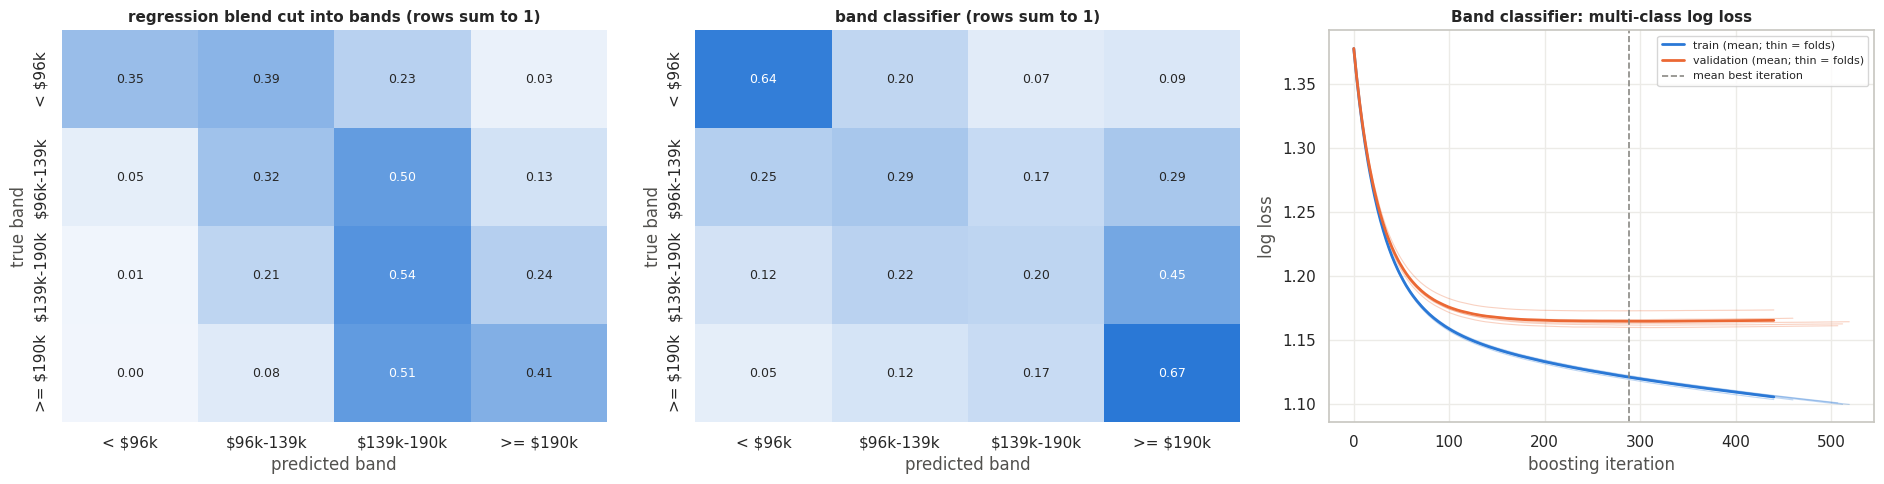

,accuracy,balanced accuracy,macro F1,within one band
regression blend cut into bands,0.4061,0.4063,0.4154,0.8809
band classifier,0.4495,0.4498,0.4310,0.8133


In [69]:
X_train_f, _ = fit_transform(train_idx)
clf_final = lgb.LGBMClassifier(n_estimators=max(20, int(np.mean(cls_iters) * 1.1)), learning_rate=cfg.LGB_LR, subsample_freq=1,
                               random_state=cfg.SEED, verbose=-1, n_jobs=cfg.N_JOBS, **cfg.LGB_PARAMS["log"]).fit(X_train_f, band[train_idx])
X_test_f = transform(df.iloc[test_idx], pipe["enc"])
band_test = band[test_idx]
band_pred = {"regression blend cut into bands": np.digitize(p_best, edges),
             "band classifier": clf_final.predict_proba(X_test_f).argmax(1)}
band_tab = pd.DataFrame({k: band_scores(band_test, v) for k, v in band_pred.items()}).T
rng = np.random.default_rng(cfg.SEED)
bp = band_pred["band classifier"]
acc_boot = [accuracy_score(band_test[i], bp[i]) for i in (rng.integers(0, len(bp), len(bp)) for _ in range(cfg.N_BOOT))]
BAND_ACC = band_tab.loc["band classifier", "accuracy"]
print(f"TEST band accuracy ({cfg.N_BANDS} bands): {BAND_ACC:.3f} [95% CI {np.percentile(acc_boot, 2.5):.3f}, "
      f"{np.percentile(acc_boot, 97.5):.3f}] | chance {1 / cfg.N_BANDS:.3f} | within one band "
      f"{band_tab.loc['band classifier', 'within one band']:.3f}")
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (k, v) in zip(axes[:2], band_pred.items()):
    cm = confusion_matrix(band_test, v, labels=range(cfg.N_BANDS), normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap=SEQ, vmin=0, vmax=1, ax=ax, cbar=False, xticklabels=BAND_NAMES,
                yticklabels=BAND_NAMES, annot_kws={"fontsize": 9})
    ax.set(title=f"{k} (rows sum to 1)", xlabel="predicted band", ylabel="true band")
for c in cls_curves:
    axes[2].plot(c["train"], color=TRAIN_C, lw=0.8, alpha=0.3)
    axes[2].plot(c["valid"], color=VAL_C, lw=0.8, alpha=0.3)
L = min(len(c["valid"]) for c in cls_curves)
axes[2].plot(np.mean([c["train"][:L] for c in cls_curves], axis=0), color=TRAIN_C, lw=2, label="train (mean; thin = folds)")
axes[2].plot(np.mean([c["valid"][:L] for c in cls_curves], axis=0), color=VAL_C, lw=2, label="validation (mean; thin = folds)")
axes[2].axvline(np.mean(cls_iters), color=GREY, ls="--", lw=1.2, label="mean best iteration")
axes[2].set(title="Band classifier: multi-class log loss", xlabel="boosting iteration", ylabel="log loss")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()
band_tab.round(4)

In [70]:
best_exact = band_tab["accuracy"].idxmax()
best_near = band_tab["within one band"].idxmax()
print(f"Findings: highest exact-band accuracy: {best_exact} ({band_tab.loc[best_exact, 'accuracy']:.3f}); highest within-one-band "
      f"accuracy: {best_near} ({band_tab.loc[best_near, 'within one band']:.3f}); chance {1 / cfg.N_BANDS:.3f}.")

Findings: highest exact-band accuracy: band classifier (0.449); highest within-one-band accuracy: regression blend cut into bands (0.881); chance 0.250.


## 24. What drives the predictions: SHAP and LIME

Three views of the same question, from exact to approximate.

### SHAP: global importance

SHAP additivity check (sum of contributions + base = model output): True


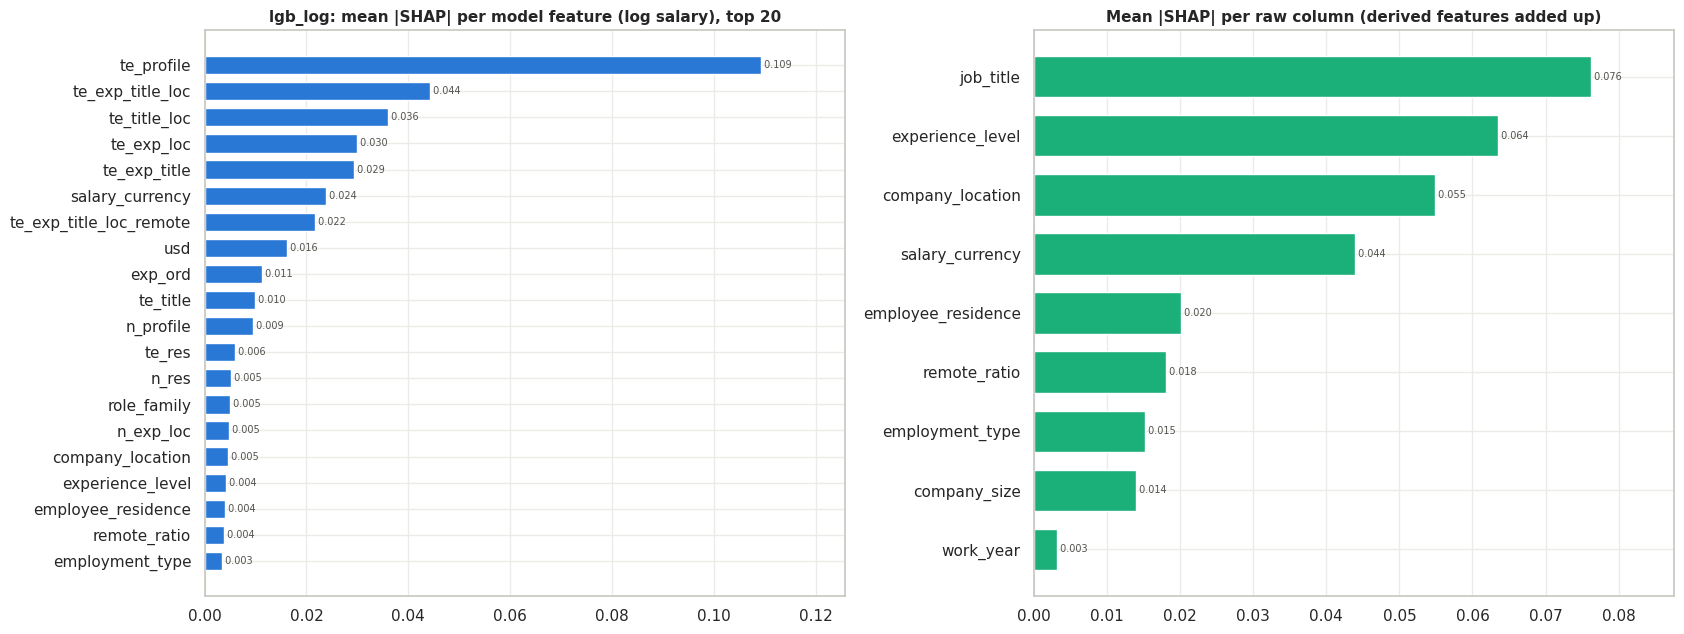

In [71]:
import shap

lgb_final = pipe["models"]["lgb_log"]["model"]
shap_idx = np.sort(np.random.default_rng(cfg.SEED).choice(len(test_idx), min(len(test_idx), cfg.SHAP_ROWS), replace=False))
Xs = X_test_f.iloc[shap_idx]
contrib = lgb_final.predict(Xs, pred_contrib=True)
sv, base = contrib[:, :-1], contrib[:, -1]
print("SHAP additivity check (sum of contributions + base = model output):",
      bool(np.allclose(sv.sum(1) + base, lgb_final.predict(Xs), atol=1e-6)))
cat_cols = [c for c in Xs.columns if isinstance(Xs[c].dtype, pd.CategoricalDtype)]
X_codes = Xs.assign(**{c: Xs[c].cat.codes for c in cat_cols}).astype(float)
X_disp = Xs.assign(**{c: Xs[c].astype(str) for c in cat_cols}).round(3).astype(object)
expl = shap.Explanation(values=sv, base_values=base, data=X_codes.values, display_data=X_disp.values,
                        feature_names=list(Xs.columns))

RAW = ["job_title", "experience_level", "company_location", "employee_residence", "salary_currency", "work_year",
       "remote_ratio", "company_size", "employment_type"]
SINGLE = {"work_year": ["work_year"], "remote_ratio": ["remote_ratio"], "exp_ord": ["experience_level"],
          "experience_level": ["experience_level"], "size_ord": ["company_size"], "company_size": ["company_size"],
          "res_eq_loc": ["employee_residence", "company_location"], "is_us": ["company_location"], "usd": ["salary_currency"],
          "salary_currency": ["salary_currency"], "employment_type": ["employment_type"],
          "employee_residence": ["employee_residence"], "res_region": ["employee_residence"],
          "company_location": ["company_location"], "region": ["company_location"]}


def raw_sources(f):
    if f.startswith(("te_", "n_")):
        return TE_GROUPS[f.split("_", 1)[1]]
    return SINGLE.get(f, ["job_title"])


SPLIT = np.zeros((len(Xs.columns), len(RAW)))
for i, f in enumerate(Xs.columns):
    src = raw_sources(f)
    for s in src:
        SPLIT[i, RAW.index(s)] = 1 / len(src)
raw_sv = sv @ SPLIT
shap_mean = pd.Series(np.abs(sv).mean(0), index=Xs.columns).sort_values(ascending=False)
raw_mean = pd.Series(np.abs(raw_sv).mean(0), index=RAW).sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
hbar(ax[0], shap_mean.index[:20].tolist(), shap_mean.values[:20], fmt="{:.3f}")
ax[0].set(title="lgb_log: mean |SHAP| per model feature (log salary), top 20")
hbar(ax[1], raw_mean.index.tolist(), raw_mean.values, color=PAL[2], fmt="{:.3f}")
ax[1].set(title="Mean |SHAP| per raw column (derived features added up)")
plt.tight_layout()
plt.show()

SHAP splits each prediction of the LightGBM model (log salary) into additive contributions, one per feature,
starting from the average prediction. The values are exact for tree models. The right panel adds the contributions of
every feature built from the same raw column. Encodings that combine several columns are split equally between them.

### SHAP: beeswarm

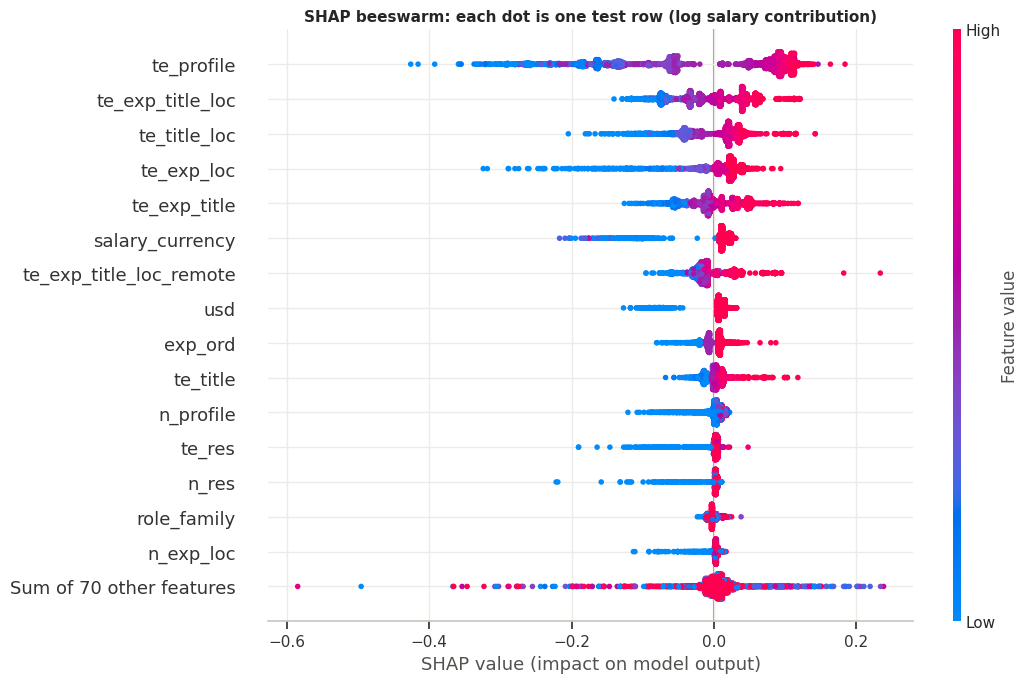

In [72]:
shap.plots.beeswarm(expl, max_display=16, show=False, plot_size=(11, 7))
plt.title("SHAP beeswarm: each dot is one test row (log salary contribution)")
plt.tight_layout()
plt.show()

Each dot is a test row. Its position is how much that feature moved the prediction, and its colour is the
feature value. For target encodings (`te_*`), high values mean "this group earns more", so red dots on the right are
expected. For categorical columns the colour is only a category code and carries no order.

### SHAP: dependence

How the contribution of the top numeric features changes with their value. How to read: each dot is a test row, placed by the feature value and its SHAP contribution, coloured by experience.
Rows whose group is small or unseen get an encoding pulled toward the overall mean log salary, which can show up as a
vertical stripe of points at that value.

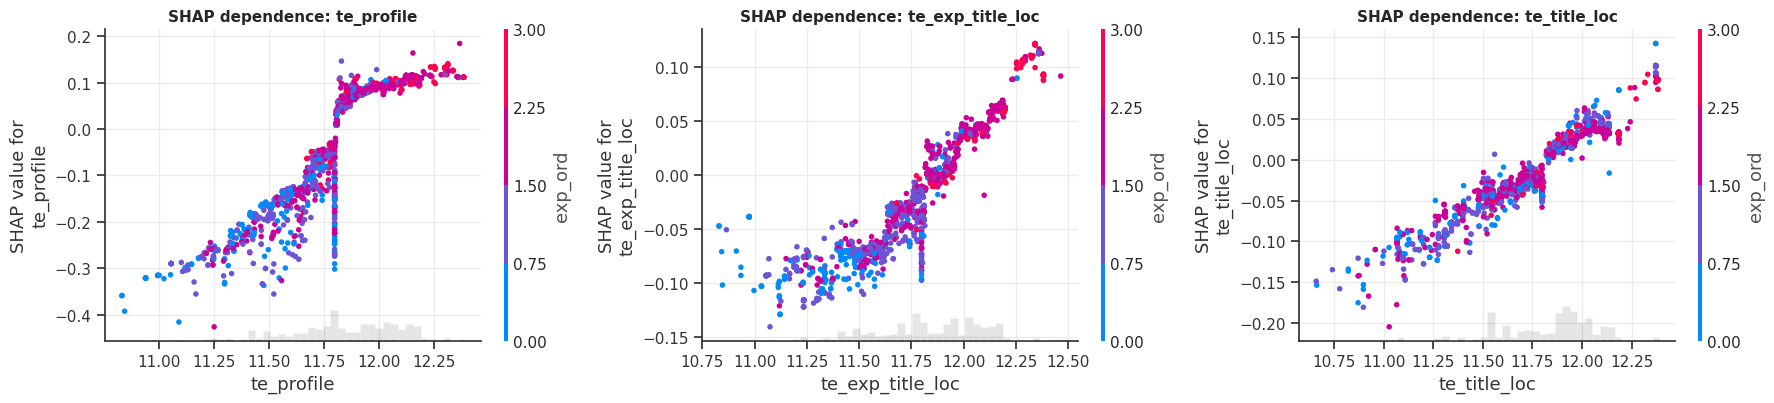

In [73]:
num_feats = [f for f in shap_mean.index if f not in cat_cols and X_codes[f].nunique() > 2][:3]
fig, axes = plt.subplots(1, len(num_feats), figsize=(6 * len(num_feats), 4.2))
for ax, f in zip(np.atleast_1d(axes), num_feats):
    shap.plots.scatter(expl[:, f], color=expl[:, "exp_ord"] if f != "exp_ord" else None, ax=ax, show=False)
    ax.set_title(f"SHAP dependence: {f}")
plt.tight_layout()
plt.show()

### SHAP: three individual predictions

A low, a typical and a high prediction from the test rows.

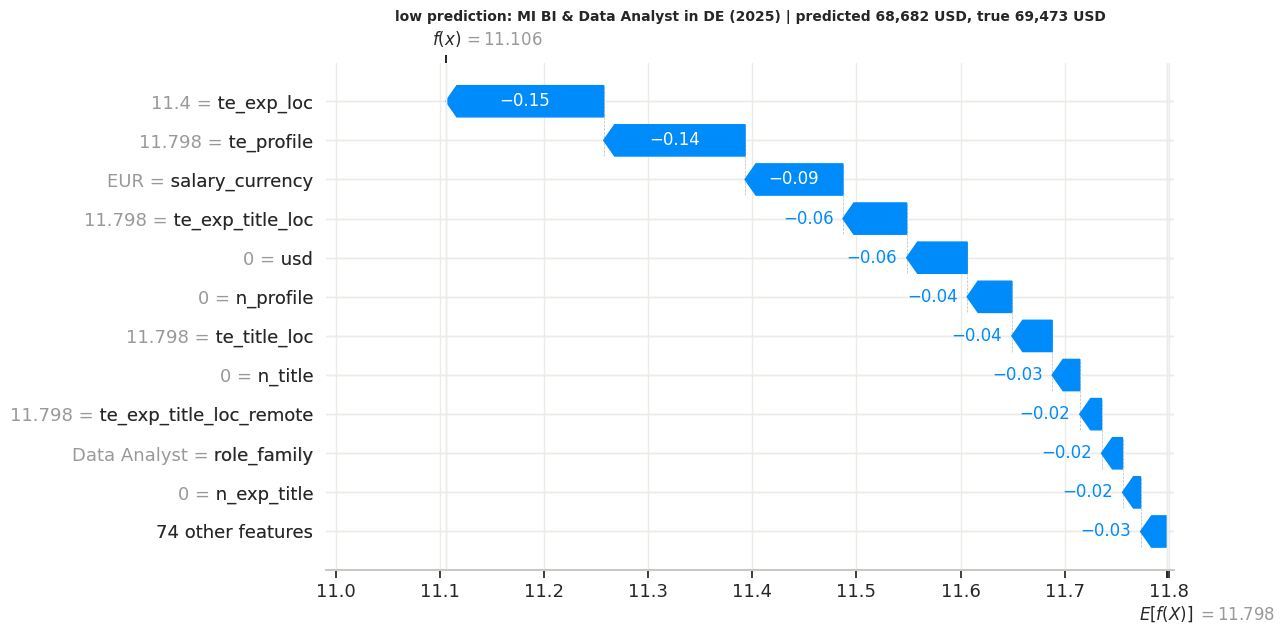

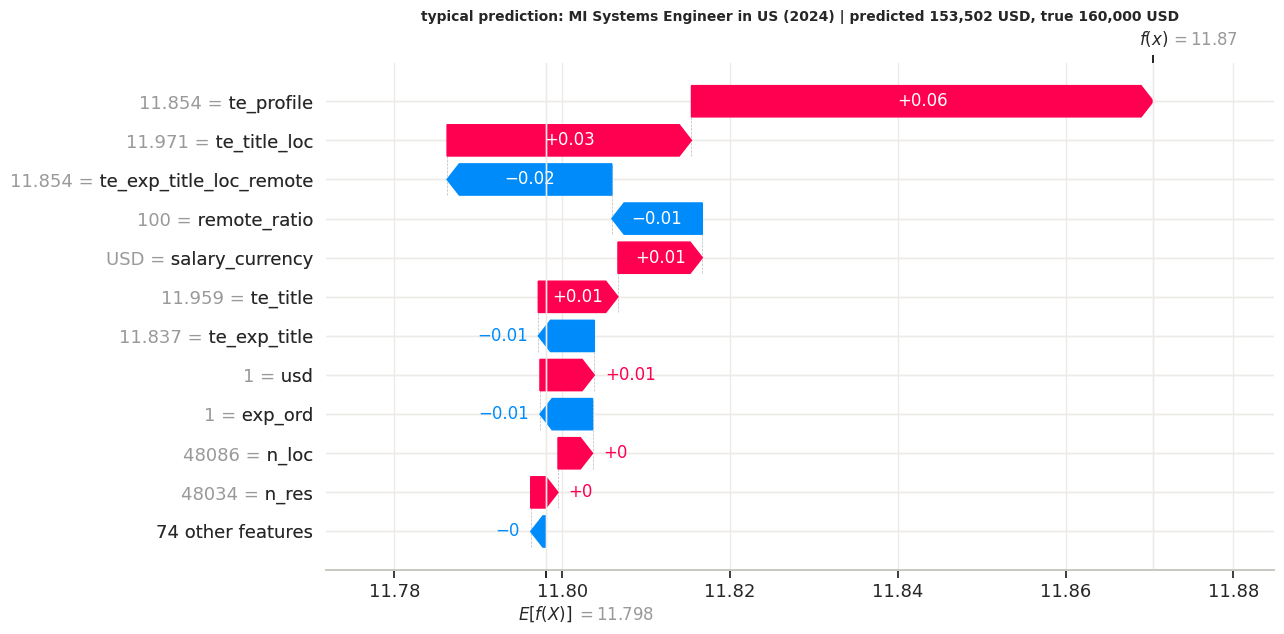

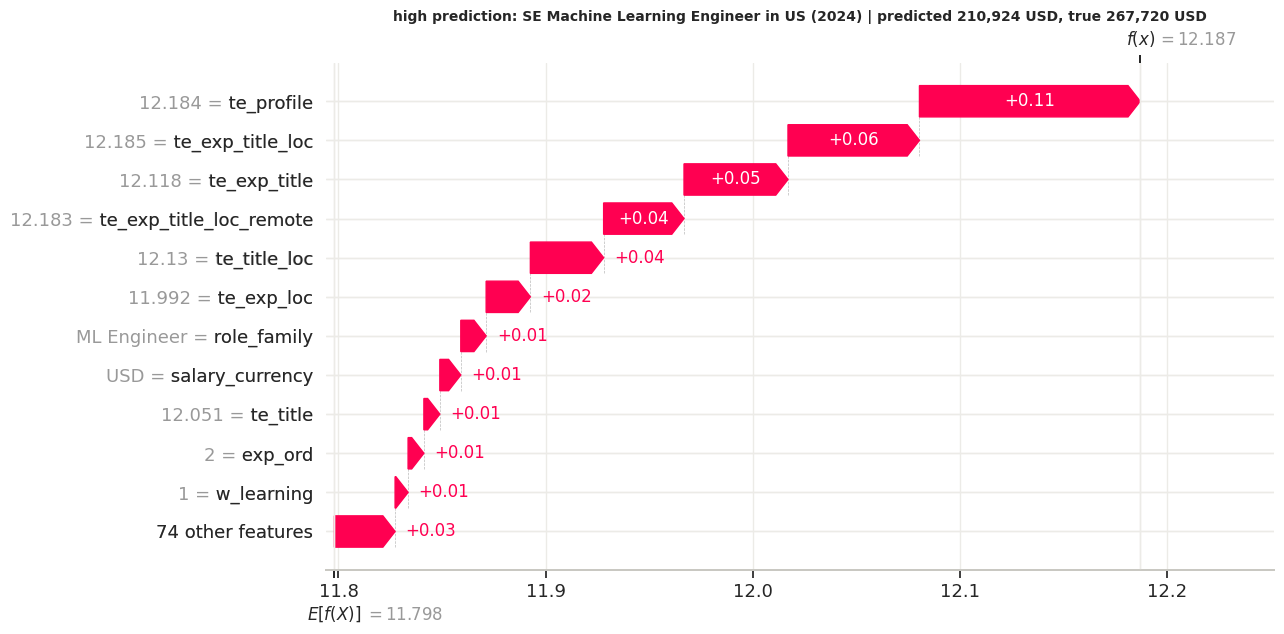

In [74]:
pred_s = p_best[shap_idx]
picks = [int(np.argsort(pred_s)[int(q * (len(pred_s) - 1))]) for q in (0.05, 0.5, 0.95)]
EXAMPLES = shap_idx[picks]
for label, i, row in zip(["low", "typical", "high"], picks, EXAMPLES):
    r = df.iloc[test_idx[row]]
    shap.plots.waterfall(expl[i], max_display=12, show=False)
    plt.gcf().set_size_inches(13, 6.5)  # wider bars so the contribution labels are not clipped
    plt.title(f"{label} prediction: {r['experience_level']} {r['job_title']} in {r['company_location']} ({r['work_year']}) | "
              f"predicted {p_best[row]:,.0f} USD, true {y_test[row]:,.0f} USD", fontsize=10)
    plt.tight_layout()
    plt.show()

A waterfall starts from the average log salary of the model, `E[f(X)]`, and adds each contribution until it
reaches this person's prediction, `f(x)`. The blend's dollar prediction in the title also includes the CatBoost model and
the back-transform from log salary.

### SHAP: does CatBoost agree?

Ranks the raw columns by the SHAP values of the CatBoost model and compares the ranking with LightGBM's.

In [75]:
cat_final = pipe["models"]["cat_raw"]["model"]
cat_sv = cat_final.get_feature_importance(to_pool(Xs), type="ShapValues")[:, :-1]
cat_raw_mean = pd.Series(np.abs(cat_sv @ SPLIT).mean(0), index=RAW)
rho = stats.spearmanr(raw_mean.loc[RAW], cat_raw_mean.loc[RAW]).statistic
print(f"CatBoost (dollars) vs LightGBM (log salary): Spearman rank correlation of raw-column importance {rho:.3f}")

CatBoost (dollars) vs LightGBM (log salary): Spearman rank correlation of raw-column importance 1.000


### Permutation importance

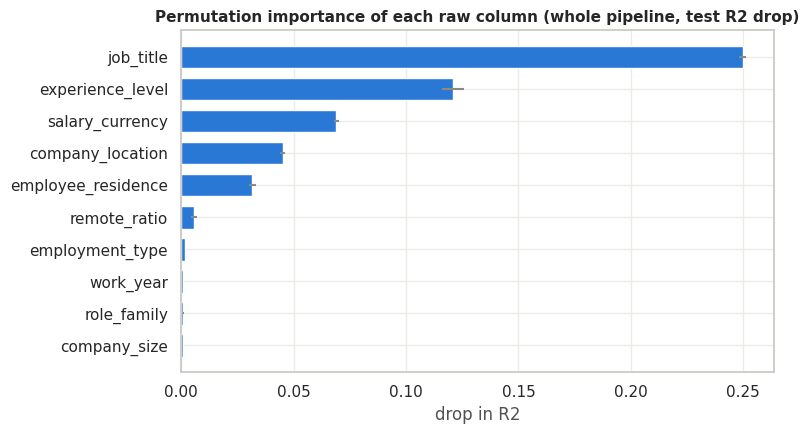

,raw column,R2 drop,sd
0,job_title,0.2496,0.0014
1,experience_level,0.1208,0.0047
4,salary_currency,0.0689,0.0011
2,company_location,0.0451,0.0011
3,employee_residence,0.0316,0.0016
6,remote_ratio,0.0057,0.0013
8,employment_type,0.0017,0.0001
5,work_year,0.0009,0.0001
9,role_family,0.0009,0.0002
7,company_size,0.0008,0.0002


In [76]:
rng = np.random.default_rng(cfg.SEED)
perm_rows = []
test_frame = df.iloc[test_idx]
for c in ["job_title", "experience_level", "company_location", "employee_residence", "salary_currency", "work_year",
          "remote_ratio", "company_size", "employment_type", "role_family"]:
    drops = []
    for _ in range(cfg.PERM_REPEATS):
        shuffled = test_frame.copy()
        shuffled[c] = rng.permutation(shuffled[c].values)
        drops.append(FINAL["R2"] - r2_score(y_test, predict_pipeline(pipe, shuffled)["blend"]))
    perm_rows.append((c, np.mean(drops), np.std(drops)))
perm = pd.DataFrame(perm_rows, columns=["raw column", "R2 drop", "sd"]).sort_values("R2 drop", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(perm["raw column"][::-1], perm["R2 drop"][::-1], xerr=perm["sd"][::-1], color=PAL[0], height=0.7, ecolor=GREY)
ax.set(title="Permutation importance of each raw column (whole pipeline, test R2 drop)", xlabel="drop in R2")
plt.tight_layout()
plt.show()
perm.round(4)

SHAP values show how the boosted-tree model uses its engineered features. The permutation test works one level
higher: it shuffles one raw column in the test rows, rebuilds every feature derived from it (title words, encodings,
regions) and measures the drop in R2 of the whole blend. That answers the practical question "how much does the model
need this column?" without splitting credit between related features.

### LIME: the same three predictions

LIME explains one prediction of the whole blend on the raw columns. It changes the person's column values at random
(drawing each column the way it occurs in the training data), watches how the prediction moves, and fits a small linear
model around that person. Each bar reads as "keeping this value instead of a typical one changes the predicted salary by
x%". The local fit R2 in the title shows how well that linear model describes the blend near this person; a low value
means the bars are a rough story, not exact effects. LIME changes each column independently, so it also creates
combinations that never occur (for example a US company paying in rupees), and the model's answer to those is part of
what LIME measures.

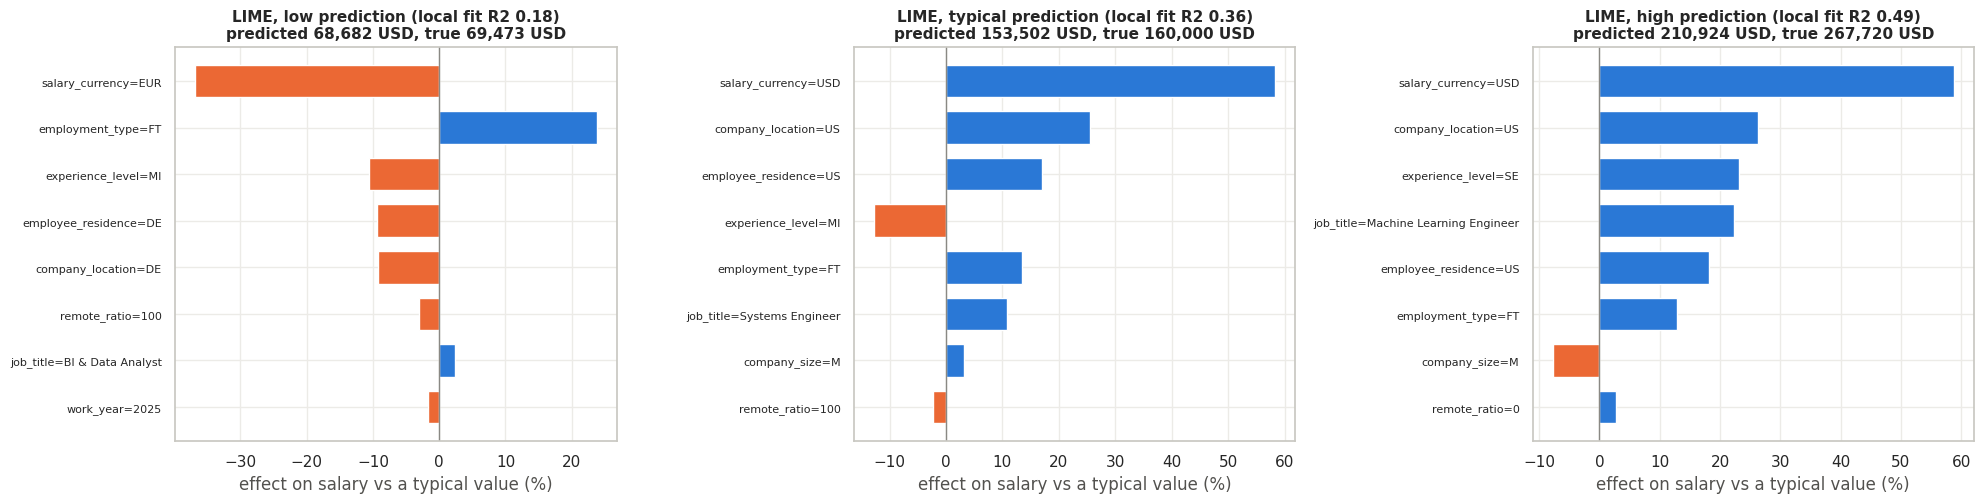

In [77]:
from lime.lime_tabular import LimeTabularExplainer

title_family = df.groupby("job_title")["role_family"].first()
levels = {c: sorted(df[c].astype(str).unique()) for c in RAW}


def to_codes(frame):
    return np.column_stack([pd.Categorical(frame[c].astype(str), categories=levels[c]).codes for c in RAW]).astype(float)


def from_codes(Z):
    d = pd.DataFrame({c: np.array(levels[c], dtype=object)[Z[:, j].astype(int)] for j, c in enumerate(RAW)})
    d["work_year"] = d["work_year"].astype(int)
    d["remote_ratio"] = d["remote_ratio"].astype(int)
    d["role_family"] = d["job_title"].map(title_family)
    return d


def lime_predict(Z):
    return np.log(np.clip(predict_pipeline(pipe, from_codes(Z))["blend"], 1000, None))


lime_bg = df.iloc[train_idx].sample(min(len(train_idx), 5000), random_state=cfg.SEED)
lime_explainer = LimeTabularExplainer(to_codes(lime_bg), mode="regression", feature_names=RAW,
                                      categorical_features=list(range(len(RAW))),
                                      categorical_names={j: levels[c] for j, c in enumerate(RAW)},
                                      discretize_continuous=False, random_state=cfg.SEED)


def lime_explain(row):
    return lime_explainer.explain_instance(to_codes(df.iloc[[test_idx[row]]])[0], lime_predict, num_features=len(RAW),
                                           num_samples=cfg.LIME_SAMPLES)


fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))
for ax, label, row in zip(axes, ["low", "typical", "high"], EXAMPLES):
    e = lime_explain(row)
    items = sorted(e.as_list(), key=lambda t: abs(t[1]))[-8:]
    names = [n if len(n) < 42 else n[:40] + ".." for n, _ in items]
    vals = [100 * (np.exp(w) - 1) for _, w in items]
    ax.barh(names, vals, color=[PAL[0] if v > 0 else PAL[1] for v in vals], height=0.7)
    ax.axvline(0, color=GREY, lw=1)
    ax.set(title=f"LIME, {label} prediction (local fit R2 {e.score:.2f})\npredicted {p_best[row]:,.0f} USD, true {y_test[row]:,.0f} USD",
           xlabel="effect on salary vs a typical value (%)")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

### Do the methods agree?

The four methods answer slightly different questions: SHAP explains one model exactly, LIME approximates the blend
locally, and permutation measures the loss in test R2. The Spearman table measures how similarly they rank the raw
columns. Methods that agree suggest the ranking is a property of the data rather than of one model or method.

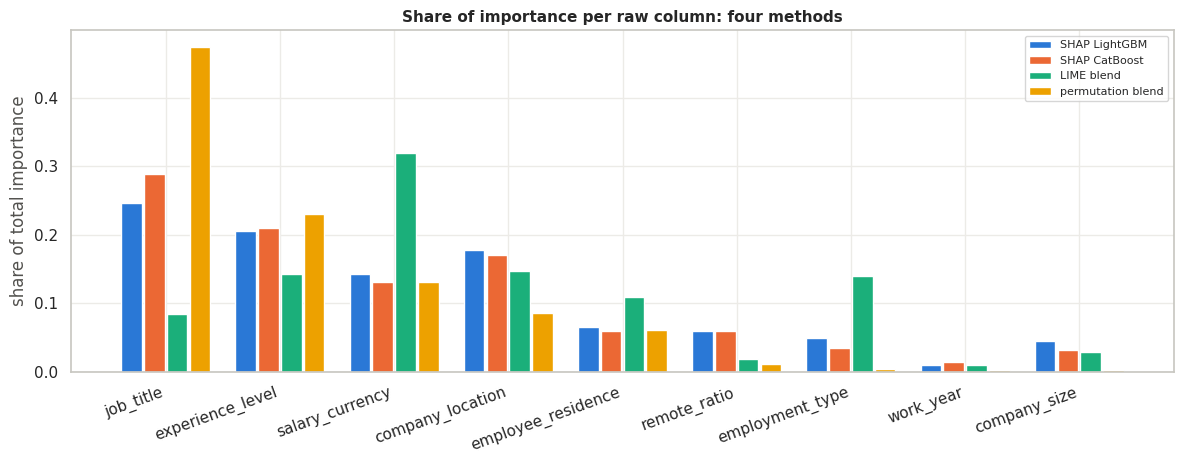

LIME local fit R2 over 30 test rows: median 0.40


,SHAP LightGBM,SHAP CatBoost,LIME blend,permutation blend
SHAP LightGBM,1.000,1.000,0.583,0.967
SHAP CatBoost,1.000,1.000,0.583,0.967
LIME blend,0.583,0.583,1.000,0.567
permutation blend,0.967,0.967,0.567,1.000


In [78]:
lime_rows = np.random.default_rng(cfg.SEED + 1).choice(len(test_idx), cfg.LIME_ROWS, replace=False)
lime_w = np.zeros((len(lime_rows), len(RAW)))
lime_fit = []
for k, row in enumerate(lime_rows):
    e = lime_explain(row)
    for j, w in e.local_exp[1]:
        lime_w[k, j] = w
    lime_fit.append(e.score)
imp = pd.DataFrame({"SHAP LightGBM": raw_mean.loc[RAW], "SHAP CatBoost": cat_raw_mean.loc[RAW],
                    "LIME blend": pd.Series(np.abs(lime_w).mean(0), index=RAW),
                    "permutation blend": perm.set_index("raw column")["R2 drop"].reindex(RAW).clip(lower=0)})
imp = imp / imp.sum()
imp = imp.sort_values("permutation blend", ascending=False)
fig, ax = plt.subplots(figsize=(12, 4.8))
w = 0.2
xs = np.arange(len(imp))
for k, col in enumerate(imp.columns):
    ax.bar(xs + (k - 1.5) * w, imp[col], width=w - 0.02, color=PAL[k], label=col)
ax.set_xticks(xs)
ax.set_xticklabels(imp.index, rotation=20, ha="right")
ax.set(title="Share of importance per raw column: four methods", ylabel="share of total importance")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
rho_tab = imp.corr(method="spearman").round(3)
print(f"LIME local fit R2 over {len(lime_rows)} test rows: median {np.median(lime_fit):.2f}")
rho_tab

In [79]:
others = [c for c in rho_tab.columns if c != "LIME blend"]
print("Findings:")
for m in imp.columns:
    print(f"- {m}: top 3 raw columns {imp[m].sort_values(ascending=False).index[:3].tolist()}")
print(f"- Spearman agreement: SHAP LightGBM vs permutation {rho_tab.loc['SHAP LightGBM', 'permutation blend']:.3f}; "
      f"LIME vs the other three (mean) {rho_tab.loc['LIME blend', others].mean():.3f}; median LIME local fit R2 {np.median(lime_fit):.2f}")

Findings:
- SHAP LightGBM: top 3 raw columns ['job_title', 'experience_level', 'company_location']
- SHAP CatBoost: top 3 raw columns ['job_title', 'experience_level', 'company_location']
- LIME blend: top 3 raw columns ['salary_currency', 'company_location', 'experience_level']
- permutation blend: top 3 raw columns ['job_title', 'experience_level', 'salary_currency']
- Spearman agreement: SHAP LightGBM vs permutation 0.967; LIME vs the other three (mean) 0.578; median LIME local fit R2 0.40


## 25. Saved outputs and using the model

In [80]:
import joblib

os.makedirs(cfg.OUT_DIR, exist_ok=True)
joblib.dump({"models": {n: f["model"] for n, f in pipe["models"].items()}, "smear": {n: f["smear"] for n, f in pipe["models"].items()},
             "encoders": pipe["enc"], "weights": dict(zip(cfg.MODELS, weights.tolist())), "iterations": N_FINAL,
             "interval_log_quantiles": {"lo": mq_lo.to_dict(), "hi": mq_hi.to_dict()}}, os.path.join(cfg.OUT_DIR, "salary_model.joblib"))
out = df.iloc[test_idx][PROFILE].assign(true_salary=y_test, predicted=np.round(p_final), lower=np.round(test_df["lo_m"].values),
                                        upper=np.round(test_df["hi_m"].values))
out.to_csv(os.path.join(cfg.OUT_DIR, "test_predictions.csv"), index_label="row")
metrics = {"test": FINAL_USED, "test_ci95": {"R2": ci[:, 0].tolist(), "MAE": ci[:, 1].tolist(), "RMSE": ci[:, 2].tolist()},
           "cv": cv_table.loc["blend"].to_dict(), "repeated_splits": rep[["blend R2", "blend MAE", "blend RMSE"]].agg(["mean", "std"]).to_dict(),
           "time_split": time_table.loc["blend"].to_dict(), "noise_ceiling_r2": CEILING_R2, "weights": dict(zip(cfg.MODELS, weights.tolist())),
           "groups_flagged": int(audit["flag"].sum()), "bias_fix": best_fix if use_fix else "none",
           "interval_coverage": coverage(test_df["lo_m"], test_df["hi_m"], test_df["true"]),
           "tolerance_accuracy_pct": tol_tab["blend"].to_dict(), "band_edges": edges.tolist(),
           "band_test": band_tab.to_dict(orient="index"), "smoke": SMOKE,
           "runtime_min": round((time.time() - START) / 60, 1)}
with open(os.path.join(cfg.OUT_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2, default=float)
print("saved salary_model.joblib, test_predictions.csv and metrics.json to", cfg.OUT_DIR)
print(f"total runtime {metrics['runtime_min']} min")

saved salary_model.joblib, test_predictions.csv and metrics.json to /kaggle/working
total runtime 11.7 min


Files in the output folder:
- `salary_model.joblib`: the fitted LightGBM and CatBoost models, target encoders, smearing factors, blend weights,
  iteration counts and the interval quantiles. Rebuilding predictions also needs the feature functions of section 15.
- `test_predictions.csv`: every test row with its profile, true salary, prediction and 90% interval.
- `metrics.json`: all headline and supplementary scores of this run.

### Predict new profiles

The same functions score any new profile. The third profile uses a title that is not in the training data, to show
how such a case is handled; section 20 measures how much accuracy the model loses on unseen titles.

In [81]:
title_family = df.groupby("job_title")["role_family"].first()
new_people = pd.DataFrame([
    {"work_year": 2025, "experience_level": "SE", "employment_type": "FT", "job_title": "Machine Learning Engineer",
     "salary_currency": "USD", "employee_residence": "US", "remote_ratio": 0, "company_location": "US", "company_size": "M"},
    {"work_year": 2025, "experience_level": "EN", "employment_type": "FT", "job_title": "Data Analyst",
     "salary_currency": "EUR", "employee_residence": "DE", "remote_ratio": 100, "company_location": "DE", "company_size": "M"},
    {"work_year": 2025, "experience_level": "MI", "employment_type": "FT", "job_title": "Prompt Engineer for LLM Agents",
     "salary_currency": "USD", "employee_residence": "US", "remote_ratio": 100, "company_location": "US", "company_size": "L"},
])
new_people["role_family"] = new_people["job_title"].map(title_family).fillna("Other / Unclassified")
pred_new = predict_pipeline(pipe, new_people)["blend"]
new_people["predicted"] = np.round(pred_new, -2)
new_people["lower 90%"] = np.round(pred_new * np.exp(new_people["experience_level"].map(mq_lo).values), -2)
new_people["upper 90%"] = np.round(pred_new * np.exp(new_people["experience_level"].map(mq_hi).values), -2)
new_people["title seen in training"] = new_people["job_title"].isin(set(df.iloc[train_idx]["job_title"]))
new_people[["job_title", "experience_level", "company_location", "predicted", "lower 90%", "upper 90%", "title seen in training"]]

,job_title,experience_level,company_location,predicted,lower 90%,upper 90%,title seen in training
0,Machine Learning Engineer,SE,US,215200.0,108300.0,357000.0,True
1,Data Analyst,EN,DE,59700.0,27300.0,108700.0,True
2,Prompt Engineer for LLM Agents,MI,US,125400.0,61000.0,222000.0,False


## 26. Conclusions

Everything below is computed from the outputs above.

In [82]:
scorecard = pd.DataFrame({
    "5-fold CV (training rows)": cv_table.loc["blend", MAIN],
    "hold-out test (scored once)": pd.Series(FINAL_USED)[MAIN],
    f"{len(rep)} repeated random splits (mean)": pd.Series({"R2": rep["blend R2"].mean(), "MAE": rep["blend MAE"].mean(),
                                                            "RMSE": rep["blend RMSE"].mean()}),
    f"time split (train before {last}, test {last})": time_table.loc["blend", MAIN],
    "reference: hierarchical means (test)": test_table.loc["hierarchical means", MAIN]}).T
scorecard["R2"] = scorecard["R2"].round(4)
scorecard[["MAE", "RMSE"]] = scorecard[["MAE", "RMSE"]].round(0)
print("Headline metrics (regression, dollars):")
display(scorecard)
lines = [
    f"Rows: {len(df):,}; distinct profiles: {n_prof:,}. Leaks removed: salary, salary_outlier_flag. Copies removed: 4 columns.",
    f"Noise ceiling (oracle R2 with the true salaries of each profile): {CEILING_R2:.3f}.",
    f"Test (scored once): R2 {FINAL_USED['R2']:.4f}, MAE ${FINAL_USED['MAE']:,.0f}, RMSE ${FINAL_USED['RMSE']:,.0f}, "
    f"MAPE {FINAL_USED['MAPE']:.1%}, {FINAL_USED['within_20pct']:.1%} of predictions within 20% of the true salary.",
    f"Best simple reference (hierarchical means) on the same test: R2 {test_table.loc['hierarchical means', 'R2']:.4f}.",
    f"Repeated random splits: R2 {rep['blend R2'].mean():.4f} +- {rep['blend R2'].std():.4f} (lowest {rep['blend R2'].min():.4f}); "
    f"model seeds: +- {seeds_tab['R2'].std():.5f}.",
    f"Time split (train before {last}, test {last}): R2 {time_table.loc['blend', 'R2']:.4f}.",
    f"Bias audit: {int(audit['flag'].sum())} of {len(audit)} groups flagged beyond +-{cfg.BIAS_TOL}%; {len(unsure)} small groups have a "
    f"point estimate beyond it without being flagged ({n_probable} probably biased with an uncertain size); "
    f"correction applied: {use_fix}.",
    f"{cfg.PI_LEVEL:.0%} prediction intervals cover {coverage(test_df['lo_m'], test_df['hi_m'], test_df['true']):.1%} of test salaries; "
    f"lowest group coverage {pi_tab['coverage (per experience level)'].min():.1%} "
    f"({pi_tab.loc[pi_tab['coverage (per experience level)'].idxmin(), 'group']}).",
    f"New job titles (unseen variants): R2 {r2_score(y_test, p_unseen):.4f}; the model leans heavily on known titles.",
    f"Supplementary: {tol_tab.loc['within +-20%', 'blend']:.1f}% of predictions within 20% of the true salary; "
    f"salary-band accuracy {100 * BAND_ACC:.1f}% ({cfg.N_BANDS} bands, chance {100 / cfg.N_BANDS:.0f}%).",
]
print("\n".join("- " + s for s in lines))

Headline metrics (regression, dollars):


,R2,MAE,RMSE
5-fold CV (training rows),0.3093,46110.0,64172.0
hold-out test (scored once),0.3071,46368.0,64757.0
5 repeated random splits (mean),0.3088,46063.0,64041.0
"time split (train before 2025, test 2025)",0.2922,47080.0,66045.0
reference: hierarchical means (test),0.2811,47593.0,65962.0


- Rows: 71,913; distinct profiles: 5,934. Leaks removed: salary, salary_outlier_flag. Copies removed: 4 columns.
- Noise ceiling (oracle R2 with the true salaries of each profile): 0.357.
- Test (scored once): R2 0.3071, MAE $46,368, RMSE $64,757, MAPE 35.9%, 39.0% of predictions within 20% of the true salary.
- Best simple reference (hierarchical means) on the same test: R2 0.2811.
- Repeated random splits: R2 0.3088 +- 0.0052 (lowest 0.3038); model seeds: +- 0.00005.
- Time split (train before 2025, test 2025): R2 0.2922.
- Bias audit: 0 of 35 groups flagged beyond +-5.0%; 5 small groups have a point estimate beyond it without being flagged (3 probably biased with an uncertain size); correction applied: False.
- 90% prediction intervals cover 89.8% of test salaries; lowest group coverage 79.2% (PT).
- New job titles (unseen variants): R2 0.1940; the model leans heavily on known titles.
- Supplementary: 39.0% of predictions within 20% of the true salary; salary-band accuracy 44.9% (4 

---

**Md. Samir Hossain**

- GitHub: [github.com/SamirHossain2001](https://github.com/SamirHossain2001)
- Email: [2001samirhossain@gmail.com](mailto:2001samirhossain@gmail.com)

Questions, corrections and suggestions are welcome in the comments or by email.